# Predicting lost-time mine injuries from MSHA open data

| | |
|---|---|
| **Module** | 6COSC017C Machine Learning and Data Analytics, Coursework 1 (CW1), WIUT |
| **Student ID** | 13130 |
| **Data snapshot** | MSHA Open Government Data, pulled 14 October 2026, 12:06 UTC (`2026-10-14T12:06:01Z` in `data/raw/SNAPSHOT.json`); the three data archives were published by MSHA on 9 October 2026 |
| **Task** | Binary classification: for each injured person on an MSHA Form 7000-1 (accident years 2010-2025, N = 101,609) predict whether the case is a *lost-time injury* (`lost_time` = 1, 48.6 % of cases) or not |
| **Models** | Logistic regression, k-nearest neighbours, Gaussian naive Bayes, decision tree, random forest, histogram gradient boosting, RBF support vector machine, multi-layer perceptron, compared against four reference rules |
| **Features** | 55 model inputs: 23 categorical, 20 numeric, 12 binary |

**Contents.** [A. Load dataset](#A.-Load-dataset) | [B. Exploratory data analysis](#B.-Exploratory-data-analysis) |
[C. Data preparation](#C.-Data-preparation) | [D. Model training](#D.-Model-training) |
[E. Model evaluation](#E.-Model-evaluation) | [F. Deployment and reproducibility](#F.-Deployment-and-reproducibility)

**Reading guide.** The notebook follows the structure of the brief: **A** loads and joins the data,
**B** explores the training rows, **C** prepares the data, **D** trains and tunes the models,
**E** evaluates them on the held-out test fold and **F** describes deployment and reproducibility.
Every group of code cells is preceded by a markdown cell that says why the step is needed and
what the output shows. Numbers that depend on the model runs are printed by the code and are not
typed into the text.

**How to run.**

```
uv sync --locked --all-groups
uv run mlda-download      # fetch the raw MSHA files and verify their SHA-256 hashes
uv run mlda-train         # the full study, with the temporal and sensitivity studies (about an hour and a half on 8 cores)
uv run python notebooks/build_notebook.py
uv run jupyter nbconvert --to notebook --execute --inplace notebooks/01_end_to_end.ipynb
```

**The `FULL_RUN` switch.** By default (variable unset) the notebook runs the hyper-parameter
search itself, with `mlda.tuning.tune`, for the three models whose search is cheap (Gaussian
naive Bayes, logistic regression and the decision tree) and checks that it reproduces the tables
stored by `uv run mlda-train`. For the other five models (k-nearest neighbours, random forest,
histogram gradient boosting, support vector machine and perceptron) it loads the stored
cross-validation tables and selected hyper-parameters. It then refits every selected pipeline on
the training split, so training happens here, and the whole notebook runs in under ten minutes on eight workers (section F.6 lists the stage times of the executed run). With
`FULL_RUN=1` (PowerShell: `$env:FULL_RUN = "1"`) the notebook repeats all eight grid and
randomised searches itself, which takes about an hour.

In [1]:
%matplotlib inline
import gc
import io
import json
import logging
import os
import platform
import sys
import time
import warnings
from concurrent.futures import ThreadPoolExecutor

# Quiet the library chatter that is not about the data: sklearn and pandas FutureWarnings.
warnings.simplefilter("ignore", FutureWarning)
warnings.simplefilter("ignore", DeprecationWarning)
os.environ["PYTHONWARNINGS"] = "ignore::FutureWarning,ignore::DeprecationWarning"  # worker processes too

# The filters have to be active before the libraries are imported, so these imports follow them (E402).
import matplotlib  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import scipy  # noqa: E402
import seaborn as sns  # noqa: E402
import sklearn  # noqa: E402
import statsmodels  # noqa: E402
from IPython.display import Image, Markdown, display  # noqa: E402

import mlda  # noqa: E402
from mlda.config import PROJECT_ROOT, RANDOM_STATE, STUDENT_ID  # noqa: E402
from mlda.pipeline import StageTimer  # noqa: E402

matplotlib.rcParams["figure.dpi"] = 120      # sharper inline figures than the 72 dpi default
pd.set_option("display.float_format", "{:,.3f}".format)   # every table rounded to 3 decimals
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)

FULL_RUN = os.environ.get("FULL_RUN") == "1"
timer = StageTimer()          # wall-clock seconds per stage, summarised in the last cell
NOTEBOOK_STARTED = time.perf_counter()


def show(fig, alt: str = "Figure") -> None:
    # Figures from mlda.plots are matplotlib Figure objects. They are rendered to PNG with a text
    # description, so that the HTML export carries alternative text for every image.
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", bbox_inches="tight", dpi=fig.dpi)
    display(Image(data=buffer.getvalue(), format="png", alt=alt))


def note(text: str) -> None:
    display(Markdown(text))


def show_table(frame: pd.DataFrame, caption: str | None = None) -> None:
    if caption:
        note(f"**{caption}**")
    display(frame)


with open(PROJECT_ROOT / "data" / "raw" / "SNAPSHOT.json", encoding="utf-8") as handle:
    SNAPSHOT_UTC = json.load(handle)["snapshot_utc"]

environment = pd.DataFrame(
    {
        "value": {
            "Python": platform.python_version(),
            "platform": platform.platform(),
            "CPU cores": os.cpu_count(),
            "numpy": np.__version__,
            "pandas": pd.__version__,
            "scipy": scipy.__version__,
            "scikit-learn": sklearn.__version__,
            "statsmodels": statsmodels.__version__,
            "matplotlib": matplotlib.__version__,
            "seaborn": sns.__version__,
            "mlda (this project)": getattr(mlda, "__version__", "0.1.0"),
            "RANDOM_STATE": RANDOM_STATE,
            "STUDENT_ID": STUDENT_ID,
            "FULL_RUN": FULL_RUN,
            "data snapshot (UTC)": SNAPSHOT_UTC,
            "project root": str(PROJECT_ROOT),
        }
    }
)
environment["value"] = environment["value"].astype(str)
display(environment)

,value
Python,3.12.15
platform,Windows-11-10.0.26200-SP0
CPU cores,20
numpy,2.5.4
pandas,2.3.3
scipy,1.18.1
scikit-learn,1.9.1
statsmodels,0.15.0
matplotlib,3.11.2
seaborn,0.13.2


# A. Load dataset

The study uses three open-data tables from the US Mine Safety and Health Administration (MSHA).
They form a hierarchy: **Mines** holds one row per mine, **MinesProdYearly** holds the employee
hours of each mine, year and subunit (Form 7000-2), and **Accidents** holds one row per injured
person on a Form 7000-1. The unit of analysis is the injured person, so *Accidents* is the left
table and each of the other two is attached with a **left join**, which cannot drop an accident.
Every join has to be many-to-one (many accidents per mine, many accidents per mine-year), and the
cells below check that, count the matches and record what happens to the rows that do not match.

## A.1 Raw files and checksums

MSHA replaces these files every week, so a rerun next month would silently analyse different
rows. `ensure_raw_files()` recomputes the SHA-256 hash of every file and compares it with the
hash pinned in `mlda.config.SOURCES`; it downloads a file only if it is missing, and refuses one
whose hash differs. The table shows the verification result for the snapshot used in this work.

In [2]:
from mlda.config import RAW_DIR, SOURCES
from mlda.data.download import ensure_raw_files, sha256_of

raw_paths = ensure_raw_files()     # verifies every SHA-256 against the pinned value; downloads only if needed
rows = []
for key, source in SOURCES.items():
    actual = sha256_of(source.path)
    rows.append(
        {
            "source": key,
            "file": source.filename,
            "size (MB)": round(source.path.stat().st_size / 1e6, 2),
            "sha256 (first 12)": actual[:12],
            "matches pinned hash": actual == source.sha256,
        }
    )
checksums = pd.DataFrame(rows)
show_table(checksums, "Raw files verified against the pinned SHA-256 hashes")
assert checksums["matches pinned hash"].all(), "a raw file differs from the analysed snapshot"

with open(RAW_DIR / "SNAPSHOT.json", encoding="utf-8") as handle:
    snapshot = json.load(handle)
print("snapshot taken (UTC):", snapshot["snapshot_utc"])
for name in ("Accidents.zip", "Mines.zip", "MinesProdYearly.zip"):
    print(f"  {name:22s} published by MSHA: {snapshot[name]['last_modified']}")

**Raw files verified against the pinned SHA-256 hashes**

,source,file,size (MB),sha256 (first 12),matches pinned hash
0,accidents,Accidents.zip,52.270,62d0c861a5c3,True
1,mines,Mines.zip,7.310,1a0957ff0049,True
2,production,MinesProdYearly.zip,7.070,c0fdca86d175,True
3,accidents_codebook,Accidents_Definition_File.txt,0.010,c7681808dd37,True
4,mines_codebook,Mines_Definition_File.txt,0.010,efd2bc2c4932,True
5,production_codebook,MinesProdYearly_Definition_File.txt,0.000,2931d666cf83,True


snapshot taken (UTC): 2026-10-14T12:06:01Z
  Accidents.zip          published by MSHA: Fri, 09 Oct 2026 11:12:32 GMT
  Mines.zip              published by MSHA: Fri, 09 Oct 2026 11:12:35 GMT
  MinesProdYearly.zip    published by MSHA: Fri, 09 Oct 2026 11:12:36 GMT


## A.2 Load the three tables

`mlda.data.load` reads each pipe-delimited file as text first (so that nothing is coerced
silently), strips padding, turns the MSHA placeholders (`?`, `NO VALUE FOUND`, blanks) into real
missing values and then converts the columns that the codebook declares as numbers or dates. The
cells print the shape and the data types of each table and the first rows, which is the first
check that the parsing did what the codebook says.

In [3]:
from mlda.data import load

with timer.stage("A.2 load the three tables"):
    accidents = load.load_accidents()
    mines = load.load_mines()
    production = load.load_production()

tables = {
    "Accidents": (accidents, "DOCUMENT_NO", "one injured person on one Form 7000-1"),
    "Mines": (mines, "MINE_ID", "one mine (attributes as of the snapshot)"),
    "MinesProdYearly": (production, "MINE_ID + CALENDAR_YR + SUBUNIT_CD", "one mine, year and subunit"),
}
overview = pd.DataFrame(
    [
        {
            "table": name,
            "rows": len(frame),
            "columns": frame.shape[1],
            "primary key": key,
            "grain": grain,
            "memory (MB)": round(frame.memory_usage(deep=True).sum() / 1e6),
        }
        for name, (frame, key, grain) in tables.items()
    ]
).set_index("table")
show_table(overview, "Shape of the three tables")

dtype_counts = pd.concat(
    {name: frame.dtypes.astype(str).value_counts() for name, (frame, _, _) in tables.items()}, axis=1
).fillna(0).astype(int)
show_table(dtype_counts, "Columns per data type (object = text)")

**Shape of the three tables**

,rows,columns,primary key,grain,memory (MB)
table,,,,,
Accidents,275220,57,DOCUMENT_NO,one injured person on one Form 7000-1,726
Mines,92060,59,MINE_ID,one mine (attributes as of the snapshot),214
MinesProdYearly,658922,11,MINE_ID + CALENDAR_YR + SUBUNIT_CD,"one mine, year and subunit",256


**Columns per data type (object = text)**

,Accidents,Mines,MinesProdYearly
object,43,43,6
float64,6,11,1
Int64,4,0,1
datetime64[ns],3,3,0
int64,1,2,3


In [4]:
from mlda.data.schema import PERSIST_DROP_COLUMNS

# Company names and free text (narratives, directions) are left out of the displays; they are
# not features and are not stored in the processed data either. Transposed so that the columns read down the page.
accident_view = accidents.drop(columns=[c for c in PERSIST_DROP_COLUMNS if c in accidents.columns])
show_table(accident_view.head(3).T, "Accidents.head(3), transposed (names and narrative omitted)")
mine_columns = [
    "MINE_ID", "COAL_METAL_IND", "CURRENT_MINE_TYPE", "CURRENT_MINE_STATUS", "STATE", "DISTRICT", "PRIMARY_SIC",
    "PRIMARY_CANVASS", "CURRENT_103I", "CURRENT_103I_DT", "PORTABLE_OPERATION", "SAFETY_COMMITTEE_IND",
    "PART48_TRAINING", "LATITUDE", "LONGITUDE",
]
show_table(mines[mine_columns].head(3), "Mines.head(3), selected columns (59 in the file)")
show_table(production.head(), "MinesProdYearly.head()")

**Accidents.head(3), transposed (names and narrative omitted)**

,0,1,2
MINE_ID,0100003,0100003,0100003
CONTROLLER_ID,0041044,0041044,0041044
OPERATOR_ID,L13586,L13586,L13586
CONTRACTOR_ID,1KJ,B96,NaN
DOCUMENT_NO,220152230015,220112690038,220020710005
SUBUNIT_CD,03,30,30
SUBUNIT,"STRIP, QUARY, OPEN PIT",MILL OPERATION/PREPARATION PLANT,MILL OPERATION/PREPARATION PLANT
ACCIDENT_DT,2015-07-27 00:00:00,2011-09-07 00:00:00,2002-02-06 00:00:00
CAL_YR,2015,2011,2002
CAL_QTR,3,3,1


**Mines.head(3), selected columns (59 in the file)**

,MINE_ID,COAL_METAL_IND,CURRENT_MINE_TYPE,CURRENT_MINE_STATUS,STATE,DISTRICT,PRIMARY_SIC,PRIMARY_CANVASS,CURRENT_103I,CURRENT_103I_DT,PORTABLE_OPERATION,SAFETY_COMMITTEE_IND,PART48_TRAINING,LATITUDE,LONGITUDE
0,0100003,M,Surface,Active,AL,M3,Lime,Stone,Never Had 103I Status,NaT,N,N,Y,33.178,-86.759
1,0100004,M,Surface,Active,AL,M3,"Crushed, Broken Limestone NEC",Stone,Never Had 103I Status,NaT,N,N,Y,33.038,-86.963
2,0100005,M,Surface,Abandoned,AL,M3,"Crushed, Broken Limestone NEC",Stone,NaN,NaT,N,N,Y,NaN,NaN


**MinesProdYearly.head()**

,MINE_ID,CURR_MINE_NM,STATE_ABBR,SUBUNIT_CD,SUBUNIT_DESC,CALENDAR_YR,ANNUAL_HRS,ANNUAL_COAL_PROD,AVG_ANNUAL_EMPL,AVG_EMPLOYEE_HOURS,C_M_IND
0,0100003,O'Neal Quarry & Mill,AL,03,"STRIP, QUARY, OPEN PIT",2000,84457,NaN,35,2413,M
1,0100003,O'Neal Quarry & Mill,AL,30,MILL OPERATION/PREPARATION PLANT,2000,70173,NaN,29,2420,M
2,0100003,O'Neal Quarry & Mill,AL,99,OFFICE WORKERS AT MINE SITE,2000,480,NaN,1,480,M
3,0100003,O'Neal Quarry & Mill,AL,03,"STRIP, QUARY, OPEN PIT",2001,80845,NaN,32,2526,M
4,0100003,O'Neal Quarry & Mill,AL,30,MILL OPERATION/PREPARATION PLANT,2001,67689,NaN,28,2417,M


## A.3 Keys and the many-to-one rule

A join is many-to-one only if the key is unique on the "one" side: `MINE_ID` in *Mines* and
(`MINE_ID`, `CALENDAR_YR`) after the production rows are summed over subunits. If the "one" side
held duplicates, a left join would silently multiply accident rows and inflate the sample. The
table checks the keys, and the second cell shows that `validate="many_to_one"` makes pandas
raise instead of duplicating rows.

In [5]:
key_checks = pd.DataFrame(
    [
        {"table": "Accidents", "key": "DOCUMENT_NO", "unique": bool(accidents["DOCUMENT_NO"].is_unique)},
        {"table": "Mines", "key": "MINE_ID", "unique": bool(mines["MINE_ID"].is_unique)},
        {
            "table": "MinesProdYearly",
            "key": "MINE_ID + CALENDAR_YR + SUBUNIT_CD",
            "unique": not production.duplicated(["MINE_ID", "CALENDAR_YR", "SUBUNIT_CD"]).any(),
        },
        {
            "table": "Accidents and Mines",
            "key": "MINE_ID is a 7-character string in both",
            "unique": bool(accidents["MINE_ID"].str.len().eq(7).all() and mines["MINE_ID"].str.len().eq(7).all()),
        },
    ]
)
show_table(key_checks, "Key checks before joining")
assert key_checks["unique"].all()

# What validate="many_to_one" protects against: a right table with a duplicated key.
duplicated_right = pd.concat([mines[["MINE_ID", "STATE"]].head(1)] * 2, ignore_index=True)
try:
    accidents.head(3).merge(duplicated_right, on="MINE_ID", how="left", validate="many_to_one")
except pd.errors.MergeError as error:
    print("pandas refused the join:", error)

**Key checks before joining**

,table,key,unique
0,Accidents,DOCUMENT_NO,True
1,Mines,MINE_ID,True
2,MinesProdYearly,MINE_ID + CALENDAR_YR + SUBUNIT_CD,True
3,Accidents and Mines,MINE_ID is a 7-character string in both,True


pandas refused the join: Merge keys are not unique in right dataset; not a many-to-one merge


## A.4 Row filters and the target

Each row filter is applied on its own so that the number of rows it removes can be reported
(the report reproduces this table). The window is accident years **2010-2025**: earlier years use
older code lists, and 2026 is incomplete and its degree codes are still provisional. Degree codes
00 (accident without injury), 07 (occupational illness), 08 (natural causes), 09 (non-employee)
and 10 (first aid and other) are not injuries to an employee that the model should rank, so they
are removed. What remains are the six codes 01-06.

In [6]:
from mlda.config import (
    NEGATIVE_CODES,
    POSITIVE_CODES,
    TARGET,
    TARGET_SOURCE_COL,
    YEAR_MAX,
    YEAR_MIN,
)
from mlda.data import join
from mlda.data.schema import EXPECTED_N

kept, filter_log = join.filter_rows(accidents)
show_table(filter_log, "Row-filter sequence (rows removed and rows kept after each rule)")
positives = int(kept[TARGET_SOURCE_COL].isin(POSITIVE_CODES).sum())
print(f"N = {len(kept):,} rows, {positives:,} lost-time cases, prevalence {positives / len(kept):.1%}")
assert len(kept) == EXPECTED_N

**Row-filter sequence (rows removed and rows kept after each rule)**

,step,removed,kept
0,all rows,0,275220
1,CAL_YR >= 2010,149502,125718
2,CAL_YR <= 2025,4177,121541
3,drop DEGREE_INJURY_CD 00,12258,109283
4,drop DEGREE_INJURY_CD 07,5476,103807
5,drop DEGREE_INJURY_CD 08,1001,102806
6,drop DEGREE_INJURY_CD 09,347,102459
7,drop DEGREE_INJURY_CD 10,850,101609
8,drop DEGREE_INJURY_CD missing,0,101609


N = 101,609 rows, 49,367 lost-time cases, prevalence 48.6%


**Target definition.** `lost_time` = 1 when MSHA classifies the injury as a fatality, a
permanent disability, or a case with days away from work (codes 01-04); it is 0 for restricted
activity only and for no lost time (codes 05-06). Days away from work is the trigger for wage
replacement in workers' compensation, which is why the line is drawn between 04 and 05. The two
classes are almost balanced (48.6 % positive), so accuracy, ROC-AUC and PR-AUC are all
informative and no resampling is needed; the cost of a missed case enters later through the
decision threshold, not through the label.

In [7]:
window = accidents[accidents["CAL_YR"].between(YEAR_MIN, YEAR_MAX)]
codes = (
    window.groupby(TARGET_SOURCE_COL, dropna=False)
    .agg(codebook_label=("DEGREE_INJURY", "first"), cases=("DOCUMENT_NO", "size"))
    .reset_index()
)
role = np.select(
    [codes[TARGET_SOURCE_COL].isin(POSITIVE_CODES), codes[TARGET_SOURCE_COL].isin(NEGATIVE_CODES)],
    [f"{TARGET} = 1", f"{TARGET} = 0"],
    default="excluded (not an injury to rank)",
)
codes["role in this study"] = role
codes["share of window (%)"] = 100 * codes["cases"] / codes["cases"].sum()
show_table(codes, "DEGREE_INJURY_CD (accident years 2010-2025) and the lost_time target")

**DEGREE_INJURY_CD (accident years 2010-2025) and the lost_time target**

,DEGREE_INJURY_CD,codebook_label,cases,role in this study,share of window (%)
0,00,ACCIDENT ONLY,12258,excluded (not an injury to rank),10.085
1,01,FATALITY,567,lost_time = 1,0.467
2,02,PERM TOT OR PERM PRTL DISABLTY,1124,lost_time = 1,0.925
3,03,DAYS AWAY FROM WORK ONLY,36948,lost_time = 1,30.400
4,04,DYS AWY FRM WRK & RESTRCTD ACT,10728,lost_time = 1,8.827
5,05,DAYS RESTRICTED ACTIVITY ONLY,20788,lost_time = 0,17.104
6,06,"NO DYS AWY FRM WRK,NO RSTR ACT",31454,lost_time = 0,25.879
7,07,OCCUPATNAL ILLNESS NOT DEG 1-6,5476,excluded (not an injury to rank),4.505
8,08,INJURIES DUE TO NATURAL CAUSES,1001,excluded (not an injury to rank),0.824
9,09,INJURIES INVOLVNG NONEMPLOYEES,347,excluded (not an injury to rank),0.286


## A.5 Build the analytic base table

`join.build_base_table` performs the three joins and the lagged case counts in the order of the
interface contract:

1. **Mines** (left join on `MINE_ID`, `many_to_one`, indicator `_m_mines`): mine attributes
   that do not change with the accident, such as the commodity, the state and the coordinates.
   Attributes that describe the mine *today* (current status, employee counts, controller dates)
   are not carried over, because they would describe the future of the accident. Three undated
   flags (safety committee, Part 48 training programme, portable operation) are the exception:
   they describe the mine at the snapshot and are kept as inputs; section F.4 measures how little
   they contribute.
2. **Production of the previous year** (left join on `MINE_ID` and `CAL_YR - 1`, indicator
   `_m_prev`): hours and employees summed over subunits. The previous year is used on purpose.
   At the time a form is filed the current year's quarterly hours are still incomplete, and a
   current-year case count would include the row itself. Rows without production in the
   previous year are **kept** with missing values and flagged by `prev_year_matched`.
3. **Production of the same year** (indicator `_m_same`): kept for exploratory rates only, never
   used as a model input.
4. **Lagged case counts** from the full accidents file: the cases at the same mine in the
   previous year that were *filed* before the accident (the filing date is encoded in
   `DOCUMENT_NO`), as `prev_incidents`, `prev_valid_cases` and `prev_lost_time_cases`.
   They are zero when the mine had production but no such case and missing when there is no
   previous-year production.

The first cell prints the two merge functions from `src/mlda/data/join.py`, so the join
statements themselves (left joins with `validate="many_to_one"`, an indicator column and an
asserted row count) can be read here. The log lines printed by the second cell are written by
the join code while it runs.

In [8]:
import inspect

# The merge statements of joins J1 (Mines) and J2/J3 (production of the previous and the same year).
for merge_function in (join._join_mines, join._join_production):
    print(inspect.getsource(merge_function))

def _join_mines(base: pd.DataFrame, mines: pd.DataFrame) -> tuple[pd.DataFrame, float]:
    """Left-join the allowed mine columns; return the frame and the COAL_METAL_IND agreement rate."""
    keep = [*MINES_KEEP_COLUMNS, "COAL_METAL_IND"]
    right = mines[["MINE_ID", *keep]].rename(columns={"COAL_METAL_IND": "mine_coal_metal_ind"})
    n_before = len(base)
    merged = base.merge(right, on="MINE_ID", how="left", validate="many_to_one", indicator="_m_mines")
    if len(merged) != n_before:
        raise RuntimeError(f"mines join changed the row count: {n_before} -> {len(merged)}")
    merged["_m_mines"] = merged["_m_mines"].astype(str)
    unmatched = int((merged["_m_mines"] != "both").sum())
    if unmatched:
        raise ValueError(f"{unmatched} accident rows have no record in Mines.txt (contract requires 100 % match)")
    agreement = float((merged["COAL_METAL_IND"] == merged["mine_coal_metal_ind"]).mean())
    log.info("mines join: %d rows, match 100.00 %%, COAL_METAL_IND agreem

In [9]:
# Show the INFO messages of the join code in the cell output.
join_logger = logging.getLogger("mlda.data.join")
handler = logging.StreamHandler(sys.stdout)
handler.setFormatter(logging.Formatter("  %(message)s"))
join_logger.addHandler(handler)
join_logger.setLevel(logging.INFO)

with timer.stage("A.5 build the base table"):
    base = join.build_base_table(accidents, mines, production)

join_logger.removeHandler(handler)
print(f"\nbase table: {base.shape[0]:,} rows x {base.shape[1]} columns")

  filter CAL_YR >= 2010                   removed  149502 kept  125718


  filter CAL_YR <= 2025                   removed    4177 kept  121541


  filter drop DEGREE_INJURY_CD 00         removed   12258 kept  109283


  filter drop DEGREE_INJURY_CD 07         removed    5476 kept  103807


  filter drop DEGREE_INJURY_CD 08         removed    1001 kept  102806


  filter drop DEGREE_INJURY_CD 09         removed     347 kept  102459


  filter drop DEGREE_INJURY_CD 10         removed     850 kept  101609


  filter drop DEGREE_INJURY_CD missing    removed       0 kept  101609


  N = 101609, positives = 49367, prevalence = 0.4859


  filing_date unparsable: 8 rows


  mines join: 101609 rows, match 100.00 %, COAL_METAL_IND agreement 100.00 %


  production aggregated to 370794 mine-years


  previous-year production join: matched 100403 of 101609 (98.81 %), 1206 unmatched kept with NaN


  same-year production join (EDA only): matched 99.87 %


  type_at_time: {'Surface': 51053, 'Underground': 40379, 'Facility': 10177}


  lagged cases: 1600584 (row, t-1 case) pairs, 1570413 counted


  lagged cases (resolved before the accident): 1600584 (row, t-1 case) pairs, 1475905 counted


  previous-year hours possibly incomplete at filing (filed by 15 January): 1643 rows


  prev_incidents available for 100403 rows (17822 true zeros)


  base table built in 5.5 s: 101609 rows x 91 columns



base table: 101,609 rows x 91 columns


In [10]:
n_rows = len(base)
matched_mines = int((base["_m_mines"] == "both").sum())
matched_prev = int(base["prev_year_matched"].sum())
matched_same = int((base["_m_same"] == "both").sum())
join_summary = pd.DataFrame(
    [
        {
            "join": "J1 accidents -> Mines",
            "keys": "MINE_ID",
            "role": "mine attributes (features)",
            "rows before": len(kept),
            "rows after": n_rows,
            "matched": matched_mines,
        },
        {
            "join": "J2 accidents -> production, previous year",
            "keys": "MINE_ID, CAL_YR - 1",
            "role": "exposure and lagged cases (features)",
            "rows before": len(kept),
            "rows after": n_rows,
            "matched": matched_prev,
        },
        {
            "join": "J3 accidents -> production, same year",
            "keys": "MINE_ID, CAL_YR",
            "role": "exploration only",
            "rows before": len(kept),
            "rows after": n_rows,
            "matched": matched_same,
        },
    ]
).set_index("join")
join_summary["unmatched (kept)"] = join_summary["rows after"] - join_summary["matched"]
join_summary["match rate (%)"] = 100 * join_summary["matched"] / join_summary["rows after"]
show_table(join_summary, "Join diagnostics (a left join keeps every accident row)")
assert (join_summary["rows before"] == join_summary["rows after"]).all()   # no accident lost or duplicated
print(f"COAL_METAL_IND agrees between Accidents and Mines on {base.attrs['coal_metal_ind_agreement']:.2%} of rows")

by_match = (
    base["prev_year_matched"]
    .map({True: "matched (t-1 production found)", False: "unmatched (kept with NaN)"})
    .value_counts()
    .rename("rows")
    .to_frame()
)
show_table(by_match, "Rows with and without previous-year production (their outcomes are compared on the training rows in B.12)")

**Join diagnostics (a left join keeps every accident row)**

,keys,role,rows before,rows after,matched,unmatched (kept),match rate (%)
join,,,,,,,
J1 accidents -> Mines,MINE_ID,mine attributes (features),101609,101609,101609,0,100.000
"J2 accidents -> production, previous year","MINE_ID, CAL_YR - 1",exposure and lagged cases (features),101609,101609,100403,1206,98.813
"J3 accidents -> production, same year","MINE_ID, CAL_YR",exploration only,101609,101609,101477,132,99.870


COAL_METAL_IND agrees between Accidents and Mines on 100.00% of rows


**Rows with and without previous-year production (their outcomes are compared on the training rows in B.12)**

,rows
prev_year_matched,
matched (t-1 production found),100403
unmatched (kept with NaN),1206


In [11]:
lag_columns = ["prev_hours", "prev_employees", "prev_incidents", "prev_valid_cases", "prev_lost_time_cases"]
show_table(base[lag_columns].describe().T, "Previous-year exposure and lagged case counts")

missing_matches_flag = base["prev_incidents"].isna().eq(~base["prev_year_matched"]).all()
print("lagged counts are NaN exactly where there is no previous-year production:", bool(missing_matches_flag))
print(f"rows with previous-year production but no earlier case (true zeros): {int(base['prev_incidents'].eq(0).sum()):,}")

show_table(
    base[
        ["MINE_ID", "CAL_YR", "COAL_METAL_IND", "mine_coal_metal_ind", "_m_mines", "prev_hours", "prev_employees",
         "prev_year_matched", "type_at_time", "prev_incidents", "prev_valid_cases", "prev_lost_time_cases", TARGET]
    ].head(8),
    "Joined columns for the first rows of the base table",
)

**Previous-year exposure and lagged case counts**

,count,mean,std,min,25%,50%,75%,max
prev_hours,"100,403.000","607,273.330","1,017,190.784",1.000,"68,876.000","245,299.000","812,311.000","8,164,315.000"
prev_employees,"100,403.000",279.490,489.672,1.000,33.000,112.000,359.000,"4,028.000"
prev_incidents,"100,403.000",15.640,25.725,0.000,1.000,6.000,18.000,190.000
prev_valid_cases,"100,403.000",12.922,22.258,0.000,1.000,5.000,15.000,182.000
prev_lost_time_cases,"100,403.000",7.206,14.267,0.000,0.000,2.000,7.000,132.000


lagged counts are NaN exactly where there is no previous-year production: True
rows with previous-year production but no earlier case (true zeros): 17,822


**Joined columns for the first rows of the base table**

,MINE_ID,CAL_YR,COAL_METAL_IND,mine_coal_metal_ind,_m_mines,prev_hours,prev_employees,prev_year_matched,type_at_time,prev_incidents,prev_valid_cases,prev_lost_time_cases,lost_time
0,0100003,2015,M,M,both,"256,005.000",115.000,True,Surface,7.000,7.000,0.000,0
1,0100003,2011,M,M,both,"264,008.000",112.000,True,Surface,13.000,13.000,4.000,0
2,0100003,2010,M,M,both,"248,818.000",111.000,True,Surface,12.000,12.000,7.000,0
3,0100003,2010,M,M,both,"248,818.000",111.000,True,Surface,12.000,12.000,7.000,0
4,0100003,2015,M,M,both,"256,005.000",115.000,True,Surface,7.000,7.000,0.000,0
5,0100011,2018,M,M,both,"618,896.000",264.000,True,Surface,6.000,6.000,2.000,0
6,0100016,2022,M,M,both,"234,228.000",117.000,True,Surface,4.000,4.000,0.000,0
7,0100027,2012,M,M,both,"251,190.000",116.000,True,Surface,4.000,4.000,2.000,0


## A.6 Validate the base table and compare it with the stored copy

`validate_base` collects every violation of the data contract (expected columns, N and
prevalence within tolerance, `MINE_ID` of 7 characters, no missing target or group, years inside
the window, lagged counts missing exactly when the previous year is unmatched) and raises if there
is any. Passing it is the gate between loading and exploring. The last cell compares the table
built live with `data/processed/base.parquet`, which `mlda-train` wrote: they should be identical,
because the whole load is deterministic.

In [12]:
from mlda.config import PROCESSED_DIR
from mlda.data.schema import validate_base

validate_base(base)      # raises SchemaError listing every violation if the contract is broken
print("validate_base passed: columns, N, prevalence, keys, years and lag-count rules are all satisfied")

stored_base = pd.read_parquet(PROCESSED_DIR / "base.parquet")
live_base = join.persistable(base)
differing = [c for c in stored_base.columns if c not in live_base.columns or not live_base[c].equals(stored_base[c])]
print(f"live base table vs data/processed/base.parquet: same shape {live_base.shape == stored_base.shape}, "
      f"columns that differ: {differing if differing else 'none'}")

# The raw tables are no longer needed; free their memory before the modelling sections.
del accidents, mines, production, kept, window, stored_base, live_base
gc.collect()

validate_base passed: columns, N, prevalence, keys, years and lag-count rules are all satisfied

live base table vs data/processed/base.parquet: same shape True, columns that differ: none


0

# B. Exploratory data analysis

**Why the training rows only.** The exploration decides which transformations, encodings and
features the models receive. If the held-out rows took part in those decisions (a log transform
chosen because a test-set histogram looked skewed, a feature kept because it correlated with the
test labels), the test score would no longer be an honest estimate of performance on new data.
The split is therefore made first, by `mlda.split.make_split`, and persisted in
`data/processed/split_indices.json`; every table and figure in this section uses the training
rows of that split.

**Which columns.** The model inputs are built by `engineer_features` (55 columns; section C
explains each formula and the error rules behind it). The exploration uses these columns because
they are what the models see. Section B.1 first looks at four raw columns to show why the error
rules exist.

In [13]:
from mlda.config import GROUP_KEY, SECTOR_COL
from mlda.features import FEATURE_SPEC, engineer_features
from mlda.split import load_split_indices

split = load_split_indices()                      # the persisted grouped, stratified split
train_idx, test_idx = split.train_idx, split.test_idx

X = engineer_features(base)                       # 55 model inputs, one row per accident
y = base[TARGET].to_numpy(dtype=int)
groups = base[GROUP_KEY].to_numpy(dtype=str)      # mine-year: rows of one mine-year never straddle the split
sector = base[SECTOR_COL].to_numpy(dtype=str)     # C = coal, M = metal/non-metal, used for stratified reporting

X_train, y_train, g_train = X.iloc[train_idx], y[train_idx], groups[train_idx]
frame_train = X_train.assign(**{TARGET: y_train})  # features and target together, for the plots
base_train = base.iloc[train_idx]                  # the raw joined columns of the same rows

numeric_cols, categorical_cols, binary_cols = (FEATURE_SPEC[k] for k in ("numeric", "categorical", "binary"))
print(f"training rows: {len(train_idx):,} of {len(base):,} ({len(train_idx) / len(base):.1%}); "
      f"held-out test rows (not touched in this section): {len(test_idx):,}")
print(f"inputs: {len(categorical_cols)} categorical + {len(numeric_cols)} numeric + {len(binary_cols)} binary "
      f"= {X.shape[1]} features")
print(f"lost_time prevalence: training {y_train.mean():.3%}, all rows {y.mean():.3%}")

training rows: 81,289 of 101,609 (80.0%); held-out test rows (not touched in this section): 20,320
inputs: 23 categorical + 20 numeric + 12 binary = 55 features
lost_time prevalence: training 48.585%, all rows 48.585%


## B.1 What the raw columns look like

Four raw columns are enough to see why a cleaning step is unavoidable. Work experience is in
years and can exceed a working life or contradict the total (job experience longer than total
experience); clock times are stored as four-digit codes in which `9999` means
"not reported"; the victim count has a very long tail. The model never sees these raw values; the
error rules of section C turn them into missing values or caps and log how many rows each rule
touched.

In [14]:
from mlda.eda import describe_categorical, describe_numeric

raw_numeric = ["TOT_EXPER", "MINE_EXPER", "JOB_EXPER", "NO_INJURIES", "prev_hours"]
show_table(describe_numeric(base_train, raw_numeric), "Raw numeric columns on the training rows (before any rule)")

accident_time = pd.to_numeric(base_train["ACCIDENT_TIME"], errors="coerce")
code_counts = accident_time.value_counts().head(5).rename_axis("ACCIDENT_TIME code").to_frame("rows")
show_table(code_counts, "Most frequent raw ACCIDENT_TIME codes: 9999 means 'not reported'")
print("rows where JOB_EXPER > TOT_EXPER:", int((base_train["JOB_EXPER"] > base_train["TOT_EXPER"]).sum()))
print("rows where MINE_EXPER > TOT_EXPER:", int((base_train["MINE_EXPER"] > base_train["TOT_EXPER"]).sum()))

**Raw numeric columns on the training rows (before any rule)**

,n,missing_pct,mean,median,trimmed_mean_10,variance,std,min,q1,q3,max,iqr,skewness,kurtosis
variable,,,,,,,,,,,,,,
TOT_EXPER,80307,1.208,9.811,6.000,7.988,108.725,10.427,0.020,1.920,14.420,66.000,12.500,1.369,1.191
MINE_EXPER,80249,1.279,5.851,2.600,4.051,64.733,8.046,0.020,0.690,7.460,58.000,6.770,2.250,5.291
JOB_EXPER,80589,0.861,6.481,3.000,4.720,69.210,8.319,0.020,1.000,9.000,66.000,8.000,2.014,4.165
NO_INJURIES,81289,0.000,1.016,1.000,1.000,0.052,0.227,1.000,1.000,1.000,9.000,0.000,21.942,588.239
prev_hours,80304,1.212,"612,652.524","246,979.000","413,571.756","1,044,971,360,285.952","1,022,238.407",1.000,"69,572.000","829,554.000","7,735,308.000","759,982.000",4.274,23.174


**Most frequent raw ACCIDENT_TIME codes: 9999 means 'not reported'**

,rows
ACCIDENT_TIME code,
1000,2710
9999,2467
1100,2438
900,2185
1030,2017


rows where JOB_EXPER > TOT_EXPER: 2951
rows where MINE_EXPER > TOT_EXPER: 73


## B.2 Descriptive statistics of the numeric inputs

The first table is pandas' `describe()`. The second, from `mlda.eda.describe_numeric`, adds what
`describe()` lacks. For every numeric input it gives the location (mean, median, 10 % trimmed mean), the
spread (sample variance and sample standard deviation with `ddof = 1`, range, quartiles and IQR)
and the shape (skewness and excess kurtosis). Comparing mean, median and trimmed mean shows how
far a few extreme values pull the mean; a large positive skewness with a mean well above the
median marks a right-skewed variable that may need a log transform for the linear and distance
models. Note the number of rows: missing values are excluded column by column, so `n` differs.

In [15]:
from mlda.config import METRICS_DIR


def matches_stored(live: pd.DataFrame, filename: str, index_col: int | None = None) -> str:
    # Reproducibility check: does the table computed here equal the one written by mlda-train?
    path = METRICS_DIR / filename
    if not path.exists():
        return f"{filename} not found"
    stored = pd.read_csv(path, index_col=index_col)
    numeric_live = live.reset_index(drop=index_col is None).select_dtypes("number")
    numeric_stored = stored.select_dtypes("number")
    if numeric_live.shape != numeric_stored.shape:
        return f"differs from {filename} (shape {numeric_live.shape} vs {numeric_stored.shape})"
    same = np.allclose(numeric_live.to_numpy(float), numeric_stored.to_numpy(float), rtol=1e-5, atol=1e-8, equal_nan=True)
    return f"identical to {filename}" if same else f"differs from {filename}"


show_table(X_train[numeric_cols].describe().T, "pandas describe() of the numeric inputs, for orientation")
numeric_description = describe_numeric(frame_train, numeric_cols)
show_table(numeric_description, "Descriptive statistics of the 20 numeric inputs (training rows): the full table")
print("reproducibility:", matches_stored(numeric_description, "eda_describe_numeric.csv", index_col=0))

**pandas describe() of the numeric inputs, for orientation**

,count,mean,std,min,25%,50%,75%,max
TOT_EXPER,"80,304.000",9.809,10.422,0.020,1.920,6.000,14.420,60.000
MINE_EXPER,"80,176.000",5.847,8.040,0.020,0.690,2.600,7.460,58.000
JOB_EXPER,"77,636.000",6.196,8.059,0.020,0.920,3.000,8.060,60.000
log1p_tot_exper,"80,304.000",1.890,1.044,0.020,1.072,1.946,2.736,4.111
exper_ratio_mine,"79,927.000",0.720,0.382,0.000,0.333,1.000,1.000,1.000
exper_ratio_job,"77,095.000",0.707,0.355,0.000,0.385,0.975,1.000,1.000
no_injuries_capped,"81,289.000",1.016,0.227,1.000,1.000,1.000,1.000,9.000
accident_hour,"78,822.000",11.653,5.544,0.000,8.000,11.000,15.000,23.000
shift_begin_hour,"80,881.000",9.710,5.699,0.000,6.000,7.000,15.000,23.000
hours_into_shift,"78,203.000",4.842,2.900,0.000,2.500,4.500,7.000,16.000


**Descriptive statistics of the 20 numeric inputs (training rows): the full table**

,n,missing_pct,mean,median,trimmed_mean_10,variance,std,min,q1,q3,max,iqr,skewness,kurtosis
variable,,,,,,,,,,,,,,
TOT_EXPER,80304,1.212,9.809,6.000,7.987,108.617,10.422,0.020,1.920,14.420,60.000,12.500,1.366,1.172
MINE_EXPER,80176,1.369,5.847,2.600,4.048,64.649,8.040,0.020,0.690,7.460,58.000,6.770,2.251,5.301
JOB_EXPER,77636,4.494,6.196,3.000,4.468,64.951,8.059,0.020,0.920,8.060,60.000,7.140,2.089,4.582
log1p_tot_exper,80304,1.212,1.890,1.946,1.896,1.090,1.044,0.020,1.072,2.736,4.111,1.664,-0.072,-1.062
exper_ratio_mine,79927,1.676,0.720,1.000,0.771,0.146,0.382,0.000,0.333,1.000,1.000,0.667,-0.835,-1.060
exper_ratio_job,77095,5.159,0.707,0.975,0.752,0.126,0.355,0.000,0.385,1.000,1.000,0.615,-0.723,-1.085
no_injuries_capped,81289,0.000,1.016,1.000,1.000,0.052,0.227,1.000,1.000,1.000,9.000,0.000,21.942,588.239
accident_hour,78822,3.035,11.653,11.000,11.642,30.736,5.544,0.000,8.000,15.000,23.000,7.000,0.057,-0.501
shift_begin_hour,80881,0.502,9.710,7.000,9.010,32.474,5.699,0.000,6.000,15.000,23.000,9.000,0.960,-0.246


reproducibility: identical to eda_describe_numeric.csv


## B.3 Descriptive statistics of the categorical inputs

For a categorical input the useful summary is its **cardinality** and how dominant its most
frequent level is. The number of levels predicts the width of the one-hot encoding (a column with
193 occupations adds 193 indicator columns), and a high share for the mode warns of a nearly
constant column. The structural placeholder `none` (for example, no underground location at a
surface mine) is a genuine level and often the mode.

In [16]:
categorical_description = describe_categorical(X_train, categorical_cols)
show_table(categorical_description, "Categorical inputs: levels and the most frequent level (training rows)")
print("one-hot width before rare levels are pooled:", int(categorical_description["n_levels"].sum()), "indicator columns")

**Categorical inputs: levels and the most frequent level (training rows)**

,n,missing_pct,n_levels,top_level,top_n,top_share_pct
variable,,,,,,
SUBUNIT_CD,81289,0.000,10,01,27879,34.296
FIPS_STATE_CD,81289,0.000,54,54,11624,14.300
UG_LOCATION_CD,81289,0.000,8,none,53410,65.704
UG_MINING_METHOD_CD,81289,0.000,8,none,54144,66.607
MINING_EQUIP_CD,81289,0.000,66,none,43780,53.857
EQUIP_MFR_NAME,81289,0.000,133,none,43788,53.867
CLASSIFICATION_CD,81289,0.000,21,09,28557,35.130
ACCIDENT_TYPE_CD,81289,0.000,41,08,10817,13.307
OCCUPATION,81289,0.000,193,"Maintenance man, Mechanic, Repair/Serviceman, Boilermaker, Fueler, Tire tec...",14969,18.415


one-hot width before rare levels are pooled: 872 indicator columns


## B.4 Target distribution

The bar chart shows the class balance of the training rows. A balanced target has two practical
consequences: plain accuracy is not misleading (a majority-class rule scores only about 51 %), and
resampling methods such as SMOTE are not needed. The class weight of logistic regression is still
offered as a hyper-parameter, so the search can show whether re-weighting helps.

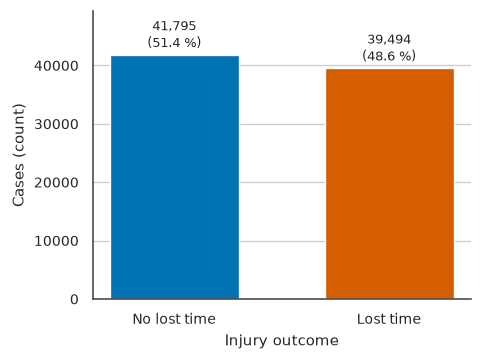

**Class balance by split**

,rows,lost_time = 1,prevalence
training,81289,39494,0.486
test,20320,9873,0.486
all,101609,49367,0.486


In [17]:
from mlda import plots

show(plots.target_distribution(y_train), "Bar chart of the two outcome classes in the training rows, with counts and percentages")
balance = pd.DataFrame(
    {
        "rows": [len(train_idx), len(test_idx), len(y)],
        "lost_time = 1": [int(y_train.sum()), int(y[test_idx].sum()), int(y.sum())],
        "prevalence": [y_train.mean(), y[test_idx].mean(), y.mean()],
    },
    index=["training", "test", "all"],
)
show_table(balance, "Class balance by split")

## B.5 Distributions and class differences

**Histograms** with a kernel density estimate show the shape of each numeric input, split by
outcome. Right-skewed inputs (hours, employees, experience) justify the log-transformed
companions already included in the feature set. **Box plots** by class show whether the median
and spread differ between lost-time and other cases; with fliers hidden the boxes stay readable
for variables with a long tail. Overlapping boxes and curves mean a variable separates the
classes only weakly on its own, which is expected for most accident circumstances.

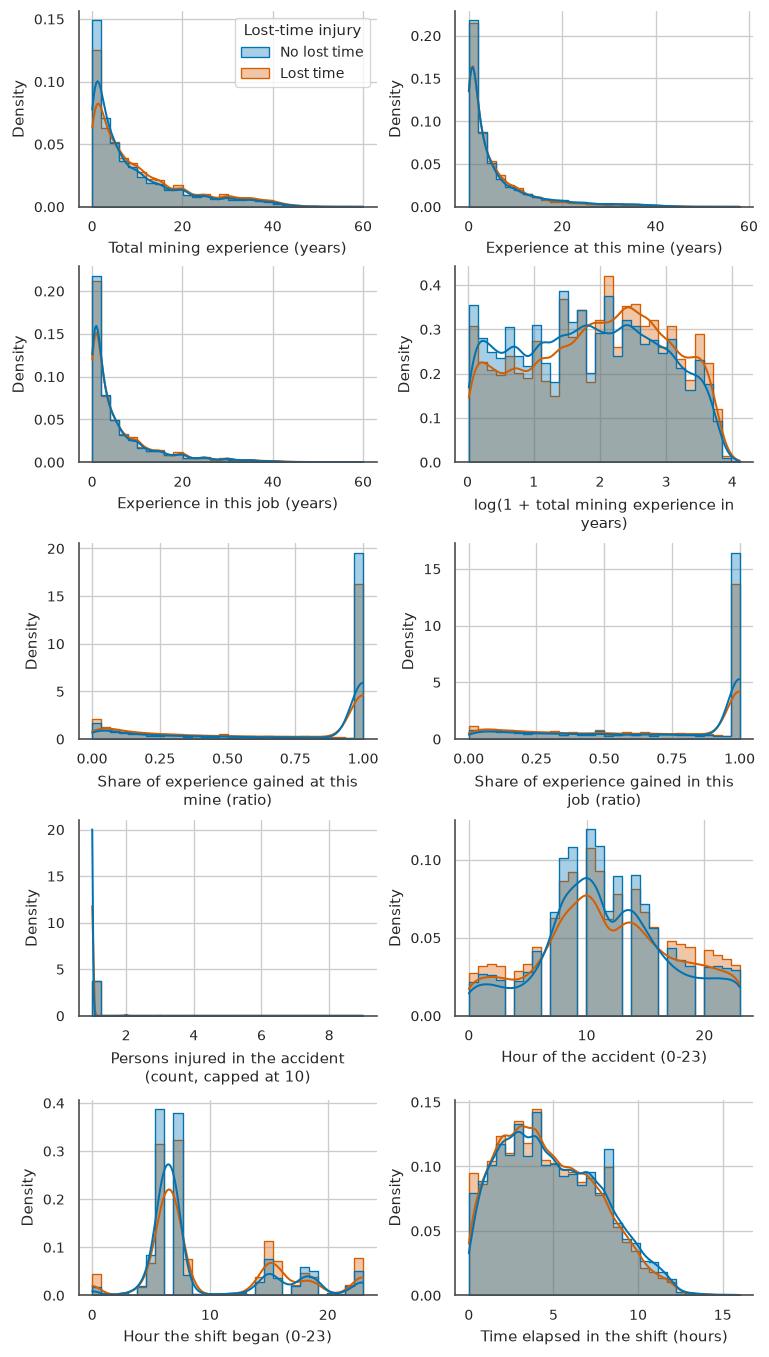

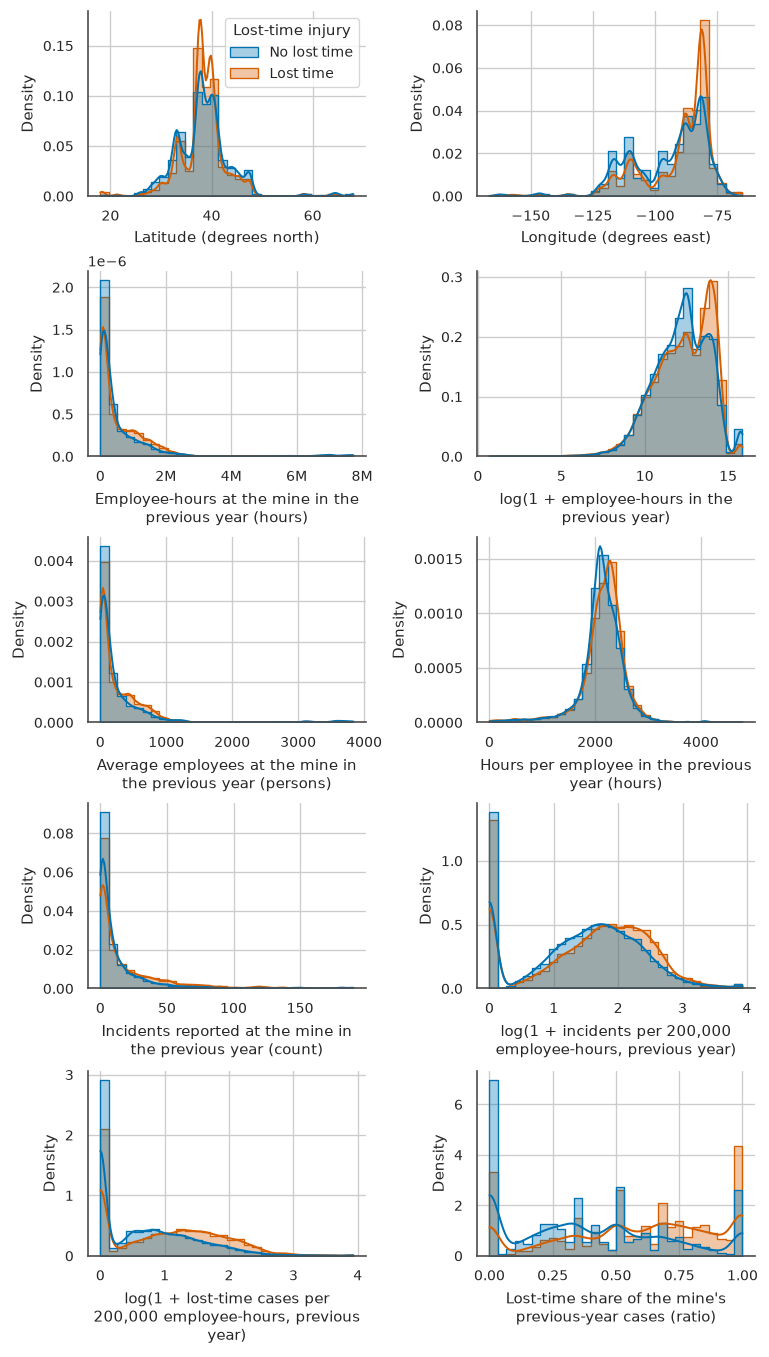

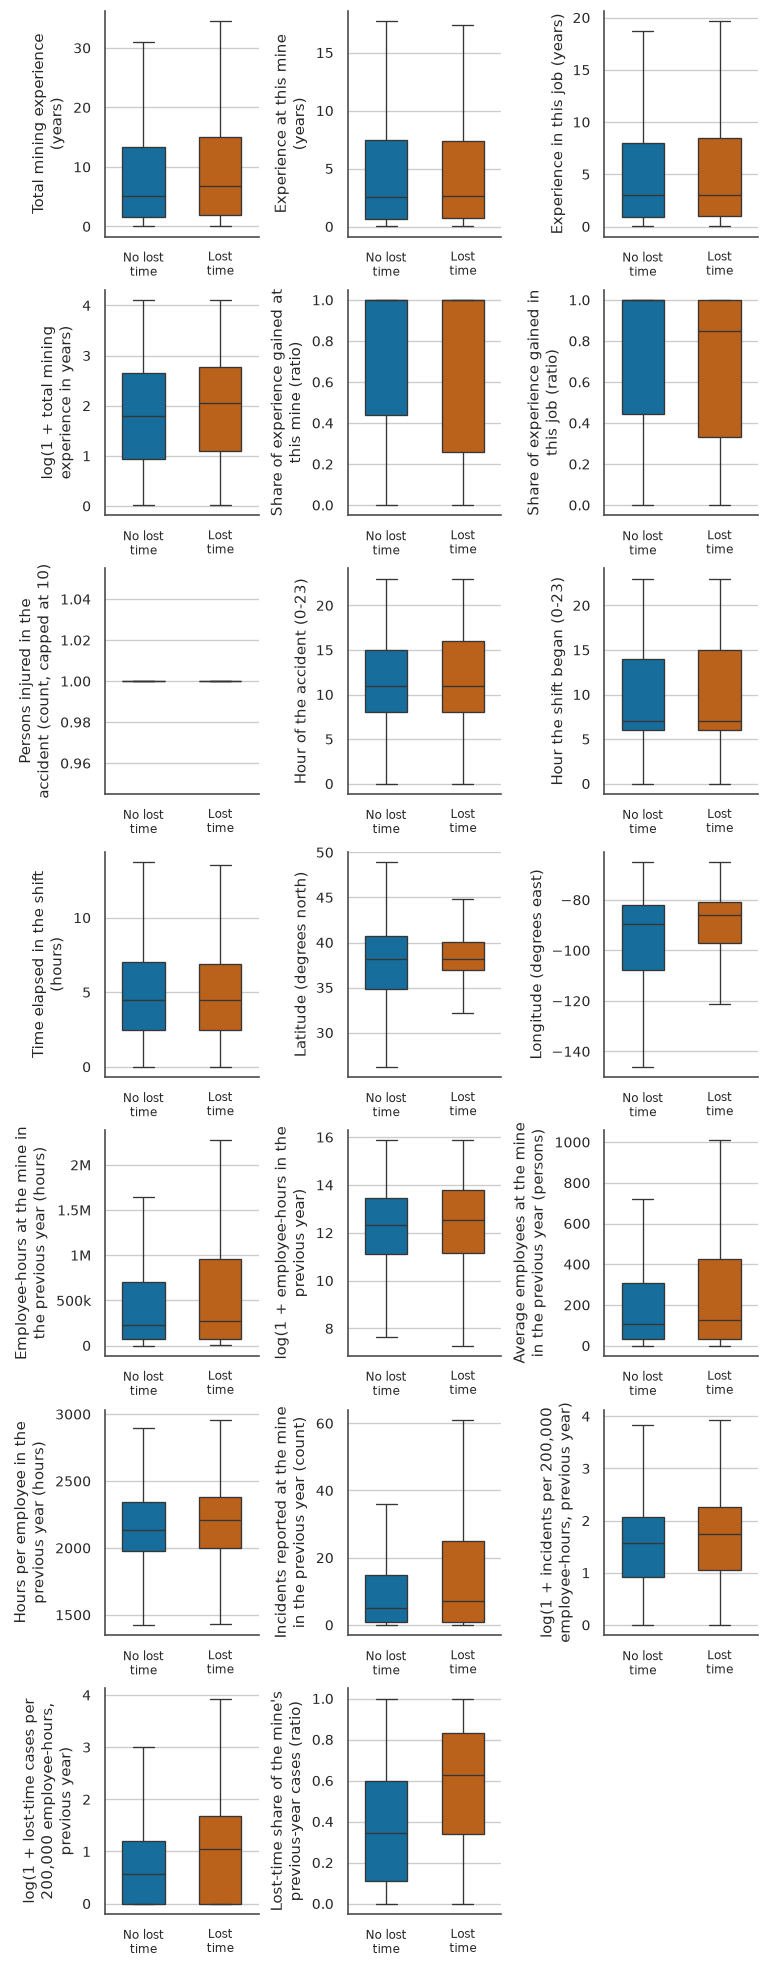

In [18]:
with timer.stage("B.5 histograms and box plots"):
    # two figures of two columns each: the long axis labels of a three-column grid overlap
    for group, columns in (("worker and accident", numeric_cols[:10]), ("mine and exposure", numeric_cols[10:])):
        show(plots.histograms_grid(frame_train, columns, hue=TARGET, ncols=2),
             f"Grid of histograms with density curves of the {group} inputs, split by outcome class")
    show(plots.class_boxplots(frame_train, numeric_cols, TARGET, showfliers=False), "Grid of box plots of the numeric inputs by outcome class")

## B.6 Association with the target and between inputs

**Point-biserial correlation** is Pearson's r between a numeric input and the 0/1 target, so it
is the right coefficient for numeric-versus-binary. **Pearson** measures linear association and
**Spearman** rank (monotone) association; where they disagree by more than 0.1 the relation is
monotone but not linear, or outliers pull Pearson, which is a hint to transform or to prefer a
rank-based or tree model. The pair plot shows the five numeric inputs with the largest
|point-biserial r| against each other, coloured by outcome.

**Point-biserial correlation with lost_time (strongest first)**

,feature,n,r,p_value
0,prev_lost_time_share,65204,0.292,0.000
1,prev_lost_time_rate_200k,80304,0.205,0.000
2,longitude,81114,0.135,0.000
3,prev_incidents,80304,0.099,0.000
4,exper_ratio_mine,79927,-0.096,0.000
5,exper_ratio_job,77095,-0.083,0.000
6,prev_incident_rate_200k,80304,0.073,0.000
7,log1p_tot_exper,80304,0.068,0.000
8,TOT_EXPER,80304,0.060,0.000
9,shift_begin_hour,80881,0.058,0.000


reproducibility: identical to eda_point_biserial.csv


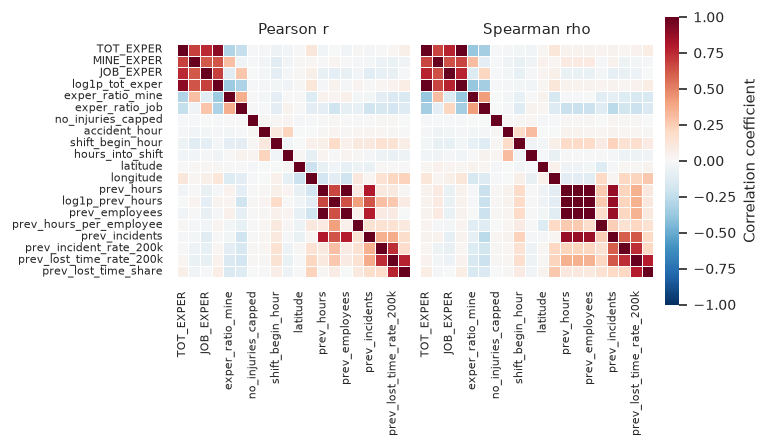

**Pairs where |Pearson - Spearman| exceeds 0.1 (largest gap first)**

,var_a,var_b,pearson,spearman,abs_diff
0,log1p_prev_hours,prev_employees,0.645,0.994,0.349
1,prev_hours,log1p_prev_hours,0.668,1.000,0.332
2,prev_employees,prev_lost_time_rate_200k,0.083,0.351,0.268
3,latitude,longitude,-0.214,0.049,0.263
4,prev_hours,prev_lost_time_rate_200k,0.101,0.358,0.257
5,prev_incidents,prev_incident_rate_200k,0.352,0.608,0.257
6,prev_incidents,prev_lost_time_rate_200k,0.373,0.619,0.245
7,log1p_prev_hours,prev_incidents,0.630,0.873,0.243
8,prev_hours,prev_hours_per_employee,0.091,0.261,0.170
9,log1p_prev_hours,prev_hours_per_employee,0.413,0.261,0.153


21 pairs disagree by more than 0.1


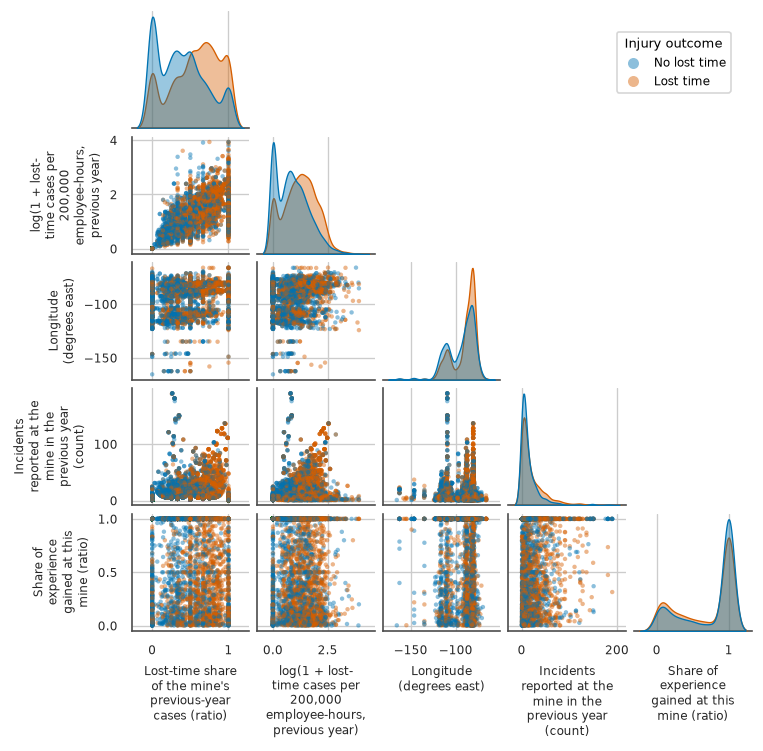

In [19]:
from mlda.eda import correlations, point_biserial

biserial = point_biserial(frame_train, numeric_cols, TARGET)
show_table(biserial, "Point-biserial correlation with lost_time (strongest first)")
print("reproducibility:", matches_stored(biserial, "eda_point_biserial.csv"))

corr = correlations(frame_train, numeric_cols)
show(plots.correlation_heatmaps(corr.pearson, corr.spearman), "Pearson and Spearman correlation heatmaps of the numeric inputs")
show_table(corr.disagreements.head(12), "Pairs where |Pearson - Spearman| exceeds 0.1 (largest gap first)")
print(f"{len(corr.disagreements)} pairs disagree by more than 0.1")

top_numeric = biserial["feature"].head(5).tolist()     # the same five as the report figure (mlda.pipeline.run_eda)
with timer.stage("B.6 pair plot"):
    show(plots.pairplot_top(frame_train, top_numeric, TARGET), "Pair plot of the numeric inputs most correlated with the target, coloured by outcome")

## B.7 Categorical inputs against the target

**Cramer's V** (bias-corrected) is the association between a categorical input and the target,
between 0 (independent) and 1 (the level determines the class). It is the categorical analogue of
the correlation table above and it is comparable across inputs with different numbers of levels
because of the bias correction. The bar charts show the lost-time rate per level of the eight
strongest inputs, with the overall rate marked, and levels with fewer than 100 rows pooled.

**Cramer's V with lost_time (strongest first)**

,feature,n,n_levels,cramers_v,chi2,p_value
0,NATURE_INJURY_CD,81289,27,0.391,"12,459.473",0.000
1,INJ_BODY_PART_CD,81289,46,0.364,"10,844.408",0.000
2,INJURY_SOURCE_CD,81289,124,0.311,"8,005.342",0.000
3,ACCIDENT_TYPE_CD,81289,41,0.282,"6,507.706",0.000
4,FIPS_STATE_CD,81289,54,0.243,"4,836.849",0.000
5,PRIMARY_CANVASS,81289,5,0.239,"4,631.483",0.000
6,COAL_METAL_IND,81289,2,0.237,"4,562.953",0.000
7,ACTIVITY_CD,81289,96,0.225,"4,211.784",0.000
8,CLASSIFICATION_CD,81289,21,0.217,"3,843.545",0.000
9,OCCUPATION,81289,193,0.215,"3,949.008",0.000


reproducibility: identical to eda_cramers_v.csv


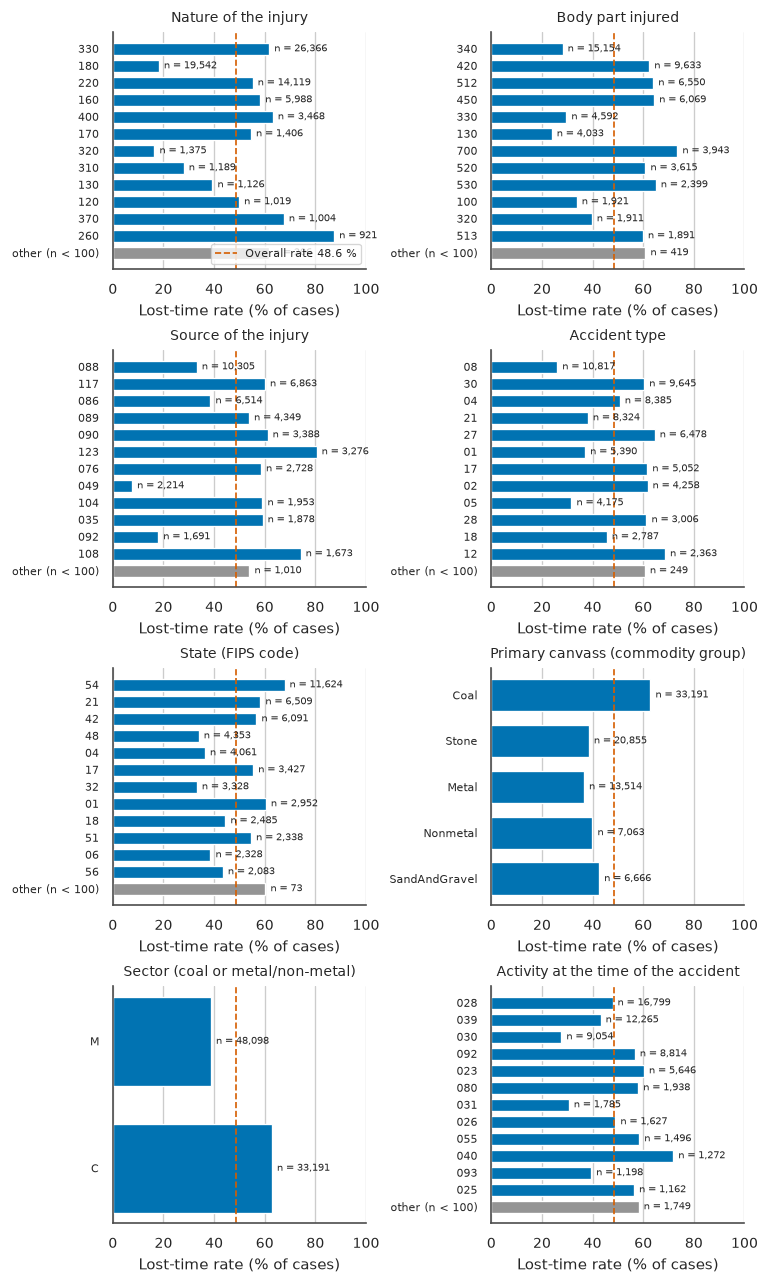

**Lost-time rate by commodity (C = coal, M = metal/non-metal)**

,level,n,share_pct,positive_rate_pct,lift
0,M,48098,59.169,38.748,0.798
1,C,33191,40.831,62.839,1.293


In [20]:
from mlda.eda import class_rate_by_level, cramers_v_table

cramers = cramers_v_table(frame_train, categorical_cols, TARGET)
show_table(cramers, "Cramer's V with lost_time (strongest first)")
print("reproducibility:", matches_stored(cramers, "eda_cramers_v.csv"))

top_categorical = cramers["feature"].head(8).tolist()
show(plots.categorical_vs_target(frame_train, top_categorical, TARGET), "Bar charts of the lost-time rate per level for the categorical inputs most associated with the target")
show_table(class_rate_by_level(frame_train, SECTOR_COL, TARGET), "Lost-time rate by commodity (C = coal, M = metal/non-metal)")

## B.8 Collinearity: variance inflation factors

A variance inflation factor (VIF) above about 5-10 means an input is almost a linear combination
of the others. That does not hurt prediction by trees, but it makes the coefficients of logistic
regression unstable and inflates distances in k-nearest neighbours. The factors are computed on
the training rows, with missing values filled by the median only for this diagnostic.

In [21]:
from mlda.eda import vif_table

vif = vif_table(X_train[numeric_cols])
show_table(vif.head(10), "Largest variance inflation factors")
print("reproducibility:", matches_stored(vif, "eda_vif.csv"))

**Largest variance inflation factors**

,feature,vif
0,prev_hours,176.417
1,prev_employees,164.785
2,prev_lost_time_rate_200k,8.269
3,TOT_EXPER,7.538
4,log1p_tot_exper,5.999
5,prev_incident_rate_200k,4.934
6,JOB_EXPER,4.597
7,MINE_EXPER,4.480
8,prev_incidents,4.188
9,prev_lost_time_share,3.875


reproducibility: identical to eda_vif.csv


## B.9 Missing values

The table counts the missing values in the raw joined columns of the training rows, and the
figure ranks the most incomplete ones. Two patterns matter. Some columns are missing for a
structural reason (an underground location is not applicable at a surface mine), so the gap
carries information and becomes its own level later. Others are reporting gaps (worker
experience, clock times) and need imputation plus an indicator. Codes such as
`9999` are not yet counted as missing here; the rules of section C convert them.

**Raw columns with the most missing values (training rows)**

,column,dtype,n_missing,n_present,missing_pct
0,IMMED_NOTIFY,object,78293,2996,96.314
1,IMMED_NOTIFY_CD,object,78293,2996,96.314
2,INVEST_BEGIN_DT,datetime64[ns],75754,5535,93.191
3,CONTRACTOR_ID,object,71193,10096,87.580
4,EQUIP_MODEL_NO,object,62401,18888,76.764
5,CURRENT_103I_DT,datetime64[ns],54769,26520,67.376
6,UG_MINING_METHOD,object,54144,27145,66.607
7,UG_MINING_METHOD_CD,object,54144,27145,66.607
8,UG_LOCATION,object,53410,27879,65.704
9,UG_LOCATION_CD,object,53410,27879,65.704


45 of 91 raw columns have at least one missing value


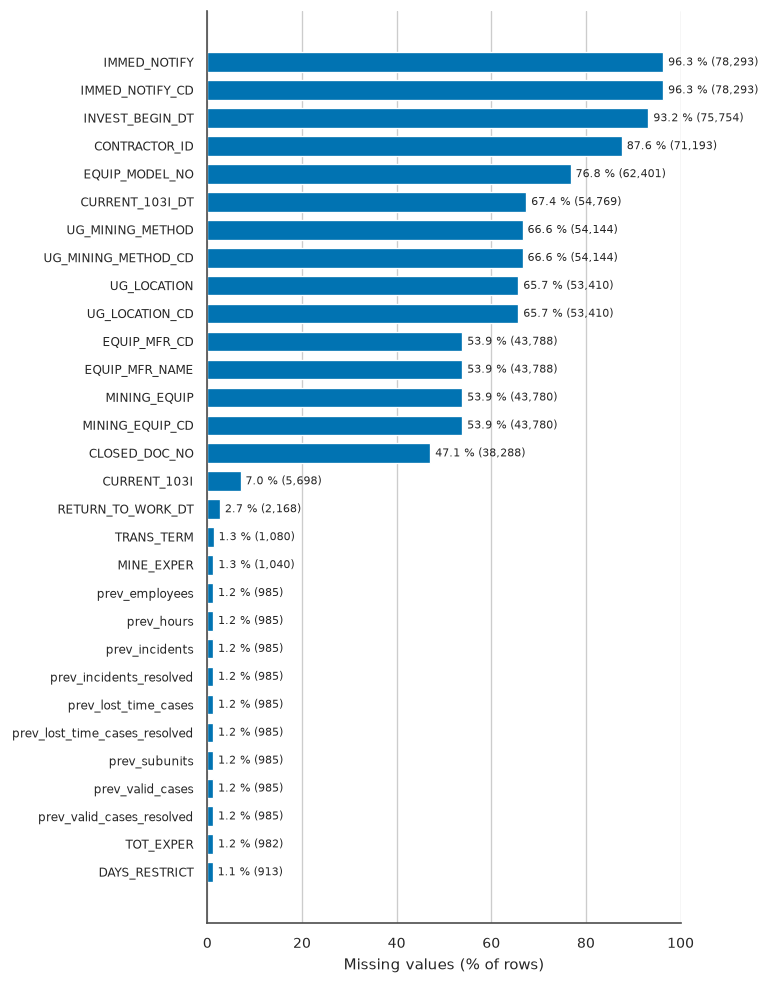

In [22]:
from mlda.eda import missingness_table

missing = missingness_table(base_train)
show_table(missing[missing["n_missing"] > 0].head(20), "Raw columns with the most missing values (training rows)")
print(f"{int((missing['n_missing'] > 0).sum())} of {len(missing)} raw columns have at least one missing value")
show(plots.missingness(base_train), "Bar chart of the percentage of missing values in each raw column")

## B.10 Normality and outliers

A normal **Q-Q plot** compares the quantiles of a variable with those of a normal distribution; a
straight line means normality. The log transform pulls the right tail of experience and hours
towards the line. For outliers two standard rules are compared: **Tukey's IQR fences**
(Q1 - 1.5 IQR, Q3 + 1.5 IQR) and the **Z-score rule** (|z| > 3, with the sample standard
deviation). On a skewed variable the IQR rule flags more points on the long side, because the mean
and standard deviation are themselves inflated by the tail. Outliers are not deleted: they are
real mines and real workers, and the error rules already remove impossible values. The
preprocessor offers optional clipping, which section C evaluates.

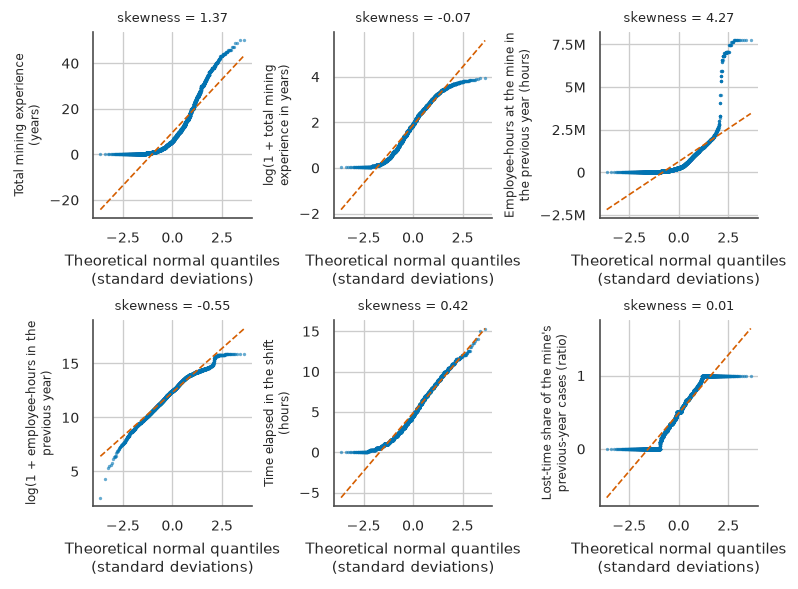

**Rows flagged as outliers by each rule (training rows)**

,IQR rule (1.5),Z-score rule (3),IQR share (%),Z-score share (%)
feature,,,,
prev_incidents,7614,1816,9.367,2.234
MINE_EXPER,7104,2483,8.739,3.055
JOB_EXPER,6906,1908,8.496,2.347
prev_hours_per_employee,5070,1868,6.237,2.298
latitude,4964,1361,6.107,1.674
prev_employees,4094,1454,5.036,1.789
TOT_EXPER,4020,714,4.945,0.878
prev_hours,3872,1454,4.763,1.789
longitude,794,794,0.977,0.977


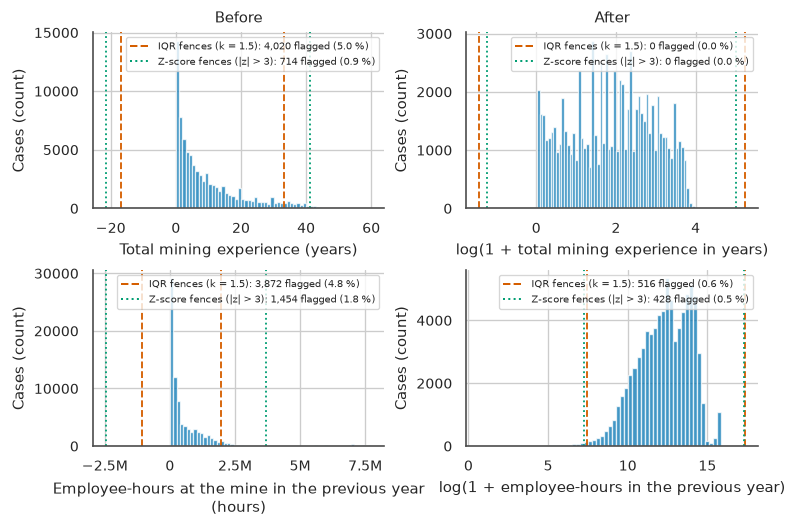

In [23]:
from mlda.cleaning import flag_outliers
from mlda.pipeline import OUTLIER_COLUMNS, QQ_COLUMNS

show(plots.qq_plots(frame_train, list(QQ_COLUMNS)), "Normal Q-Q plots of numeric inputs and their log transforms")

outlier_rows = []
for column in numeric_cols:
    series = frame_train[column]
    iqr_flags, z_flags = flag_outliers(series, "iqr"), flag_outliers(series, "zscore")
    outlier_rows.append(
        {
            "feature": column,
            "IQR rule (1.5)": int(iqr_flags.sum()),
            "Z-score rule (3)": int(z_flags.sum()),
            "IQR share (%)": 100 * iqr_flags.mean(),
            "Z-score share (%)": 100 * z_flags.mean(),
        }
    )
outliers = pd.DataFrame(outlier_rows).set_index("feature")
show_table(outliers.sort_values("IQR rule (1.5)", ascending=False), "Rows flagged as outliers by each rule (training rows)")

after = pd.DataFrame({raw: frame_train[logged].to_numpy() for raw, logged in OUTLIER_COLUMNS.items()})
show(plots.outlier_fences(frame_train, list(OUTLIER_COLUMNS), after=after, after_labels=OUTLIER_COLUMNS),
     "Histograms of experience and previous-year hours with IQR and Z-score outlier fences, before and after the log transform")

## B.11 Principal components

A principal component analysis of the standardised numeric inputs shows whether the classes
separate in the directions of largest variance. The first two components are plotted for a
sample of rows, coloured by outcome. Heavy overlap means no simple linear projection separates
the classes, so a model has to combine many weak signals, which agrees with the modest
correlations above. The explained-variance table is fitted on the training rows only.

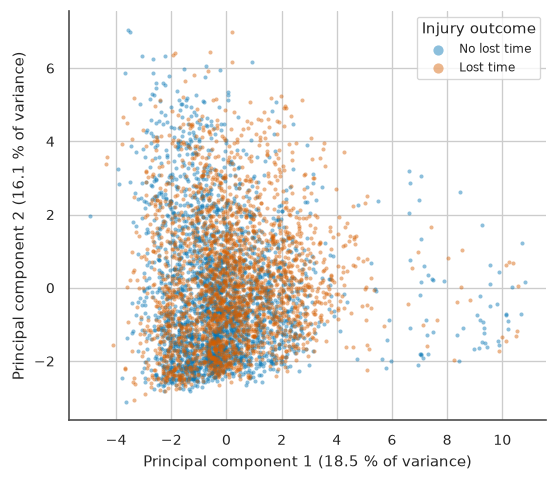

**Variance explained by the first six principal components**

,explained variance ratio,cumulative
PC1,0.185,0.185
PC2,0.161,0.345
PC3,0.114,0.459
PC4,0.069,0.529
PC5,0.061,0.590
PC6,0.059,0.649


In [24]:
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

show(plots.pca_projection(X_train[numeric_cols], y_train), "Scatter plot of the first two principal components of the numeric inputs, coloured by outcome")

scaled = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(X_train[numeric_cols]))
pca = PCA(n_components=6, random_state=RANDOM_STATE).fit(scaled)
explained = pd.DataFrame(
    {
        "explained variance ratio": pca.explained_variance_ratio_,
        "cumulative": np.cumsum(pca.explained_variance_ratio_),
    },
    index=[f"PC{i + 1}" for i in range(6)],
)
show_table(explained, "Variance explained by the first six principal components")

## B.12 Evidence for three claims that later sections use

Three statements further down depend on the training rows and are checked here instead of being
asserted. (1) A blank value can carry signal, so missing-value indicators are kept (section C.3).
(2) Operators code restricted duty (`DEGREE_INJURY_CD` 05, "restricted activity only") at
different rates in coal and in metal and non-metal mines, which is why the label is partly a
property of practice (sections E.8 and F.4). (3) The coal lost-time rate rises over the period
while restricted-duty coding falls, which is the label drift that section E.13 tests. All three
tables use the training rows only; the note under them states the numbers.

In [25]:
evidence = base_train[["CAL_YR", SECTOR_COL]].assign(
    lost_time=y_train,
    restricted_duty=(base_train["DEGREE_INJURY_CD"] == "05").to_numpy(),
    experience_blank=X_train["tot_exper_missing"].to_numpy() == 1,
    unmatched_year=~X_train["prev_year_matched"].to_numpy().astype(bool),
)
indicator_rows = {
    "worker experience blank": evidence["experience_blank"],
    "no previous-year production": evidence["unmatched_year"],
}
indicator_table = pd.DataFrame(
    {
        label: {
            "rows": int(flag.sum()),
            "lost-time rate where the indicator is 1": evidence.loc[flag, "lost_time"].mean(),
            "lost-time rate where it is 0": evidence.loc[~flag, "lost_time"].mean(),
        }
        for label, flag in indicator_rows.items()
    }
).T.astype({"rows": int})
show_table(indicator_table, "Lost-time rate by missing-value indicator (training rows)")

sector_summary = evidence.groupby(SECTOR_COL).agg(
    rows=("lost_time", "size"), lost_time_rate=("lost_time", "mean"), restricted_duty_share=("restricted_duty", "mean")
)
sector_summary.index = sector_summary.index.map({"C": "coal", "M": "metal / non-metal"})
show_table(sector_summary, "Lost-time rate and share of restricted-duty cases (code 05) by commodity (training rows)")

by_year = (
    evidence.groupby(["CAL_YR", SECTOR_COL])
    .agg(lost_time_rate=("lost_time", "mean"), restricted_duty_share=("restricted_duty", "mean"))
    .unstack(SECTOR_COL)
)
by_year.columns = [f"{measure.replace('_', ' ')}, {'coal' if sector == 'C' else 'metal'}" for measure, sector in by_year.columns]
show_table(by_year, "Lost-time rate and restricted-duty share by accident year and commodity (training rows)")

early = evidence[evidence["CAL_YR"] <= YEAR_MIN + 2].groupby(SECTOR_COL)[["lost_time", "restricted_duty"]].mean()
late = evidence[evidence["CAL_YR"] >= YEAR_MAX - 2].groupby(SECTOR_COL)[["lost_time", "restricted_duty"]].mean()
blank = indicator_table.loc["worker experience blank"]
note(
    f"**What the tables show.** Where total experience is blank, {blank.iloc[1]:.1%} of the {int(blank.iloc[0]):,} training cases are lost-time cases "
    f"against {blank.iloc[2]:.1%} elsewhere, so the indicator carries signal. Restricted duty is "
    f"{sector_summary.loc['coal', 'restricted_duty_share']:.1%} of the coal cases and {sector_summary.loc['metal / non-metal', 'restricted_duty_share']:.1%} of "
    f"the metal and non-metal cases, so the sectors draw the line between lost time and restricted duty in different places. Between "
    f"{YEAR_MIN}-{YEAR_MIN + 2} and {YEAR_MAX - 2}-{YEAR_MAX} the coal lost-time rate moves from {early.loc['C', 'lost_time']:.1%} to {late.loc['C', 'lost_time']:.1%} "
    f"while the coal share of restricted-duty cases moves from {early.loc['C', 'restricted_duty']:.1%} to {late.loc['C', 'restricted_duty']:.1%}; "
    f"in metal and non-metal mines the lost-time rate moves from {early.loc['M', 'lost_time']:.1%} to {late.loc['M', 'lost_time']:.1%}."
)

**Lost-time rate by missing-value indicator (training rows)**

,rows,lost-time rate where the indicator is 1,lost-time rate where it is 0
worker experience blank,985,0.593,0.485
no previous-year production,985,0.537,0.485


**Lost-time rate and share of restricted-duty cases (code 05) by commodity (training rows)**

,rows,lost_time_rate,restricted_duty_share
COAL_METAL_IND,,,
coal,33191,0.628,0.069
metal / non-metal,48098,0.387,0.297


**Lost-time rate and restricted-duty share by accident year and commodity (training rows)**

,"lost time rate, coal","lost time rate, metal","restricted duty share, coal","restricted duty share, metal"
CAL_YR,,,,
2010,0.594,0.373,0.076,0.297
2011,0.557,0.363,0.091,0.285
2012,0.605,0.371,0.078,0.295
2013,0.621,0.385,0.068,0.290
2014,0.624,0.394,0.074,0.296
2015,0.639,0.384,0.068,0.298
2016,0.637,0.381,0.078,0.292
2017,0.625,0.392,0.087,0.285
2018,0.642,0.389,0.054,0.298


**What the tables show.** Where total experience is blank, 59.3% of the 985 training cases are lost-time cases against 48.5% elsewhere, so the indicator carries signal. Restricted duty is 6.9% of the coal cases and 29.7% of the metal and non-metal cases, so the sectors draw the line between lost time and restricted duty in different places. Between 2010-2012 and 2023-2025 the coal lost-time rate moves from 58.5% to 68.0% while the coal share of restricted-duty cases moves from 8.2% to 5.1%; in metal and non-metal mines the lost-time rate moves from 36.9% to 40.0%.

## B.13 What the exploration shows, and what it changes

The cell below reads the tables above and states the findings in numbers, so the sentences cannot
drift from the outputs. The markdown after it lists the decisions that follow for the preparation
and the modelling.

In [26]:
skewed = numeric_description[numeric_description["skewness"].abs() > 1].sort_values("skewness", ascending=False)
heavy_tail = outliers.sort_values("IQR rule (1.5)", ascending=False).head(3)
weak = biserial[biserial["r"].abs() < 0.1]
coal_rate = class_rate_by_level(frame_train, SECTOR_COL, TARGET).set_index("level")["positive_rate_pct"]
collinear = vif[vif["vif"] > 10]
note(
    f"**Target.** {len(y_train):,} training rows, {y_train.mean():.1%} lost time: the classes are balanced. "
    f"**Shape.** {len(skewed)} of {len(numeric_cols)} numeric inputs have a skewness above 1 in absolute value "
    f"(largest: `{skewed.index[0]}`, {skewed['skewness'].iloc[0]:.1f}); the log-transformed columns are close to symmetric "
    f"(`log1p_tot_exper` {numeric_description.loc['log1p_tot_exper', 'skewness']:.2f}, "
    f"`log1p_prev_hours` {numeric_description.loc['log1p_prev_hours', 'skewness']:.2f}). "
    f"**Outliers.** The IQR rule flags the most rows for `{heavy_tail.index[0]}` ({heavy_tail['IQR share (%)'].iloc[0]:.1f} % against "
    f"{heavy_tail['Z-score share (%)'].iloc[0]:.1f} % by the Z-score rule), which is the effect of a long right tail on the mean and the standard deviation. "
    f"**Signal.** Only {int((biserial['r'].abs() >= 0.1).sum())} of {len(biserial)} numeric inputs have |r| of at least 0.1 with the target "
    f"(strongest: `{biserial['feature'].iloc[0]}`, r = {biserial['r'].iloc[0]:.2f}); among the categorical inputs the injury "
    f"descriptors lead (`{cramers['feature'].iloc[0]}` V = {cramers['cramers_v'].iloc[0]:.2f}, `{cramers['feature'].iloc[1]}` "
    f"V = {cramers['cramers_v'].iloc[1]:.2f}). The commodity matters: {coal_rate.get('C', float('nan')):.1f} % of coal cases and "
    f"{coal_rate.get('M', float('nan')):.1f} % of metal and non-metal cases are lost-time cases. "
    f"**Collinearity.** {len(collinear)} numeric inputs have a VIF above 10 ({', '.join(f'`{f}`' for f in collinear['feature'])}); "
    f"they carry the same size information. **Missing values.** {int((numeric_description['missing_pct'] > 0).sum())} of the "
    f"{len(numeric_cols)} numeric inputs have gaps, at most {numeric_description['missing_pct'].max():.1f} % of the rows. "
    f"**Projection.** The first two principal components explain {explained['explained variance ratio'].iloc[:2].sum():.0%} of the variance of the numeric inputs "
    f"and the classes overlap heavily in that plane."
)

**Target.** 81,289 training rows, 48.6% lost time: the classes are balanced. **Shape.** 9 of 20 numeric inputs have a skewness above 1 in absolute value (largest: `no_injuries_capped`, 21.9); the log-transformed columns are close to symmetric (`log1p_tot_exper` -0.07, `log1p_prev_hours` -0.55). **Outliers.** The IQR rule flags the most rows for `prev_incidents` (9.4 % against 2.2 % by the Z-score rule), which is the effect of a long right tail on the mean and the standard deviation. **Signal.** Only 3 of 20 numeric inputs have |r| of at least 0.1 with the target (strongest: `prev_lost_time_share`, r = 0.29); among the categorical inputs the injury descriptors lead (`NATURE_INJURY_CD` V = 0.39, `INJ_BODY_PART_CD` V = 0.36). The commodity matters: 62.8 % of coal cases and 38.7 % of metal and non-metal cases are lost-time cases. **Collinearity.** 2 numeric inputs have a VIF above 10 (`prev_hours`, `prev_employees`); they carry the same size information. **Missing values.** 19 of the 20 numeric inputs have gaps, at most 19.8 % of the rows. **Projection.** The first two principal components explain 35% of the variance of the numeric inputs and the classes overlap heavily in that plane.

**Consequences for the next sections.** (1) Several numeric inputs are strongly right-skewed, so the
feature set carries log-transformed copies, and the models that use distances or a linear
boundary receive standardised inputs. (2) The outliers are real mines and real workers, so they
are kept; only impossible values are corrected (section C.2), and clipping is tested rather than
assumed (C.7). (3) The exposure columns are almost collinear, which argues for regularisation in
logistic regression and does not matter for trees. (4) No numeric input separates the classes on its
own, and the injury descriptors are the strongest categorical signals, so categorical encoding
carries most of the load: one-hot encoding with a pooled bucket for rare levels. (5) The commodity
changes the base rate, so every result is also reported by commodity. (6) Missing values are common
only for a few groups, and their pattern is informative, so imputation is paired with indicator
columns.

# C. Data preparation

Preparation turns the joined table into model inputs without letting information from the test
fold leak in. The order is: (1) check for duplicates, (2) correct impossible values with
documented, numbered rules, (3) decide how every group of missing values is handled, (4) engineer
features that use only what is known when the form is filed, (5) test for leakage, (6) build the
preprocessing (imputation, scaling, encoding, optional outlier clipping) as one
`ColumnTransformer` that sits **inside** the model pipeline, so that it is re-fitted on the
training part of every cross-validation fold, and (7) verify the grouped, stratified split.
Every fitted statistic (a median, a scaler's mean, the one-hot levels) is learnt from training
rows only.

## C.1 Duplicates

Each row is one injured person on one form, so a repeated row would mean a repeated person. The
check counts exact duplicates and the duplicates that remain when the identifiers that make every
form unique (the document numbers and the narrative) are ignored. Rows that agree on everything
else are distinct victims of the same event (for example two workers hurt in one accident), so
they are kept; the nested key `accident_group` (mine and accident date) keeps them on the same
side of the split.

In [27]:
identifier_columns = ["DOCUMENT_NO", "CLOSED_DOC_NO", "NARRATIVE"]
descriptive_columns = [c for c in base.columns if c not in identifier_columns]
duplicates = pd.DataFrame(
    [
        {"check": "exact duplicate rows (all columns)", "rows": int(base.duplicated().sum())},
        {"check": "DOCUMENT_NO values that repeat", "rows": int(base["DOCUMENT_NO"].duplicated().sum())},
        {"check": "rows identical apart from the document numbers and narrative", "rows": int(base.duplicated(subset=descriptive_columns).sum())},
    ]
).set_index("check")
show_table(duplicates, "Duplicate checks on the base table")
assert duplicates.loc["exact duplicate rows (all columns)", "rows"] == 0
assert duplicates.loc["DOCUMENT_NO values that repeat", "rows"] == 0

**Duplicate checks on the base table**

,rows
check,
exact duplicate rows (all columns),0
DOCUMENT_NO values that repeat,0
rows identical apart from the document numbers and narrative,5


## C.2 Error-correction rules (the decision log)

The profiling of the raw data found values that cannot be true: job experience longer than total
experience, experience above 60 years, clock-time codes that mean "not reported", a victim count
above ten, coordinates outside the United States, mine attributes that are dated after the
accident, and rates computed from almost no hours. Each problem became a numbered rule, E1 to E30.
The function `apply_error_rules` applies the rules that change values in the joined table (E1-E12
and E21-E25) and returns a log with the condition, the action and the number of rows affected;
the first table below is that log, computed here. The remaining rules (E13-E20 and E26-E30) are
applied when the files are loaded and the features are built: placeholders kept as levels,
repairs of the code lists, type coercion. The second table lists them from the profiling record
`docs/profile/decisions.json`, with the row counts found when the data were profiled.
**Together the two tables are the decision log of the project**: they record what was changed,
why, and how many rows it touched, and none of the rules uses the label.

In [28]:
from mlda.cleaning import apply_error_rules

clean, rule_log = apply_error_rules(base)
with pd.option_context("display.max_colwidth", None):
    show_table(rule_log, f"Error rules E1-E12 and E21-E25: condition, action and rows affected (all {len(base):,} rows)")
print("reproducibility:", matches_stored(rule_log.drop(columns=["rule", "condition", "action"]), "error_rules.csv"))

experience = ["TOT_EXPER", "MINE_EXPER", "JOB_EXPER"]
effect = pd.DataFrame(
    {
        "raw max": base[experience].max(),
        "corrected max": clean[experience].max(),
        "raw missing": base[experience].isna().sum(),
        "corrected missing": clean[experience].isna().sum(),
    }
)
show_table(effect, "Effect of rules E1-E3 on the experience columns")

decisions = json.loads((PROJECT_ROOT / "docs" / "profile" / "decisions.json").read_text(encoding="utf-8"))
documented = pd.DataFrame(decisions["error_rules"])
documented["id"] = documented["name"].str.extract(r"^(E\d+)_", expand=False)
applied_here = set(rule_log["rule"].str.extract(r"^(E\d+)_", expand=False))
elsewhere = documented[~documented["id"].isin(applied_here)].set_index("id")[["name", "condition", "action", "rows_affected"]]
with pd.option_context("display.max_colwidth", None):
    show_table(elsewhere, "Rules applied in load and features (record of the data profiling; row counts as found then)")
assert len(applied_here) + len(elsewhere) == len(documented) == 30, "every documented rule is in exactly one of the two tables"
print(f"{len(applied_here)} rules applied by apply_error_rules, {len(elsewhere)} applied in load and features: {len(documented)} in total")

**Error rules E1-E12 and E21-E25: condition, action and rows affected (all 101,609 rows)**

,rule,condition,action,rows_affected
0,E1_job_exper_gt_total,JOB_EXPER > TOT_EXPER,set JOB_EXPER NaN; exper_inconsistent = 1,3731
1,E2_mine_exper_gt_total,MINE_EXPER > TOT_EXPER,set MINE_EXPER NaN; exper_inconsistent = 1,83
2,E3_exper_gt_60,TOT_EXPER > 60 or MINE_EXPER > 60 or JOB_EXPER > 60,set offending value NaN,3
3,E4_negative_exper,any experience < 0,assert none,0
4,E5_accident_time_code,9990 <= ACCIDENT_TIME <= 9999,NaN,3091
5,E6_accident_time_2400,ACCIDENT_TIME == 2400,set 0000,326
6,E7_accident_time_other_invalid,"ACCIDENT_TIME blank, minutes >= 60 or > 2400 outside codes",assert none,0
7,E8_shift_time_code_or_blank,9990 <= SHIFT_BEGIN_TIME <= 9999 or NaN (blank masked by load.py),NaN,519
8,E9_shift_time_2400,SHIFT_BEGIN_TIME == 2400,set 0000,1833
9,E10_shift_time_short,len(SHIFT_BEGIN_TIME) == 3 (e.g. '700'),parse as integer HHMM (700 -> 07:00); do not string-slice,48


reproducibility: identical to error_rules.csv


**Effect of rules E1-E3 on the experience columns**

,raw max,corrected max,raw missing,corrected missing
TOT_EXPER,66.000,60.000,1222,1225
MINE_EXPER,58.000,58.000,1278,1361
JOB_EXPER,66.000,60.000,873,4606


**Rules applied in load and features (record of the data profiling; row counts as found then)**

,name,condition,action,rows_affected
id,,,,
E13,E13_ug_location_placeholder,UG_LOCATION_CD.isna() (file value '?'),fillna('none'); keep as level (structural: 0 in subunit 01),67077
E14,E14_ug_method_placeholder,UG_MINING_METHOD_CD.isna() (file value '?'),fillna('none'); keep as level (927 genuinely missing in subunit 01),68004
E15,E15_equipment_placeholder,MINING_EQUIP_CD.isna() / EQUIP_MFR_NAME.isna() (file values '?' / 'NO VALUE FOUND'),fillna('none'); keep as level 'none',54691 / 54701
E16,E16_activity_placeholder,ACTIVITY_CD.isna() (file value '?'),fillna('none'); falls into the infrequent bucket,6
E17,E17_immed_notify_placeholder,IMMED_NOTIFY_CD.isna() (file value '? '),immed_reportable = 0,97867
E18,E18_equip_mfr_code_series,EQUIP_MFR_CD 3-digit and 4-digit codes for one name,use EQUIP_MFR_NAME,144 codes -> 138 names
E19,E19_occupation_sector_prefix,OCCUPATION_CD sector prefixes for one title,use OCCUPATION,243 codes -> 195 titles
E20,E20_equip_model_no,EQUIP_MODEL_NO blank or '?' (76.7%),drop column,77962
E26,E26_type_coercion,NUMBER columns read as str,pd.to_numeric; codes stay zero-padded str,all


17 rules applied by apply_error_rules, 13 applied in load and features: 30 in total


## C.3 Missing-value plan

Missing values are treated by group, because the reason for the gap differs. A **structural**
gap (an underground location at a surface mine) is not a missing measurement, so the placeholder
becomes its own level `none`. A **reporting** gap (worker experience, accident hour) is imputed
with the **median**, which is the safer centre for right-skewed variables, and an explicit
**indicator column** records that the value was imputed, because missingness itself can carry
signal (section B.12 compares the lost-time rate where experience is blank with the rest). **Unmatched joins** keep their
rows and carry the indicator `prev_year_matched`. All imputation statistics are learnt inside the
pipeline on training rows. Columns that are mostly empty and carry no information are dropped.
The percentages in the table are measured on the training rows.

In [29]:
def span(values):
    low, high = f"{values.min():.1f}", f"{values.max():.1f}"
    return low if low == high else f"{low} to {high}"


def pct_missing(columns):
    return span(X_train[columns].isna().mean() * 100)


def pct_level(columns, level):
    return span((X_train[columns] == level).mean() * 100)


numeric_plan = [
    ("Worker experience", ["TOT_EXPER", "MINE_EXPER", "JOB_EXPER", "exper_ratio_mine", "exper_ratio_job", "log1p_tot_exper"],
     "median imputation", "tot_exper_missing, exper_inconsistent"),
    ("Time of day", ["accident_hour", "shift_begin_hour", "hours_into_shift"], "median imputation",
     "accident_hour_missing, hours_into_shift_missing"),
    ("Coordinates", ["latitude", "longitude"], "median imputation", "coords_missing"),
    ("Previous-year exposure", ["prev_hours", "log1p_prev_hours", "prev_employees", "prev_hours_per_employee", "prev_incidents",
                               "prev_incident_rate_200k", "prev_lost_time_rate_200k"],
     "median imputation; unmatched rows kept", "prev_year_matched"),
    ("Previous-year lost-time share", ["prev_lost_time_share"], "median imputation; missing when no valid case was filed before the accident",
     "prev_share_missing"),
]
plan_rows = [
    {"group": group, "columns": ", ".join(cols), "missing in training rows (%)": pct_missing(cols), "treatment": treatment, "indicator column": flag}
    for group, cols, treatment, flag in numeric_plan
]
structural = ["UG_LOCATION_CD", "UG_MINING_METHOD_CD", "MINING_EQUIP_CD", "EQUIP_MFR_NAME", "ACTIVITY_CD"]
plan_rows.append(
    {"group": "Structural categorical", "columns": ", ".join(structural),
     "missing in training rows (%)": f"level 'none' {pct_level(structural, 'none')}",
     "treatment": "placeholder kept as the level 'none' (not applicable)", "indicator column": "implicit"}
)
other_cat = [c for c in categorical_cols if c not in structural]
plan_rows.append(
    {"group": "Other categorical", "columns": f"{len(other_cat)} columns", "missing in training rows (%)": f"level 'missing' {pct_level(other_cat, 'missing')}",
     "treatment": "constant level 'missing'; unseen levels fall into an infrequent bucket", "indicator column": "implicit"}
)
plan_rows.append(
    {"group": "Dated mine attribute", "columns": "status_103i_at_accident",
     "missing in training rows (%)": f"level 'Unknown' {(X_train['status_103i_at_accident'] == 'Unknown').mean() * 100:.1f}",
     "treatment": "status dated after the accident, or blank, becomes the level 'Unknown'", "indicator column": "implicit"}
)
plan_rows.append(
    {"group": "Dropped (sparse)", "columns": "EQUIP_MODEL_NO",
     "missing in training rows (%)": f"{base_train['EQUIP_MODEL_NO'].isna().mean() * 100:.1f}",
     "treatment": "dropped: free-text model number, mostly empty", "indicator column": "none"}
)
with pd.option_context("display.max_colwidth", None):
    show_table(pd.DataFrame(plan_rows).set_index("group"), "Missing-value plan by column group")

indicators = X_train[binary_cols].mean().mul(100).rename("share of rows = 1 (%)").to_frame()
show_table(indicators, "Binary columns on the training rows (indicators and flags)")

**Missing-value plan by column group**

,columns,missing in training rows (%),treatment,indicator column
group,,,,
Worker experience,"TOT_EXPER, MINE_EXPER, JOB_EXPER, exper_ratio_mine, exper_ratio_job, log1p_tot_exper",1.2 to 5.2,median imputation,"tot_exper_missing, exper_inconsistent"
Time of day,"accident_hour, shift_begin_hour, hours_into_shift",0.5 to 3.8,median imputation,"accident_hour_missing, hours_into_shift_missing"
Coordinates,"latitude, longitude",0.2,median imputation,coords_missing
Previous-year exposure,"prev_hours, log1p_prev_hours, prev_employees, prev_hours_per_employee, prev_incidents, prev_incident_rate_200k, prev_lost_time_rate_200k",1.2,median imputation; unmatched rows kept,prev_year_matched
Previous-year lost-time share,prev_lost_time_share,19.8,median imputation; missing when no valid case was filed before the accident,prev_share_missing
Structural categorical,"UG_LOCATION_CD, UG_MINING_METHOD_CD, MINING_EQUIP_CD, EQUIP_MFR_NAME, ACTIVITY_CD",level 'none' 0.0 to 66.6,placeholder kept as the level 'none' (not applicable),implicit
Other categorical,18 columns,level 'missing' 0.0 to 1.2,constant level 'missing'; unseen levels fall into an infrequent bucket,implicit
Dated mine attribute,status_103i_at_accident,level 'Unknown' 22.1,"status dated after the accident, or blank, becomes the level 'Unknown'",implicit
Dropped (sparse),EQUIP_MODEL_NO,76.8,"dropped: free-text model number, mostly empty",none


**Binary columns on the training rows (indicators and flags)**

,share of rows = 1 (%)
is_night,28.378
is_weekend,12.132
new_to_mine,28.303
exper_inconsistent,3.675
is_contractor,12.420
immed_reportable,3.600
prev_year_matched,98.788
tot_exper_missing,1.212
accident_hour_missing,3.035
hours_into_shift_missing,3.796


## C.4 Feature engineering

`engineer_features` builds the 55 inputs row by row, with no fitted state: 23 categorical, 20
numeric and 12 binary columns, listed in `FEATURE_SPEC`. The design rule is **only what is known
when the form is filed**. The accident circumstances, the worker's experience and the mine's
stable attributes qualify; the mine's history qualifies only as the previous year, and only cases
filed before the accident. The error rules are part of these formulas, which is why computing the
features from the raw base table and from the corrected table gives the identical frame (the
cell asserts this).

In [30]:
from mlda.features import FeatureFrame, feature_frame

parts: FeatureFrame = feature_frame(clean)     # X, y, groups and the reporting columns, from the corrected table
assert parts.X.equals(X), "features differ between the raw and the corrected base table"
assert np.array_equal(parts.y.to_numpy(dtype=int), y) and np.array_equal(parts.groups.to_numpy(dtype=str), groups)
meta = parts.meta

spec_table = pd.DataFrame(
    {
        "kind": [kind for kind in ("categorical", "numeric", "binary") for _ in FEATURE_SPEC[kind]],
        "feature": [name for kind in ("categorical", "numeric", "binary") for name in FEATURE_SPEC[kind]],
    }
)
spec_table["dtype"] = [str(X[name].dtype) for name in spec_table["feature"]]
spec_table["levels (categorical)"] = pd.array(
    [X[name].nunique() if kind == "categorical" else None for kind, name in zip(spec_table["kind"], spec_table["feature"], strict=True)],
    dtype="Int64",
)
counts = spec_table["kind"].value_counts().rename("features").to_frame().loc[["categorical", "numeric", "binary"]]
show_table(counts, "FEATURE_SPEC: features per kind")
print(f"total {len(spec_table)} features; X has shape {X.shape}")
with pd.option_context("display.max_rows", 80):
    show_table(spec_table.set_index("feature"), "FEATURE_SPEC listing")

**FEATURE_SPEC: features per kind**

,features
kind,
categorical,23
numeric,20
binary,12


total 55 features; X has shape (101609, 55)


**FEATURE_SPEC listing**

,kind,dtype,levels (categorical)
feature,,,
SUBUNIT_CD,categorical,object,10
FIPS_STATE_CD,categorical,object,54
UG_LOCATION_CD,categorical,object,8
UG_MINING_METHOD_CD,categorical,object,8
MINING_EQUIP_CD,categorical,object,66
EQUIP_MFR_NAME,categorical,object,139
CLASSIFICATION_CD,categorical,object,21
ACCIDENT_TYPE_CD,categorical,object,41
OCCUPATION,categorical,object,195


In [31]:
formulas = pd.DataFrame(
    [
        ("log1p_tot_exper", "log(1 + TOT_EXPER)", "experience is right-skewed; the log spreads the short careers"),
        ("exper_ratio_mine, exper_ratio_job", "MINE_EXPER / TOT_EXPER and JOB_EXPER / TOT_EXPER, clipped to [0, 1]", "newness to the mine or the job, whatever the career length"),
        ("hours_into_shift", "(accident time - shift start) mod 24 h, in hours; missing if > 16", "fatigue and shift position; the modulo handles shifts that start before midnight"),
        ("accident_hour, shift_begin_hour, is_night, is_weekend", "hour of the clock time; night = 18:00-05:59; Saturday or Sunday", "time-of-day and calendar effects"),
        ("new_to_mine", "1 if MINE_EXPER < 1 year", "workers new to a site"),
        ("prev_hours, log1p_prev_hours, prev_employees, prev_hours_per_employee", "previous-year employee-hours and average employees of the mine", "exposure and mine size"),
        ("prev_incident_rate_200k, prev_lost_time_rate_200k", "log(1 + min(cases / hours x 200,000, 50))", "MSHA's incidence rate per 200,000 hours; capped for tiny mines (rule E25)"),
        ("prev_lost_time_share", "previous-year lost-time cases / valid cases, filed before the accident", "how often this mine's cases end in lost time"),
        ("mine_size_band, type_at_time, status_103i_at_accident", "employees band; Underground / Surface / Facility; 103(i) status in force", "mine context at the time, not today"),
        ("is_contractor, immed_reportable", "contractor present; immediate-notification code present and valid", "who was hurt and how the event was reported"),
    ],
    columns=["feature(s)", "formula", "reason"],
).set_index("feature(s)")
with pd.option_context("display.max_colwidth", None):
    show_table(formulas, "Engineered features: formula and reason")

show_table(
    pd.concat(
        [base[["TOT_EXPER", "ACCIDENT_TIME", "SHIFT_BEGIN_TIME", "prev_hours"]].head(5).add_prefix("raw "),
         X[["log1p_tot_exper", "accident_hour", "hours_into_shift", "log1p_prev_hours", "is_night"]].head(5)],
        axis=1,
    ),
    "Five rows: raw columns next to the engineered features derived from them",
)

**Engineered features: formula and reason**

,formula,reason
feature(s),,
log1p_tot_exper,log(1 + TOT_EXPER),experience is right-skewed; the log spreads the short careers
"exper_ratio_mine, exper_ratio_job","MINE_EXPER / TOT_EXPER and JOB_EXPER / TOT_EXPER, clipped to [0, 1]","newness to the mine or the job, whatever the career length"
hours_into_shift,"(accident time - shift start) mod 24 h, in hours; missing if > 16",fatigue and shift position; the modulo handles shifts that start before midnight
"accident_hour, shift_begin_hour, is_night, is_weekend",hour of the clock time; night = 18:00-05:59; Saturday or Sunday,time-of-day and calendar effects
new_to_mine,1 if MINE_EXPER < 1 year,workers new to a site
"prev_hours, log1p_prev_hours, prev_employees, prev_hours_per_employee",previous-year employee-hours and average employees of the mine,exposure and mine size
"prev_incident_rate_200k, prev_lost_time_rate_200k","log(1 + min(cases / hours x 200,000, 50))","MSHA's incidence rate per 200,000 hours; capped for tiny mines (rule E25)"
prev_lost_time_share,"previous-year lost-time cases / valid cases, filed before the accident",how often this mine's cases end in lost time
"mine_size_band, type_at_time, status_103i_at_accident",employees band; Underground / Surface / Facility; 103(i) status in force,"mine context at the time, not today"


**Five rows: raw columns next to the engineered features derived from them**

,raw TOT_EXPER,raw ACCIDENT_TIME,raw SHIFT_BEGIN_TIME,raw prev_hours,log1p_tot_exper,accident_hour,hours_into_shift,log1p_prev_hours,is_night
0,5.380,0740,0445,"256,005.000",1.853,7.000,2.917,12.453,0
1,4.350,1400,0630,"264,008.000",1.677,14.000,7.500,12.484,0
2,1.620,1400,0700,"248,818.000",0.963,14.000,7.000,12.424,0
3,4.460,0045,1900,"248,818.000",1.697,0.000,5.750,12.424,1
4,8.080,0855,0700,"256,005.000",2.206,8.000,1.917,12.453,0


## C.5 Leakage check

**Target leakage** means that a model input contains the answer, or something recorded after the
outcome is known. In this data the outcome columns (days lost, days restricted, the schedule
charge, the return-to-work date, the closing document, the investigation date, the narrative
written after the case) would make the problem trivial and useless, because none of them exists
when the form is filed. The mine's *current* state (status today, employee count today) is a
second, quieter leak: it describes the mine after the accident. The cell asserts that none of
these columns is in `X`, and that no single input is almost a copy of the target.

In [32]:
from mlda.config import LEAKAGE_COLUMNS, MINES_CURRENT_STATE_COLUMNS

forbidden = set(LEAKAGE_COLUMNS) | set(MINES_CURRENT_STATE_COLUMNS) | {TARGET, TARGET_SOURCE_COL}
overlap = sorted(forbidden & set(X.columns))
assert not overlap, f"leakage columns in the feature frame: {overlap}"
print(f"none of the {len(forbidden)} leakage or current-state columns is among the {X.shape[1]} features")

strongest = float(biserial["r"].abs().max())
assert strongest < 0.95, "one numeric input is almost a copy of the target"
print(f"strongest numeric association with the target: |r| = {strongest:.3f} ({biserial['feature'].iloc[0]})")
print(f"strongest categorical association: Cramer's V = {cramers['cramers_v'].max():.3f} ({cramers['feature'].iloc[0]})")

reasons = {
    "DEGREE_INJURY_CD": "defines the label",
    "DEGREE_INJURY": "text of the label",
    "DAYS_LOST": "days away from work, known only after recovery",
    "DAYS_RESTRICT": "days of restricted duty, known only after recovery",
    "SCHEDULE_CHARGE": "days charged for permanent loss, assigned after the case",
    "TRANS_TERM": "transfer or termination, recorded after the injury",
    "RETURN_TO_WORK_DT": "date the worker came back, after the injury",
    "CLOSED_DOC_NO": "closing document, filed when the case is resolved",
    "INVEST_BEGIN_DT": "investigation date, after the accident",
    "NARRATIVE": "free text written after the case",
}
leak_table = pd.DataFrame({"excluded because": [reasons[c] for c in LEAKAGE_COLUMNS]}, index=pd.Index(LEAKAGE_COLUMNS, name="outcome column"))
show_table(leak_table, "Outcome columns kept out of the features")
print("current-state mine columns kept out:", ", ".join(MINES_CURRENT_STATE_COLUMNS))

none of the 28 leakage or current-state columns is among the 55 features
strongest numeric association with the target: |r| = 0.292 (prev_lost_time_share)
strongest categorical association: Cramer's V = 0.391 (NATURE_INJURY_CD)


**Outcome columns kept out of the features**

,excluded because
outcome column,
DEGREE_INJURY_CD,defines the label
DEGREE_INJURY,text of the label
DAYS_LOST,"days away from work, known only after recovery"
DAYS_RESTRICT,"days of restricted duty, known only after recovery"
SCHEDULE_CHARGE,"days charged for permanent loss, assigned after the case"
TRANS_TERM,"transfer or termination, recorded after the injury"
RETURN_TO_WORK_DT,"date the worker came back, after the injury"
CLOSED_DOC_NO,"closing document, filed when the case is resolved"
INVEST_BEGIN_DT,"investigation date, after the accident"


current-state mine columns kept out: CURRENT_MINE_STATUS, CURRENT_STATUS_DT, CURRENT_MINE_TYPE, COMPANY_TYPE, CURRENT_CONTROLLER_BEGIN_DT, NO_EMPLOYEES, DAYS_PER_WEEK, HOURS_PER_SHIFT, PROD_SHIFTS_PER_DAY, MAINT_SHIFTS_PER_DAY, AVG_MINE_HEIGHT, METHANE_LIBERATION, MINE_GAS_CATEGORY_CD, NO_PRODUCING_PITS, NO_NONPRODUCING_PITS, NO_TAILING_PONDS, MILES_FROM_OFFICE


## C.6 The preprocessing pipeline

`build_preprocessor` returns an unfitted `ColumnTransformer` with three branches: **numeric**
columns are cast to float32, optionally clipped, imputed and scaled; **categorical** columns are
imputed with the constant level "missing" and one-hot encoded, with levels rarer than 0.1 % of
the training rows pooled into an *infrequent* bucket (which is also where a level that never
appeared in training goes at prediction time); **binary** columns pass through. The default
options are the median imputer, the standard scaler, one-hot encoding and no clipping. Tree
models override the scaler with "none", because their splits do not depend on scale. The first
table gives the rationale of each option; the cells after it fit the transformer on the
training rows and check what comes out.

In [33]:
from mlda.preprocessing import DEFAULTS, OPTIONS, build_preprocessor, get_feature_names

option_rows = [
    {"option": name, "value": str(value), "default": DEFAULTS[name] == value, "rationale": text}
    for name, choices in OPTIONS.items()
    for value, text in choices.items()
]
with pd.option_context("display.max_colwidth", None):
    show_table(pd.DataFrame(option_rows).set_index(["option", "value"]), "Preprocessing options and their rationale (default marked)")

preprocessor = build_preprocessor()              # median imputer, standard scaler, one-hot encoder, no clipping
display(preprocessor)                            # the branch structure as scikit-learn draws it

**Preprocessing options and their rationale (default marked)**

default  \
option          value                  
numeric_imputer median          True   
                mean           False   
                knn            False   
scaler          standard        True   
                minmax         False   
                robust         False   
                none           False   
encoder         onehot          True   
                ordinal        False   
outlier_rule    None            True   
                iqr_clip       False   
                zscore_clip    False   

                                                                                                                                                                                                                                           rationale  
option          value                                                                                                                                                                                                                                 
numeric_imputer median                                       SimpleImputer(median) on the training rows: the experience columns are right-skewed (skew 1.4 to 2.3) and the exposure columns more so (3.2 to 4.7), so the median is the safer centre.  
                mean                                                                                                                      SimpleImputer(mean): the textbook default, pulled upwards by the long right tails of hours and experience.  
                knn                              KNNImputer(5 neighbours) on the standardised numeric block (scaled for the neighbour search, scaled back afterwards): borrows values from similar training rows at a much higher cost on 100k rows.  
scaler          standard                                                                                                                       StandardScaler to zero mean and unit variance: required by logistic regression, SVM, KNN and the MLP.  
                minmax                                                                                                                     MinMaxScaler to [0, 1]: keeps the shape of each distribution and is sensitive to extreme training values.  
                robust                                                                                                                       RobustScaler centres on the median and divides by the IQR, so a few extreme mines do not set the scale.  
                none                                                                                                                                   No scaling: tree ensembles and Gaussian naive Bayes do not depend on the scale of the inputs.  
encoder         onehot                                                                                                OneHotEncoder with an infrequent bucket for levels rarer than min_frequency; unseen levels at inference fall into that bucket.  
                ordinal                                                                                   OrdinalEncoder with -1 for unseen levels: compact for trees, but it imposes an arbitrary order that linear models would read as magnitude.  
outlier_rule    None                                                                                                                                                        No clipping: the error rules E1 to E30 already remove impossible values.  
                iqr_clip     Clip to Tukey fences Q1 - 1.5 IQR and Q3 + 1.5 IQR learnt on the training rows; a column whose IQR is zero (such as the victim count, 99 % ones) keeps open fences, because clipping it would flatten it to a constant.  
                zscore_clip                                                                                                                                               Clip to mean +/- 3 sample standard deviations learnt on the training rows.

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.0
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer

In [34]:
with timer.stage("C.6 fit the preprocessor"):
    preprocessor.fit(X_train)                    # every statistic is learnt from the TRAINING rows
X_test, y_test, g_test, sector_test = X.iloc[test_idx], y[test_idx], groups[test_idx], sector[test_idx]
Xt_train = preprocessor.transform(X_train)
Xt_test = preprocessor.transform(X_test)
names = get_feature_names(preprocessor)

n_num, n_bin = len(numeric_cols), len(binary_cols)
n_cat = Xt_train.shape[1] - n_num - n_bin
widths = pd.DataFrame(
    {
        "input columns": [n_num, len(categorical_cols), n_bin, X.shape[1]],
        "output columns": [n_num, n_cat, n_bin, Xt_train.shape[1]],
    },
    index=["numeric (impute + scale)", "categorical (one-hot)", "binary (pass-through)", "total"],
)
show_table(widths, "Width of the design matrix")
print(f"training matrix {Xt_train.shape}, test matrix {Xt_test.shape}, dtype {Xt_train.dtype}")
print("missing values after transformation (train / test):", int(np.isnan(Xt_train).sum()), "/", int(np.isnan(Xt_test).sum()))
print("one-hot columns that are 'infrequent' buckets:", sum(n.endswith("_infrequent_sklearn") for n in names))

# Proof that the fitted statistics come from the training rows: medians of the imputer, mean and scale of the scaler.
numeric_branch = preprocessor.named_transformers_["num"]
learnt = pd.DataFrame(
    {
        "imputer median": numeric_branch["imputer"].statistics_,
        "training median": X_train[numeric_cols].median().to_numpy(),
        "scaler mean": numeric_branch["scaler"].mean_,
        "scaler std": np.sqrt(numeric_branch["scaler"].var_),
    },
    index=numeric_cols,
)
assert np.allclose(learnt["imputer median"], learnt["training median"], rtol=1e-4)
show_table(learnt.head(8), "Statistics learnt on the training rows (first 8 numeric inputs)")
check = pd.DataFrame(
    {"mean": Xt_train[:, :n_num].mean(axis=0), "std": Xt_train[:, :n_num].std(axis=0)}, index=numeric_cols
).describe().loc[["min", "max"]]
show_table(check, "Scaled numeric training columns: range of the column means and standard deviations (about 0 and 1)")

**Width of the design matrix**

,input columns,output columns
numeric (impute + scale),20,20
categorical (one-hot),23,520
binary (pass-through),12,12
total,55,552


training matrix (81289, 552), test matrix (20320, 552), dtype float32
missing values after transformation (train / test): 0 / 0
one-hot columns that are 'infrequent' buckets: 13


**Statistics learnt on the training rows (first 8 numeric inputs)**

,imputer median,training median,scaler mean,scaler std
TOT_EXPER,6.000,6.000,9.763,10.367
MINE_EXPER,2.600,2.600,5.802,7.994
JOB_EXPER,3.000,3.000,6.053,7.904
log1p_tot_exper,1.946,1.946,1.890,1.038
exper_ratio_mine,1.000,1.000,0.725,0.381
exper_ratio_job,0.975,0.975,0.721,0.351
no_injuries_capped,1.000,1.000,1.016,0.227
accident_hour,11.000,11.000,11.633,5.460


**Scaled numeric training columns: range of the column means and standard deviations (about 0 and 1)**

,mean,std
min,-0.000,1.000
max,0.000,1.000


In [35]:
from mlda.models import MODEL_ZOO

overrides = pd.DataFrame(
    {"preprocessing": {name: str(spec.preprocess_overrides or "default") for name, spec in MODEL_ZOO.items()}}
)
show_table(overrides, "Model-specific preprocessing (trees and boosting skip the scaler)")

**Model-specific preprocessing (trees and boosting skip the scaler)**

,preprocessing
logreg,{'scaler': 'standard'}
knn,{'scaler': 'standard'}
gaussian_nb,{'scaler': 'standard'}
decision_tree,{'scaler': 'none'}
random_forest,{'scaler': 'none'}
hist_gb,{'scaler': 'none'}
svc_rbf,{'scaler': 'standard'}
mlp,{'scaler': 'standard'}


## C.7 Do the preprocessing choices matter?

The defaults come from the data profile, but a choice that is only argued should also be tested.
The cell compares seven preprocessing variants with logistic regression, which is the model most
sensitive to scaling and outliers. The comparison uses a 12,000-row sample of **training mine-years**
and three grouped, stratified folds, scored by average precision, so no test row is involved.
The k-nearest-neighbour imputer was left out because it costs far more than the others on
100,000 rows. Differences smaller than the fold-to-fold standard deviation should not be read as
a ranking.

In [36]:
from sklearn.model_selection import cross_val_score

from mlda.models import build_pipeline
from mlda.split import cv_splitter
from mlda.tuning import stratified_group_subsample

sample = stratified_group_subsample(y_train, g_train, 12_000)
variants = {
    "median + standard scaler + one-hot (chosen)": {},
    "mean imputer": {"numeric_imputer": "mean"},
    "robust scaler": {"scaler": "robust"},
    "min-max scaler": {"scaler": "minmax"},
    "IQR clipping": {"outlier_rule": "iqr_clip"},
    "Z-score clipping": {"outlier_rule": "zscore_clip"},
    "ordinal instead of one-hot": {"encoder": "ordinal"},
}
ablation_rows = []
with timer.stage("C.7 preprocessing ablation"):
    for label, options in variants.items():
        pipeline = build_pipeline(MODEL_ZOO["logreg"], build_preprocessor(**options))
        scores = cross_val_score(
            pipeline, X_train.iloc[sample], y_train[sample], groups=g_train[sample],
            cv=cv_splitter(3), scoring="average_precision", n_jobs=3,
        )
        ablation_rows.append({"variant": label, "mean AP": scores.mean(), "std over folds": scores.std(ddof=1)})
ablation = pd.DataFrame(ablation_rows).set_index("variant")
show_table(ablation, f"Logistic regression, {len(sample):,} training rows, 3 grouped folds: average precision")

**Logistic regression, 11,953 training rows, 3 grouped folds: average precision**

,mean AP,std over folds
variant,,
median + standard scaler + one-hot (chosen),0.808,0.006
mean imputer,0.808,0.006
robust scaler,0.808,0.006
min-max scaler,0.809,0.006
IQR clipping,0.808,0.004
Z-score clipping,0.809,0.006
ordinal instead of one-hot,0.757,0.009


**Reading the table.** The imputer, the scaler and the clipping rule change the score by less than
one fold standard deviation for logistic regression, so none of them earns extra complexity and the
defaults stay: the error rules have already removed the impossible values, which is why clipping
adds nothing. The encoder is the exception. Replacing one-hot columns by integer codes costs
several points of average precision, because the codes impose an order that a linear model reads
as magnitude. One-hot encoding is therefore used for every model in the zoo. The ordinal option was
compared with logistic regression only; the tree models also receive the one-hot matrix, and
whether integer codes would suit them better was not tested.

## C.8 The grouped, stratified split

A random split would put the rows of one mine-year on both sides, and most rows have a sibling
from the same mine-year (the cell prints the share) whose outcome the model could simply remember. The split therefore keeps
every **mine-year** (`MINE_ID` + year) together and stratifies on the label:
`StratifiedGroupKFold(5, shuffle=True, random_state=42)` takes one fold of mine-years as the 20 %
test set. The indices are persisted in `data/processed/split_indices.json`, so the notebook, the
command-line run and the app all use the same rows. The cell checks the invariants (disjoint
mine-years, no multi-victim accident divided, prevalence within 1 percentage point) and rebuilds
the split from scratch to confirm that it is reproducible.

In [37]:
from mlda.split import check_split, make_split

accident_groups = meta["accident_group"].to_numpy(dtype=str)
print(f"rows that share their mine-year with at least one other row: {pd.Series(groups).duplicated(keep=False).mean():.1%}")
check_split(split, y, groups, accident_groups)      # raises AssertionError if any invariant fails

straddling_years = len(np.intersect1d(groups[train_idx], groups[test_idx]))
straddling_accidents = len(np.intersect1d(accident_groups[train_idx], accident_groups[test_idx]))
gap_pp = {name: 100 * abs(y[idx].mean() - y.mean()) for name, idx in (("train", train_idx), ("test", test_idx))}
checks = pd.DataFrame(
    {
        "check": ["row positions shared by train and test", "mine-years in both sets", "accident groups (mine + date) in both sets",
                  "train prevalence gap (pp)", "test prevalence gap (pp)", "tolerance (pp)"],
        "value": [len(np.intersect1d(train_idx, test_idx)), straddling_years, straddling_accidents,
                  round(gap_pp["train"], 3), round(gap_pp["test"], 3), 1.0],
    }
).set_index("check")
show_table(checks, "check_split: invariants of the persisted split (all passed)")

summary = pd.DataFrame(
    {
        "rows": [len(train_idx), len(test_idx)],
        "share of rows (%)": [100 * len(train_idx) / len(y), 100 * len(test_idx) / len(y)],
        "mine-years": [len(np.unique(groups[train_idx])), len(np.unique(groups[test_idx]))],
        "mines": [meta["MINE_ID"].iloc[train_idx].nunique(), meta["MINE_ID"].iloc[test_idx].nunique()],
        "lost-time rate": [y_train.mean(), y_test.mean()],
        "coal share": [(sector[train_idx] == "C").mean(), (sector_test == "C").mean()],
    },
    index=["training", "test"],
)
show_table(summary, "Training and test fold")

rebuilt = make_split(X, y, groups, accident_groups=accident_groups)
print("split rebuilt from the seed equals the persisted split:",
      bool(np.array_equal(rebuilt.train_idx, split.train_idx) and np.array_equal(rebuilt.test_idx, split.test_idx)))
print(f"X_train {X_train.shape}, y_train {y_train.shape}, X_test {X_test.shape}, y_test {y_test.shape}")

rows that share their mine-year with at least one other row: 82.5%


**check_split: invariants of the persisted split (all passed)**

,value
check,
row positions shared by train and test,0.000
mine-years in both sets,0.000
accident groups (mine + date) in both sets,0.000
train prevalence gap (pp),0.001
test prevalence gap (pp),0.002
tolerance (pp),1.000


**Training and test fold**

,rows,share of rows (%),mine-years,mines,lost-time rate,coal share
training,81289,80.002,26008,7645,0.486,0.408
test,20320,19.998,6724,3955,0.486,0.407


split rebuilt from the seed equals the persisted split: True
X_train (81289, 55), y_train (81289,), X_test (20320, 55), y_test (20320,)


**Why mine-years and not rows or mines.** Section 3.9 of the report rests on three measurements,
computed here on all in-scope rows. (1) The mean label of the rows of the same mine-year filed on
a *later* date ranks a row by ROC-AUC: a random row split would hand the model these outcomes.
(2) Four planned numeric inputs (coordinates and the previous year's hours and employees) are
almost a mine-year fingerprint, so KNN and tree ensembles could memorise the mine-year. (3) A
split grouped by mine alone would test only unseen mines, yet most reports of 2020-2025 come from
mines that had already filed before 2020. The labels serve only to measure the leak; none of these
quantities is a model input.

In [38]:
from sklearn.metrics import roc_auc_score

# (1) mean label of the later-dated rows of the same mine-year
by_day = pd.DataFrame({"g": groups, "day": base["ACCIDENT_DT"].to_numpy(), "y": y})
per_day = (
    by_day.groupby(["g", "day"])["y"].agg(["sum", "count"]).reset_index()
    .sort_values(["g", "day"], ascending=[True, False])
)
per_day["later_sum"] = per_day.groupby("g")["sum"].cumsum() - per_day["sum"]
per_day["later_n"] = per_day.groupby("g")["count"].cumsum() - per_day["count"]
siblings = by_day.merge(per_day[["g", "day", "later_sum", "later_n"]], on=["g", "day"], how="left", validate="many_to_one")
has_later = siblings["later_n"].to_numpy() > 0
sibling_score = (siblings["later_sum"] / siblings["later_n"]).to_numpy()[has_later]
sibling_auc = roc_auc_score(siblings["y"].to_numpy()[has_later], sibling_score)

# (2) share of rows whose (latitude, longitude, prev_hours, prev_employees) tuple belongs to one mine-year only
fingerprint = X[["latitude", "longitude", "prev_hours", "prev_employees"]].astype(str).agg("|".join, axis=1).to_numpy()
mine_years_per_tuple = pd.Series(groups).groupby(fingerprint).nunique()
identified = float(pd.Series(fingerprint).map(mine_years_per_tuple).eq(1).mean())

# (3) share of 2020-2025 rows at mines that filed at least one in-scope report in 2010-2019
years = pd.to_numeric(base["CAL_YR"]).to_numpy()
mine_ids = base["MINE_ID"].astype(str).to_numpy()
seen_share = float(np.isin(mine_ids[years >= 2020], np.unique(mine_ids[years < 2020])).mean())

leak_checks = pd.DataFrame(
    {
        "value": [sibling_auc, int(has_later.sum()), identified, len(np.unique(fingerprint)), len(np.unique(groups)), seen_share],
    },
    index=[
        "ROC-AUC of the later-dated siblings' mean label",
        "rows with at least one later-dated sibling",
        "share of rows whose four-feature tuple identifies one mine-year",
        "distinct four-feature tuples",
        "mine-years",
        "share of 2020-2025 rows at mines seen in 2010-2019",
    ],
)
show_table(leak_checks, "Three measurements behind the mine-year grouping (all in-scope rows)")
print(f"later-dated siblings rank a row with ROC-AUC {sibling_auc:.3f}; the four-feature tuple identifies the mine-year "
      f"for {identified:.1%} of rows; {seen_share:.1%} of 2020-2025 rows come from mines seen before 2020")

**Three measurements behind the mine-year grouping (all in-scope rows)**

,value
ROC-AUC of the later-dated siblings' mean label,0.667
rows with at least one later-dated sibling,"68,524.000"
share of rows whose four-feature tuple identifies one mine-year,0.999
distinct four-feature tuples,"32,670.000"
mine-years,"32,732.000"
share of 2020-2025 rows at mines seen in 2010-2019,0.919


later-dated siblings rank a row with ROC-AUC 0.667; the four-feature tuple identifies the mine-year for 99.9% of rows; 91.9% of 2020-2025 rows come from mines seen before 2020


# D. Model training

**Protocol.** The test fold stays untouched. Hyper-parameters are chosen by **5-fold
cross-validation on the training rows**, with the same `StratifiedGroupKFold` as the split
(mine-years never straddle a fold, class share preserved). The search is a `GridSearchCV` where
the grid is small, and a `RandomizedSearchCV` for the random forest, whose grid is large and each
fit expensive. Seven metrics are recorded for every candidate and the search **refits on average
precision** (the area under the precision-recall curve), which is the primary metric here: it
rewards a good ranking of the positive class and does not depend on a threshold. Training and
validation scores are both kept, because the gap between them is the diagnostic for
**overfitting** (training much better than validation) and **underfitting** (both poor).

**Models.** Eight classifiers from the module, from simple to flexible, so that the extra
flexibility has to earn its keep: logistic regression, k-nearest neighbours, Gaussian naive
Bayes, decision tree, random forest, histogram gradient boosting, an RBF support vector machine
and a multi-layer perceptron. Class imbalance is not a problem here (48.6 % positive), so no
resampling is used; `class_weight` is offered to logistic regression as a hyper-parameter to
test whether re-weighting helps.

In [39]:
from mlda.config import CV_DIR
from mlda.models import MODEL_ZOO, build_pipeline, default_preprocessor
from mlda.persistence import read_manifest
from mlda.split import cv_splitter
from mlda.tuning import default_n_jobs, estimator_params, fit_cap, stratified_group_subsample, tune

# NOTEBOOK_MODELS (comma-separated names) restricts the zoo for quick development checks; unset for the graded run.
requested = [m for m in os.environ.get("NOTEBOOK_MODELS", "").split(",") if m]
MODEL_NAMES = [m for m in MODEL_ZOO if not requested or m in requested]
N_JOBS = default_n_jobs()
cv = cv_splitter()
print("cross-validation scheme:", cv)

zoo_rows = []
for name in MODEL_NAMES:
    spec = MODEL_ZOO[name]
    cap = fit_cap(spec, quick=False)
    zoo_rows.append(
        {
            "model": name,
            "taught (week)": spec.taught_in_week,
            "pipeline": " -> ".join(f"{step} ({type(part).__name__})" for step, part in build_pipeline(spec, default_preprocessor(spec)).steps),
            "search": f"{spec.search} search, {spec.n_candidates} candidates",
            "parameter grid": "; ".join(f"{key.split('__')[-1]}: {values}" for key, values in spec.param_grid.items()),
            "preprocessing": str(spec.preprocess_overrides or "default"),
            "rows fitted": f"{cap:,} (whole mine-years, stratified)" if cap else "all training rows",
        }
    )
with pd.option_context("display.max_colwidth", None):
    show_table(pd.DataFrame(zoo_rows).set_index("model"), "Model zoo: pipeline, search type, grid and fitting rows")
    show_table(pd.DataFrame({"description": {n: MODEL_ZOO[n].description for n in MODEL_NAMES}}), "What each model is")
note("**The pipeline of the first model** (every model has the same two steps: the preprocessing that is fitted inside each fold, then the classifier):")
display(build_pipeline(MODEL_ZOO[MODEL_NAMES[0]], default_preprocessor(MODEL_ZOO[MODEL_NAMES[0]])))

cross-validation scheme: StratifiedGroupKFold(n_splits=5, random_state=42, shuffle=True)


**Model zoo: pipeline, search type, grid and fitting rows**

,taught (week),pipeline,search,parameter grid,preprocessing,rows fitted
model,,,,,,
logreg,4,pre (ColumnTransformer) -> clf (LogisticRegression),"grid search, 8 candidates","C: [0.01, 0.1, 1.0, 10.0]; class_weight: [None, 'balanced']",{'scaler': 'standard'},all training rows
knn,5,pre (ColumnTransformer) -> clf (KNeighborsClassifier),"grid search, 6 candidates","n_neighbors: [11, 25, 51]; weights: ['uniform', 'distance']; p: [2]",{'scaler': 'standard'},"40,000 (whole mine-years, stratified)"
gaussian_nb,5,pre (ColumnTransformer) -> clf (GaussianNB),"grid search, 5 candidates","var_smoothing: [1e-09, 1e-06, 0.001, 0.1, 1.0]",{'scaler': 'standard'},all training rows
decision_tree,6,pre (ColumnTransformer) -> clf (DecisionTreeClassifier),"grid search, 24 candidates","max_depth: [4, 8, 12, None]; min_samples_leaf: [5, 20, 50]; criterion: ['gini', 'entropy']",{'scaler': 'none'},all training rows
random_forest,6,pre (ColumnTransformer) -> clf (RandomForestClassifier),"random search, 4 candidates","n_estimators: [100, 200]; max_depth: [8, 12, None]; min_samples_leaf: [5, 20]; max_features: ['sqrt', 'log2']",{'scaler': 'none'},all training rows
hist_gb,6,pre (ColumnTransformer) -> clf (HistGradientBoostingClassifier),"grid search, 16 candidates","learning_rate: [0.05, 0.1]; max_iter: [200, 400]; max_leaf_nodes: [15, 31]; l2_regularization: [0.0, 1.0]; early_stopping: [True]",{'scaler': 'none'},all training rows
svc_rbf,5,pre (ColumnTransformer) -> clf (CalibratedClassifierCV),"grid search, 4 candidates","C: [1.0, 10.0]; gamma: ['scale', 0.01]",{'scaler': 'standard'},"10,000 (whole mine-years, stratified)"
mlp,10,pre (ColumnTransformer) -> clf (MLPClassifier),"grid search, 9 candidates","hidden_layer_sizes: [(64,), (128,), (128, 64)]; alpha: [0.0001, 0.01, 0.1]",{'scaler': 'standard'},all training rows


**What each model is**

,description
logreg,"Logistic regression with an L2 penalty on standardised, one-hot encoded inputs; C controls the regularisation strength and class_weight='balanced' reweights the minority class instead of resampling."
knn,"k-nearest neighbours on StandardScaler output with Euclidean distance (p=2); an odd number of neighbours avoids ties and distance weighting lets close neighbours count more. Fitted on a 40,000-row stratified subsample because scoring cost grows with rows scored times rows stored."
gaussian_nb,Gaussian naive Bayes assuming conditionally independent features; var_smoothing adds a share of the largest variance to every feature so that near-constant one-hot columns do not dominate the likelihood.
decision_tree,Single CART decision tree; max_depth and min_samples_leaf are pre-pruning controls against overfitting and the criterion compares Gini impurity with entropy. No scaler is needed because splits are invariant to monotone rescaling.
random_forest,"Bagged ensemble of decorrelated trees (bootstrap rows, random feature subsets at each split) whose averaged votes reduce the variance of a single tree; RandomizedSearchCV samples four points from the 24-point grid because each forest is costly to fit."
hist_gb,"Histogram-based gradient boosting: shallow trees fitted sequentially to the gradient of the log loss, with early stopping on a 10 % validation split; the learning rate and tree size trade bias against variance."
svc_rbf,"Support vector classifier with an RBF kernel on standardised inputs; C is the margin penalty and gamma the kernel width. Probabilities come from Platt scaling (CalibratedClassifierCV, sigmoid) and the model is fitted on a 10,000-row stratified subsample because training time is quadratic in the number of rows."
mlp,"Multi-layer perceptron (ReLU hidden layers, Adam optimiser) with early stopping on a 10 % validation split; alpha is the L2 weight penalty and the hidden layer sizes set the capacity of the network."


**The pipeline of the first model** (every model has the same two steps: the preprocessing that is fitted inside each fold, then the classifier):

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.0
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename

## D.1 Hyper-parameter search

The search is `mlda.tuning.tune`: a `GridSearchCV` (a `RandomizedSearchCV` for the random forest)
over the grid of the model, five grouped folds, seven metrics with training scores, a refit on
average precision, and then out-of-fold probabilities on the same folds, from which the decision
thresholds of section E are chosen. The first cell builds the search object for one model in the
way `tune` does and displays it, so that the set-up can be read: the pipeline that is cloned for
every candidate and fold, the grid, the scorers and the refit metric.

With `FULL_RUN=1` the second cell runs `tune` for every model (about an hour). In the default mode
it runs `tune` live for the three models whose search is cheap (Gaussian naive Bayes, logistic
regression and the decision tree; a few minutes on eight workers) and compares each result with
the table that `uv run mlda-train` stored, which was produced with exactly the same code, folds
and seed. For the other five models it loads the stored table of every candidate with its
per-fold scores (`reports/cv/<model>_cv_results.csv`) and the selected parameters
(`models/manifest.json`). Section D.3 refits every selected pipeline live.

In [40]:
from sklearn.model_selection import GridSearchCV

from mlda.tuning import REFIT_METRIC, SCORING

grid_models = [name for name in MODEL_NAMES if MODEL_ZOO[name].search == "grid"]
if grid_models:
    demo = MODEL_ZOO["logreg" if "logreg" in grid_models else grid_models[0]]
    search_setup = GridSearchCV(
        build_pipeline(demo, default_preprocessor(demo)), demo.param_grid,
        scoring=SCORING, refit=REFIT_METRIC, cv=cv, n_jobs=N_JOBS, return_train_score=True, error_score="raise",
    )
    fits = demo.n_candidates * cv.get_n_splits()
    note(f"**The search that `tune` builds for `{demo.name}`:** {demo.n_candidates} candidates x {cv.get_n_splits()} folds = {fits} fits, "
         f"scored on {len(SCORING)} metrics, refitted on `{REFIT_METRIC}`, with the training score kept for the overfitting diagnosis.")
    display(search_setup)
    print("scorers:", ", ".join(SCORING), "| refit on:", REFIT_METRIC)

**The search that `tune` builds for `logreg`:** 8 candidates x 5 folds = 40 fits, scored on 7 metrics, refitted on `average_precision`, with the training score kept for the overfitting diagnosis.

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'clf__C': [0.01, 0.1, ...], 'clf__class_weight': [None, 'balanced']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'accuracy': 'accuracy', 'average_precision': 'average_precision', 'f1': make_scorer(f...ro_division=0), 'neg_brier_score': 'neg_brier_score', ...}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",8
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'average_precision'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be u

scorers: roc_auc, average_precision, f1, recall, precision, accuracy, neg_brier_score | refit on: average_precision


In [41]:
def read_cv_table(name: str) -> pd.DataFrame:
    # Restore the parameter columns with their real types (None, int, tuple) from the JSON in 'params'.
    frame = pd.read_csv(CV_DIR / f"{name}_cv_results.csv")
    parsed = frame["params"].map(json.loads)
    for key in parsed.iloc[0]:
        values = [tuple(p[key]) if isinstance(p[key], list) else p[key] for p in parsed]
        frame[f"param_{key}"] = pd.Series(values, index=frame.index, dtype="object")   # object keeps None as None, not NaN
    return frame


def as_tuple_params(params: dict) -> dict:
    return {key: tuple(value) if isinstance(value, list) else value for key, value in params.items()}


LIVE_SEARCH = [name for name in ("gaussian_nb", "logreg", "decision_tree") if name in MODEL_NAMES]   # the cheap searches
manifest = read_manifest()
tuned = {}
for name in MODEL_NAMES if FULL_RUN else LIVE_SEARCH:
    with timer.stage(f"D.1 tune {name}"):
        tuned[name] = tune(MODEL_ZOO[name], X_train, y_train, g_train, cv, n_jobs=N_JOBS)
    print(f"{name:14s} best average precision {tuned[name].cv_results_df.iloc[0]['mean_test_average_precision']:.4f} "
          f"in {tuned[name].elapsed_seconds:.0f} s: {estimator_params(tuned[name])}")

cv_tables, best_params = {}, {}
for name in MODEL_NAMES:
    if name in tuned:                       # searched in this notebook
        cv_tables[name], best_params[name] = tuned[name].cv_results_df, tuned[name].best_params
    else:                                   # written by mlda-train with the same code, folds and seed
        cv_tables[name] = read_cv_table(name)
        best_params[name] = as_tuple_params(manifest[name]["best_params"])

quick_flags = [name for name in MODEL_NAMES if manifest[name]["extra"].get("quick")]
if quick_flags:
    print("NOTE: the stored results of", quick_flags, "come from a quick run (two candidates, 3 folds); "
          "run `uv run mlda-train` for the full search")
print(f"searched in this notebook: {', '.join(tuned) or 'none'}; loaded from reports/cv and models/manifest.json: "
      f"{', '.join(n for n in MODEL_NAMES if n not in tuned) or 'none'}")
agreement = {}
for name in tuned:                          # the live search should reproduce the stored table, candidate by candidate
    live, stored = tuned[name].cv_results_df, read_cv_table(name)
    both = live.merge(stored, on="params", suffixes=("", "_stored"), validate="one_to_one")
    score_columns = [c for c in live.columns if c.startswith("mean_test_")]
    agreement[name] = {
        "candidates (live)": len(live),
        "candidates (stored)": len(stored),
        "same candidates": len(both) == len(live) == len(stored),
        "largest difference in a mean validation score": max(float((both[c] - both[f"{c}_stored"]).abs().max()) for c in score_columns),
        "same selected parameters": as_tuple_params(manifest[name]["best_params"]) == tuned[name].best_params,
    }
agreement = pd.DataFrame(agreement).T
show_table(agreement, "The live search against the table that mlda-train stored")
reproduced = bool(
    agreement["same candidates"].astype(bool).all() and agreement["same selected parameters"].astype(bool).all()
    and (agreement["largest difference in a mean validation score"].astype(float) < 1e-6).all()
)
print(f"every search run in this notebook reproduces the stored table and the selected parameters: {reproduced}")
if not FULL_RUN:                            # the cheap searches are deterministic, so a difference is an error
    assert reproduced, "the live search differs from the stored table"

logreg         best average precision 0.8202 in 67 s: {'C': 1.0, 'class_weight': None}


knn            best average precision 0.7643 in 294 s: {'n_neighbors': 51, 'p': 2, 'weights': 'distance'}


gaussian_nb    best average precision 0.7345 in 27 s: {'var_smoothing': 0.1}


decision_tree  best average precision 0.8034 in 149 s: {'criterion': 'gini', 'max_depth': 12, 'min_samples_leaf': 50}


random_forest  best average precision 0.8214 in 139 s: {'n_estimators': 100, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': None}


hist_gb        best average precision 0.8381 in 550 s: {'early_stopping': True, 'l2_regularization': 0.0, 'learning_rate': 0.05, 'max_iter': 400, 'max_leaf_nodes': 31}


svc_rbf        best average precision 0.7945 in 1266 s: {'C': 1.0, 'gamma': 0.01}


mlp            best average precision 0.8327 in 152 s: {'alpha': 0.01, 'hidden_layer_sizes': (128,)}
searched in this notebook: logreg, knn, gaussian_nb, decision_tree, random_forest, hist_gb, svc_rbf, mlp; loaded from reports/cv and models/manifest.json: none


**The live search against the table that mlda-train stored**

,candidates (live),candidates (stored),same candidates,largest difference in a mean validation score,same selected parameters
logreg,8,8,True,0.000,True
knn,6,6,True,0.000,True
gaussian_nb,5,5,True,0.000,True
decision_tree,24,24,True,0.000,True
random_forest,4,4,True,0.000,True
hist_gb,16,16,True,0.000,True
svc_rbf,4,4,True,0.000,True
mlp,9,9,True,0.000,True


every search run in this notebook reproduces the stored table and the selected parameters: True


**Reading the result.** The first table lists, for each model, the selected parameters and the
mean and standard deviation over the five validation folds of every metric. A standard deviation
that is small next to the gap between two models means the ranking is stable; one that is as
large as the gap means the two cannot be separated on these folds. The second table shows the
three best candidates of each model with the **train minus validation** average precision: a
large positive gap marks a candidate that has memorised the training folds (typical of an
unpruned tree or a very flexible forest), and the selected candidate is usually not the one with
the smallest gap but the one with the best validation score.

In [42]:
from mlda.evaluation import summarise_cv

cv_summary = summarise_cv(pd.concat(cv_tables.values(), ignore_index=True))
cv_summary = cv_summary.loc[[m for m in MODEL_NAMES if m in cv_summary.index]]
cv_summary["neg_brier_score_mean"] = -cv_summary["neg_brier_score_mean"]   # report the Brier score itself (lower is better)

labels = {
    "average_precision": "PR-AUC (AP)", "roc_auc": "ROC-AUC", "f1": "F1", "recall": "recall", "precision": "precision",
    "accuracy": "accuracy", "neg_brier_score": "Brier",
}
pretty = pd.DataFrame(index=cv_summary.index)
for key, label in labels.items():
    pretty[label] = [f"{m:.4f} +/- {s:.4f}" for m, s in zip(cv_summary[f"{key}_mean"], cv_summary[f"{key}_std"], strict=True)]
pretty.insert(0, "selected parameters", [str({k.split("__")[-1]: v for k, v in best_params[n].items()}) for n in pretty.index])
pretty = pretty.loc[cv_summary["average_precision_mean"].sort_values(ascending=False).index]
with pd.option_context("display.max_colwidth", None):
    show_table(pretty, "5-fold grouped cross-validation on the training rows: mean +/- standard deviation (best candidate per model)")

top_rows = []
for name in MODEL_NAMES:
    for rank, (_, row) in enumerate(cv_tables[name].head(3).iterrows(), start=1):
        top_rows.append(
            {
                "model": name,
                "rank": rank,
                "parameters": str({k.split("__")[-1]: v for k, v in json.loads(row["params"]).items()}),
                "validation AP": row["mean_test_average_precision"],
                "std": row["std_test_average_precision"],
                "training AP": row["mean_train_average_precision"],
                "train - validation": row["mean_train_average_precision"] - row["mean_test_average_precision"],
            }
        )
with pd.option_context("display.max_colwidth", None, "display.max_rows", 40):
    show_table(pd.DataFrame(top_rows).set_index(["model", "rank"]), "Three best candidates per model and the overfitting gap")

gaps = pd.Series(
    {n: cv_tables[n].iloc[0]["mean_train_average_precision"] - cv_tables[n].iloc[0]["mean_test_average_precision"] for n in MODEL_NAMES}
).sort_values(ascending=False)
weakest = cv_summary["average_precision_mean"].idxmin()
note(
    f"**Overfitting diagnosis.** The train minus validation gap of the selected candidates runs from {gaps.iloc[-1]:.3f} (`{gaps.index[-1]}`) "
    f"to {gaps.iloc[0]:.3f} (`{gaps.index[0]}`). The weakest model on validation is `{weakest}` (average precision "
    f"{cv_summary.loc[weakest, 'average_precision_mean']:.3f}, gap {gaps[weakest]:.3f}): "
    + ("a small gap with a low score is underfitting, so the model is too restrictive for this data."
       if gaps[weakest] < 0.05 else "a large gap is overfitting, so the model memorises the training folds.")
)
if best_params.get("knn", {}).get("clf__weights") == "distance":
    note(f"**The gap of `knn` is not a fair measure.** The selected model weights neighbours by distance, so every training row is its own "
         f"nearest neighbour at distance zero and its training average precision is {cv_tables['knn'].iloc[0]['mean_train_average_precision']:.3f} by "
         f"construction. Compare its validation score with the others, not its gap.")

run_rows = {}
for name in MODEL_NAMES:
    stored = json.loads((METRICS_DIR / f"{name}.json").read_text(encoding="utf-8"))
    run_rows[name] = {
        "candidates": stored["n_candidates"],
        "rows in the search": stored["n_fit_rows"],
        "folds": stored["cv_folds"],
        "search seconds (mlda-train)": stored["tuning_seconds"],
        "search seconds (this notebook)": tuned[name].elapsed_seconds if name in tuned else np.nan,
    }
show_table(pd.DataFrame(run_rows).T.astype({"candidates": int, "rows in the search": int, "folds": int}), "Cost of the search: stored by mlda-train (reports/metrics/<model>.json) and repeated here")

**5-fold grouped cross-validation on the training rows: mean +/- standard deviation (best candidate per model)**

,selected parameters,PR-AUC (AP),ROC-AUC,F1,recall,precision,accuracy,Brier
model,,,,,,,,
hist_gb,"{'early_stopping': True, 'l2_regularization': 0.0, 'learning_rate': 0.05, 'max_iter': 400, 'max_leaf_nodes': 31}",0.8381 +/- 0.0028,0.8386 +/- 0.0022,0.7431 +/- 0.0025,0.7231 +/- 0.0071,0.7643 +/- 0.0047,0.7571 +/- 0.0018,0.1635 +/- 0.0011
mlp,"{'alpha': 0.01, 'hidden_layer_sizes': (128,)}",0.8327 +/- 0.0044,0.8350 +/- 0.0040,0.7398 +/- 0.0069,0.7188 +/- 0.0194,0.7626 +/- 0.0073,0.7545 +/- 0.0024,0.1658 +/- 0.0023
random_forest,"{'n_estimators': 100, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': None}",0.8214 +/- 0.0034,0.8278 +/- 0.0028,0.7320 +/- 0.0041,0.7041 +/- 0.0087,0.7623 +/- 0.0026,0.7496 +/- 0.0025,0.1726 +/- 0.0011
logreg,"{'C': 1.0, 'class_weight': None}",0.8202 +/- 0.0026,0.8247 +/- 0.0025,0.7386 +/- 0.0023,0.7397 +/- 0.0068,0.7377 +/- 0.0049,0.7457 +/- 0.0023,0.1709 +/- 0.0013
decision_tree,"{'criterion': 'gini', 'max_depth': 12, 'min_samples_leaf': 50}",0.8034 +/- 0.0038,0.8124 +/- 0.0036,0.7236 +/- 0.0150,0.7155 +/- 0.0465,0.7351 +/- 0.0207,0.7353 +/- 0.0039,0.1764 +/- 0.0019
svc_rbf,"{'C': 1.0, 'gamma': 0.01}",0.7945 +/- 0.0144,0.8072 +/- 0.0112,0.7224 +/- 0.0168,0.7219 +/- 0.0203,0.7230 +/- 0.0162,0.7312 +/- 0.0155,0.1792 +/- 0.0052
knn,"{'n_neighbors': 51, 'p': 2, 'weights': 'distance'}",0.7643 +/- 0.0093,0.7663 +/- 0.0084,0.6476 +/- 0.0128,0.5851 +/- 0.0167,0.7253 +/- 0.0136,0.6911 +/- 0.0099,0.1969 +/- 0.0030
gaussian_nb,{'var_smoothing': 0.1},0.7345 +/- 0.0064,0.7354 +/- 0.0024,0.6011 +/- 0.0034,0.5291 +/- 0.0064,0.6958 +/- 0.0060,0.6588 +/- 0.0026,0.3052 +/- 0.0032


**Three best candidates per model and the overfitting gap**

parameters  validation AP   std  training AP  train - validation
model         rank                                                                                                                                                                        
logreg        1                                                                                     {'C': 1.0, 'class_weight': None}          0.820 0.003        0.828               0.008
              2                                                                                    {'C': 10.0, 'class_weight': None}          0.820 0.003        0.828               0.008
              3                                                                               {'C': 1.0, 'class_weight': 'balanced'}          0.820 0.003        0.828               0.008
knn           1                                                                   {'n_neighbors': 51, 'p': 2, 'weights': 'distance'}          0.764 0.009        1.000               0.236
              2                                                                   {'n_neighbors': 25, 'p': 2, 'weights': 'distance'}          0.758 0.010        1.000               0.242
              3                                                                    {'n_neighbors': 51, 'p': 2, 'weights': 'uniform'}          0.757 0.009        0.783               0.026
gaussian_nb   1                                                                                               {'var_smoothing': 0.1}          0.734 0.006        0.735               0.001
              2                                                                                               {'var_smoothing': 1.0}          0.702 0.006        0.702               0.000
              3                                                                                             {'var_smoothing': 0.001}          0.676 0.004        0.682               0.006
decision_tree 1                                                       {'criterion': 'gini', 'max_depth': 12, 'min_samples_leaf': 50}          0.803 0.004        0.827               0.023
              2                                                    {'criterion': 'entropy', 'max_depth': 12, 'min_samples_leaf': 50}          0.802 0.004        0.827               0.025
              3                                                       {'criterion': 'gini', 'max_depth': 12, 'min_samples_leaf': 20}          0.794 0.003        0.833               0.040
random_forest 1                              {'n_estimators': 100, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': None}          0.821 0.003        0.946               0.125
              2                             {'n_estimators': 100, 'min_samples_leaf': 20, 'max_features': 'sqrt', 'max_depth': None}          0.815 0.004        0.862               0.047
              3                                {'n_estimators': 100, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 12}          0.808 0.004        0.841               0.033
hist_gb       1     {'early_stopping': True, 'l2_regularization': 0.0, 'learning_rate': 0.05, 'max_iter': 400, 'max_leaf_nodes': 31}          0.838 0.003        0.873               0.035
              2     {'early_stopping': True, 'l2_regularization': 1.0, 'learning_rate': 0.05, 'max_iter': 400, 'max_leaf_nodes': 31}          0.838 0.003        0.866               0.028
              3      {'early_stopping': True, 'l2_regularization': 1.0, 'learning_rate': 0.1, 'max_iter': 200, 'max_leaf_nodes': 31}          0.837 0.003        0.871               0.034
svc_rbf       1                                                                                            {'C': 1.0, 'gamma': 0.01}          0.795 0.014        0.858               0.063
              2                                                                                         {'C': 1.0, 'gamma': 'scale'}          0.791 0.016        0.915               0.124
        

**Overfitting diagnosis.** The train minus validation gap of the selected candidates runs from 0.001 (`gaussian_nb`) to 0.236 (`knn`). The weakest model on validation is `gaussian_nb` (average precision 0.734, gap 0.001): a small gap with a low score is underfitting, so the model is too restrictive for this data.

**The gap of `knn` is not a fair measure.** The selected model weights neighbours by distance, so every training row is its own nearest neighbour at distance zero and its training average precision is 1.000 by construction. Compare its validation score with the others, not its gap.

**Cost of the search: stored by mlda-train (reports/metrics/<model>.json) and repeated here**

,candidates,rows in the search,folds,search seconds (mlda-train),search seconds (this notebook)
logreg,8,81289,5,70.890,67.256
knn,6,39999,5,281.380,294.050
gaussian_nb,5,81289,5,29.040,26.696
decision_tree,24,81289,5,161.160,148.904
random_forest,4,81289,5,140.140,138.906
hist_gb,16,81289,5,580.090,549.719
svc_rbf,4,9913,5,"1,193.060","1,266.439"
mlp,9,81289,5,187.810,152.115


## D.2 Validation curves and the learning curve

A **validation curve** plots the training and the validation score against one hyper-parameter
while the others stay at their selected values. Where the two curves diverge the model starts to
overfit; where both are low it underfits. The panels use the hyper-parameter with the most grid
values for each model (a model whose grid has a single value per parameter has no curve). The
**learning curve** of the best model plots both scores against the number of training rows: if
the validation curve is still rising, more data would help; if the curves have met, more data
would not. The curve is computed by `mlda-train` on a sample of the training rows, because a curve
at full size needs about twenty-five fits of the final pipeline; the cell states the sample size,
so the curve is read for its trend and not for its level. The cell after the figures quotes, for
every panel, the training and validation score at the selected value.

models with a validation curve: logreg, knn, gaussian_nb, decision_tree, random_forest, hist_gb, svc_rbf, mlp


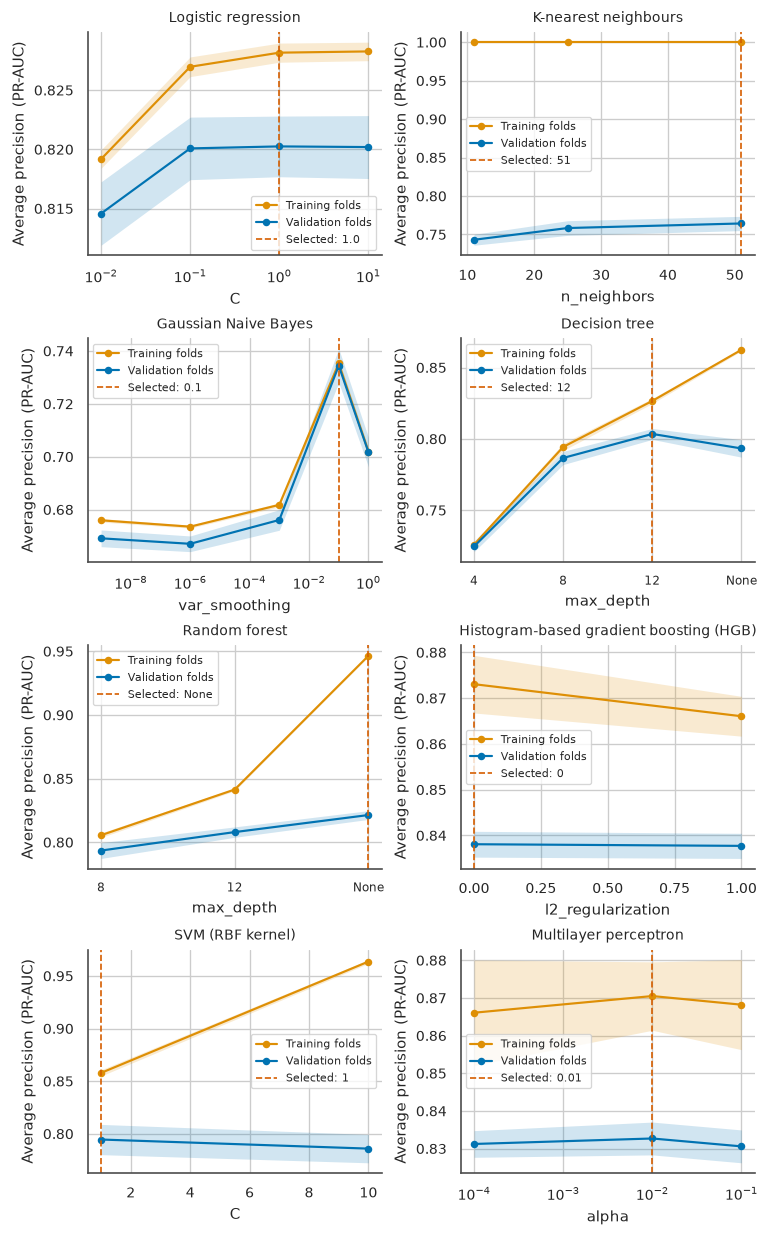

**Validation curve of `hist_gb`** against `l2_regularization`

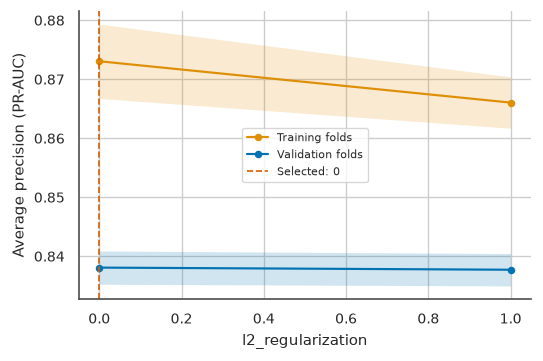

**The validation curves at the selected value**

,parameter,selected value,training AP,validation AP,train - validation,best validation value on the curve
model,,,,,,
logreg,C,1.0,0.828,0.820,0.008,1.0
knn,n_neighbors,51,1.000,0.764,0.236,51
gaussian_nb,var_smoothing,0.1,0.735,0.734,0.001,0.1
decision_tree,max_depth,12,0.827,0.803,0.023,12
random_forest,max_depth,None,0.946,0.821,0.125,None
hist_gb,l2_regularization,0,0.873,0.838,0.035,0
svc_rbf,C,1,0.858,0.795,0.063,1
mlp,alpha,0.01,0.870,0.833,0.038,0.01


**Reading the curves.** In 8 of 8 panels the selected value has the highest validation score on its curve; the other parameters are held at the selected candidate's values in each panel. Setting aside `knn`, whose training score is an artefact of distance weighting (see the note above), `random_forest` has the widest gap at its selected value of `max_depth` (None): training 0.946 against validation 0.821, so the validation score is the figure to quote. The widest gap anywhere on these curves is 0.178 for `svc_rbf` at C = 10 (training 0.964, validation 0.786); it was not selected, and its validation score is 0.786 against 0.795 at the selected value.

**Learning curve of `hist_gb`** (stored by `mlda-train`): grouped folds on a sample of 10,000 of the 81,289 training rows, so the largest training size is 8,000 rows per fit and not the size of the real fits.

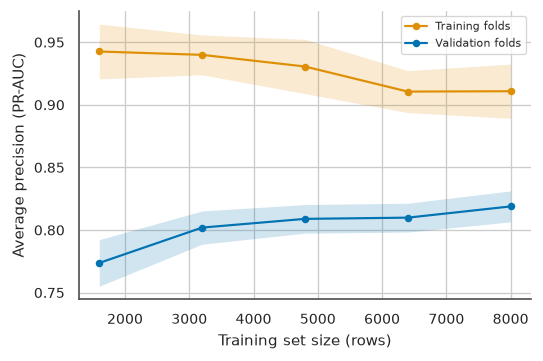

From 6,400 to 8,000 rows the validation average precision goes from 0.810 to 0.819 (standard deviation over folds 0.012), so the curve is no longer rising by more than the spread between folds. The training score at the last point is 0.911, a gap of 0.092. The five-fold score of the same model on all 81,289 training rows is 0.838, 0.019 above the last point of the curve: the sample shows the trend, not the level at full size.

In [43]:
from types import SimpleNamespace

from mlda import plots
from mlda.pipeline import validation_panel


def in_value_order(panel: dict) -> dict:
    # validation_panel keeps the order of the candidate table when a parameter mixes numbers with None
    # (max_depth: 12, None, 8, 4), which draws a zig-zag. Numbers ascending with None last reads as a curve.
    labels = [str(value) for value in panel["x"]]
    try:
        keys = [(label == "None", 0.0 if label == "None" else float(label)) for label in labels]
    except ValueError:                       # a categorical parameter keeps the order of the table
        return panel
    order = sorted(range(len(labels)), key=keys.__getitem__)
    return {**panel, **{key: np.asarray(panel[key])[order] for key in ("x", "train_mean", "train_std", "val_mean", "val_std")}}


panels = {}
for name in MODEL_NAMES:
    # validation_panel only needs the table of candidates and the selected parameters
    holder = SimpleNamespace(cv_results_df=cv_tables[name], best_params=best_params[name])
    panel = validation_panel(holder)
    if panel is not None:
        panels[name] = in_value_order(panel)
print("models with a validation curve:", ", ".join(panels))
if panels:
    show(plots.curves_grid(panels, kind="validation"), "Training and validation average precision against one hyper-parameter, one panel per model")
    leader = cv_summary["average_precision_mean"].idxmax()
    if leader in panels:                      # the single-curve builder, for the model ranked first
        p = panels[leader]
        note(f"**Validation curve of `{leader}`** against `{p['param_name']}`")
        show(plots.validation_curve(p["x"], p["train_mean"], p["train_std"], p["val_mean"], p["val_std"], p["param_name"], best_value=p["best_value"]),
             f"Training and validation average precision of {leader} against {p['param_name']}")

panel_rows = []
for model_name, p in panels.items():
    labels = [str(value) for value in p["x"]]
    chosen = labels.index(str(p["best_value"])) if str(p["best_value"]) in labels else int(np.argmax(p["val_mean"]))
    panel_rows.append(
        {
            "model": model_name,
            "parameter": p["param_name"],
            "selected value": labels[chosen],
            "training AP": p["train_mean"][chosen],
            "validation AP": p["val_mean"][chosen],
            "train - validation": p["train_mean"][chosen] - p["val_mean"][chosen],
            "best validation value on the curve": labels[int(np.argmax(p["val_mean"]))],
        }
    )
if panel_rows:
    panel_table = pd.DataFrame(panel_rows).set_index("model")
    show_table(panel_table, "The validation curves at the selected value")
    artefact = {"knn"} if best_params.get("knn", {}).get("clf__weights") == "distance" else set()   # training score 1.000 by construction
    fair = panel_table[~panel_table.index.isin(artefact)]
    widest = fair["train - validation"].idxmax()
    agree = int((panel_table["selected value"] == panel_table["best validation value on the curve"]).sum())
    points = pd.DataFrame(
        [
            {"model": m, "parameter": p["param_name"], "value": str(v), "training AP": t, "validation AP": a, "gap": t - a}
            for m, p in panels.items() if m not in artefact
            for v, t, a in zip(p["x"], p["train_mean"], p["val_mean"], strict=True)
        ]
    )
    top = points.loc[points["gap"].idxmax()]
    selected_there = panel_table.loc[top["model"], "selected value"] == top["value"]
    note(
        f"**Reading the curves.** In {agree} of {len(panel_table)} panels the selected value has the highest validation score on its curve; the other "
        f"parameters are held at the selected candidate's values in each panel. Setting aside `knn`, whose training score is an artefact of distance weighting "
        f"(see the note above), `{widest}` has the widest gap at its selected value of `{fair.loc[widest, 'parameter']}` ({fair.loc[widest, 'selected value']}): "
        f"training {fair.loc[widest, 'training AP']:.3f} against validation {fair.loc[widest, 'validation AP']:.3f}, so the validation score is the figure to quote. "
        f"The widest gap anywhere on these curves is {top['gap']:.3f} for `{top['model']}` at {top['parameter']} = {top['value']} (training {top['training AP']:.3f}, "
        f"validation {top['validation AP']:.3f})"
        + (", which is the selected value." if selected_there else
           f"; it was not selected, and its validation score is {top['validation AP']:.3f} against {panel_table.loc[top['model'], 'validation AP']:.3f} at the selected value.")
    )

run_info = json.loads((METRICS_DIR / "run_manifest.json").read_text(encoding="utf-8"))
for path in sorted(CV_DIR.glob("*_learning_curve.csv")):
    curve = pd.read_csv(path)
    curve_model = path.name.replace("_learning_curve.csv", "")
    sample_size = run_info.get("learning_curve", {}).get("n_rows")
    note(f"**Learning curve of `{curve_model}`** (stored by `mlda-train`): grouped folds on a sample of "
         f"{sample_size:,} of the {len(y_train):,} training rows, so the largest training size is {int(curve['train_size'].max()):,} rows "
         f"per fit and not the size of the real fits." if sample_size else f"**Learning curve of `{curve_model}`** (stored by `mlda-train`)")
    show(plots.learning_curve(curve["train_size"], curve["train_mean"], curve["train_std"], curve["val_mean"], curve["val_std"]),
         "Training and validation average precision against the number of training rows")
    last, before = curve.iloc[-1], curve.iloc[-2]
    full_score = cv_summary.loc[curve_model, "average_precision_mean"] if curve_model in cv_summary.index else float("nan")
    note(
        f"From {int(before['train_size']):,} to {int(last['train_size']):,} rows the validation average precision goes from {before['val_mean']:.3f} to "
        f"{last['val_mean']:.3f} (standard deviation over folds {last['val_std']:.3f}), so the curve is "
        + ("still rising. " if last["val_mean"] - before["val_mean"] > last["val_std"] else "no longer rising by more than the spread between folds. ")
        + f"The training score at the last point is {last['train_mean']:.3f}, a gap of {last['train_mean'] - last['val_mean']:.3f}. "
        f"The five-fold score of the same model on all {len(y_train):,} training rows is {full_score:.3f}, "
        f"{abs(full_score - last['val_mean']):.3f} {'above' if full_score > last['val_mean'] else 'below'} the last point of the curve: "
        f"the sample shows the trend, not the level at full size."
    )

## D.3 Refit the selected pipelines on the training split

Whatever the mode, every selected pipeline is **trained here**, on the training rows only. In the
default mode a fresh pipeline is built from the model zoo (`build_pipeline`, with the preprocessing
the model prefers), the selected parameters are set, and it is fitted. Models with a row cap
(the SVM and k-nearest neighbours) are fitted on the same stratified sample of whole mine-years
that the search used, because the SVM's training time grows faster than linearly with the number
of rows and k-nearest neighbours needs the distance from every scored row to every stored row.
The random forest, k-nearest neighbours and the SVM use several processes; the number of workers
does not change their results. The table times every fit.

In [44]:
PARALLEL_FIT = {"random_forest", "knn", "svc_rbf"}      # n_jobs speeds these up without changing the fitted model
fitted, fit_seconds, fit_rows = {}, {}, {}
if FULL_RUN:
    for name in MODEL_NAMES:
        fitted[name] = tuned[name].best_pipeline            # already refitted by the search
        fit_seconds[name] = tuned[name].elapsed_seconds     # search plus refit
        fit_rows[name] = len(tuned[name].fit_idx)
else:
    with timer.stage("D.3 refit the selected pipelines"):
        for name in MODEL_NAMES:
            spec = MODEL_ZOO[name]
            cap = fit_cap(spec, quick=False)
            fit_idx = np.arange(len(y_train)) if cap is None else stratified_group_subsample(y_train, g_train, cap)
            pipeline = build_pipeline(spec, default_preprocessor(spec)).set_params(**best_params[name])
            if name in PARALLEL_FIT:
                pipeline.set_params(clf__n_jobs=N_JOBS)
            started = time.perf_counter()
            pipeline.fit(X_train.iloc[fit_idx], y_train[fit_idx])
            fit_seconds[name] = time.perf_counter() - started
            fit_rows[name] = len(fit_idx)
            fitted[name] = pipeline
            print(f"{name:14s} fitted on {len(fit_idx):6,d} rows in {fit_seconds[name]:6.1f} s")

fit_table = pd.DataFrame(
    {
        "estimator": [type(fitted[n][-1]).__name__ for n in MODEL_NAMES],
        "rows fitted": [fit_rows[n] for n in MODEL_NAMES],
        "seconds": [fit_seconds[n] for n in MODEL_NAMES],
        "design-matrix columns": [fitted[n][0].transform(X_train.iloc[:5]).shape[1] for n in MODEL_NAMES],
    },
    index=MODEL_NAMES,
)
show_table(fit_table, "Training time of each selected pipeline" + (" (search plus refit)" if FULL_RUN else " (refit only)"))

**Training time of each selected pipeline (search plus refit)**

,estimator,rows fitted,seconds,design-matrix columns
logreg,LogisticRegression,81289,67.256,552
knn,KNeighborsClassifier,39999,294.050,555
gaussian_nb,GaussianNB,81289,26.696,552
decision_tree,DecisionTreeClassifier,81289,148.904,552
random_forest,RandomForestClassifier,81289,138.906,552
hist_gb,HistGradientBoostingClassifier,81289,549.719,552
svc_rbf,CalibratedClassifierCV,9913,"1,266.439",554
mlp,MLPClassifier,81289,152.115,552


# E. Model evaluation

**Protocol.** Every fitted pipeline scores the held-out test fold once. Nothing in this section
is fitted on test rows, and no threshold is tuned on them: the decision thresholds were chosen on
the **out-of-fold probabilities of the training rows** (`thresholds.json`) and are applied to the
test fold unchanged. Besides the models, four reference rules are scored the same way, so the
questions are which model is best and whether any model beats what a safety officer could do by
hand. The lookup baseline predicts the training lost-time rate of the cell
nature of injury x body part x commodity.

**Metrics.** The brief's columns are **TPR** (true positive rate = **recall** = TP / (TP + FN),
the share of lost-time cases that are caught), **TNR** (true negative rate = specificity = TN /
(TN + FP)), **AUC** (area under the ROC curve, threshold-free), **precision** (TP / (TP + FP)),
**F1** (harmonic mean of precision and recall), **PR-AUC** (average precision, the primary
metric) and **accuracy**. Balanced accuracy, the Matthews correlation coefficient (MCC) and the
Brier score (mean squared error of the probabilities, a calibration measure) are added. TPR and
Recall are the same number; both columns are shown because the brief lists both.

**Two operating points.** At the default threshold of 0.5 the classifier is treated as a plain
yes/no rule. The business setting is different: a missed lost-time case costs far more than an
unnecessary review (assumed USD 4,000 against USD 200, a 20:1 ratio), and reviewers can handle
about three of every four cases. The **capacity operating point** is therefore the out-of-fold
threshold at which **specificity is 0.40** (about 75 % of cases are flagged); the success
criteria S1-S6 were fixed before modelling and are tested at that point.

## E.1 Score the test fold

Each fitted pipeline predicts the probability of lost time for the 20,320 test rows, and the four
reference rules do the same. The first table is a reproducibility check: it sets the scores
computed here against the test predictions that `mlda-train` stored. They agree when the stored run
used the same fitting rows and parameters; differences of this kind are the first thing to look
at if a number in the report and a number in the notebook disagree.

In [45]:
from mlda.baselines import fit_baselines
from mlda.config import COST_RATIOS, METRICS_DIR, PREDICTIONS_DIR
from mlda.evaluation import (
    bootstrap_ci,
    by_sector,
    classification_metrics,
    compare_models,
    cost_from_counts,
    curves,
    mcnemar_test,
    paired_fold_test,
    threshold_for_flag_rate,
    threshold_sweep,
)
from mlda.operating import (
    FLAG_KEY,
    LOOKUP_BASELINE,
    OPERATING_KEY,
    all_positive_floor,
    evaluate_on_test,
    model_criteria,
    oof_thresholds,
)


def predict_proba_chunks(pipeline, frame, workers=N_JOBS):
    # Score row chunks in threads: libsvm and numpy release the GIL, and the result equals one predict_proba call.
    pieces = np.array_split(np.arange(len(frame)), workers * 2)
    with ThreadPoolExecutor(workers) as pool:
        parts = list(pool.map(lambda ix: pipeline.predict_proba(frame.iloc[ix])[:, 1], pieces))
    return np.concatenate(parts)


THREADED_PREDICT = {"svc_rbf"}                  # the SVM needs about 100 s for 20,000 rows on one thread
proba, predict_seconds = {}, {}
with timer.stage("E.1 score the test fold"):
    for name in MODEL_NAMES:
        started = time.perf_counter()
        if name in THREADED_PREDICT:
            proba[name] = predict_proba_chunks(fitted[name], X_test)
        else:
            proba[name] = fitted[name].predict_proba(X_test)[:, 1]
        predict_seconds[name] = time.perf_counter() - started
    if "svc_rbf" in MODEL_NAMES:                # chunked scoring must not change the numbers
        sample_rows = X_test.iloc[:300]
        assert np.allclose(predict_proba_chunks(fitted["svc_rbf"], sample_rows), fitted["svc_rbf"].predict_proba(sample_rows)[:, 1])

baselines = fit_baselines(X_train, y_train)     # the four reference rules, fitted on the training rows only
for name, model in baselines.items():
    proba[name] = model.predict_proba(X_test)[:, 1]
ALL_NAMES = [*MODEL_NAMES, *baselines]

stored_thresholds = json.loads((METRICS_DIR / "thresholds.json").read_text(encoding="utf-8"))
thresholds = {name: stored_thresholds[name] for name in ALL_NAMES}
if FULL_RUN:                                    # thresholds from the out-of-fold probabilities of this notebook's own search
    for name in MODEL_NAMES:
        thresholds[name] = oof_thresholds(y_train, tuned[name].oof_proba)

evaluations = {name: evaluate_on_test(y_test, proba[name], sector_test, thresholds[name]) for name in ALL_NAMES}

# Reproducibility: the live scores against the test predictions that mlda-train stored.
stored_predictions = pd.read_parquet(PREDICTIONS_DIR / "test_predictions.parquet")
assert np.array_equal(stored_predictions["row"].to_numpy(), test_idx)
stored_baselines = json.loads((METRICS_DIR / "baselines.json").read_text(encoding="utf-8"))


def stored_auc(name):
    if name in baselines:
        return stored_baselines[name]["test"]["at_0.5"]["roc_auc"]
    return json.loads((METRICS_DIR / f"{name}.json").read_text(encoding="utf-8"))["test"]["at_0.5"]["roc_auc"]


reproduce = pd.DataFrame(
    {
        name: {
            "ROC-AUC (this notebook)": evaluations[name]["at_0.5"]["roc_auc"],
            "ROC-AUC (stored by mlda-train)": stored_auc(name),
            "largest |p difference|": float(np.abs(proba[name] - stored_predictions[f"proba_{name}"].to_numpy()).max()),
        }
        for name in ALL_NAMES
    }
).T
reproduce["largest |p difference|"] = reproduce["largest |p difference|"].map("{:.1e}".format)
show_table(reproduce, "Live test scores against the stored predictions (identical when the stored run used the same fit rows)")
show_table(
    pd.DataFrame({f"seconds to score {len(X_test):,} test rows": predict_seconds}),
    "Scoring time",
)

**Live test scores against the stored predictions (identical when the stored run used the same fit rows)**

,ROC-AUC (this notebook),ROC-AUC (stored by mlda-train),largest |p difference|
logreg,0.829,0.829,0.0e+00
knn,0.773,0.773,0.0e+00
gaussian_nb,0.741,0.741,0.0e+00
decision_tree,0.817,0.817,0.0e+00
random_forest,0.833,0.833,0.0e+00
hist_gb,0.843,0.843,0.0e+00
svc_rbf,0.820,0.820,0.0e+00
mlp,0.839,0.839,0.0e+00
majority,0.500,0.500,0.0e+00
all_positive,0.500,0.500,0.0e+00


**Scoring time**

,"seconds to score 20,320 test rows"
logreg,0.106
knn,3.027
gaussian_nb,0.206
decision_tree,0.106
random_forest,0.645
hist_gb,0.330
svc_rbf,8.373
mlp,0.111


## E.2 Comparison at threshold 0.5

The table is in the order the brief asks for: TPR, TNR, AUC, Recall, Precision, F1, PR-AUC and
Accuracy, sorted by PR-AUC, with the models and the four reference rules together. A model is
only worth deploying if it beats the lookup rule, which needs no training beyond a table of
rates, and the two trivial rules show what accuracy and F1 mean when nothing is learnt (the
all-positive rule has an F1 of about 0.65 without looking at a single feature). The second table
adds balanced accuracy, MCC and Brier. The third compares the cross-validated estimate with the
test score: a test score far below the cross-validation mean would indicate overfitting to the
training folds, and a close match shows that the selection procedure was honest.

In [46]:
lookup_name = LOOKUP_BASELINE
at_half = compare_models({name: evaluations[name]["at_0.5"] for name in ALL_NAMES})
show_table(at_half, "Held-out test fold, threshold 0.5 (columns in the order of the brief; sorted by PR-AUC)")
note(f"*Footnote: {at_half.attrs['footnote']}*")

extras = compare_models({name: evaluations[name]["at_0.5"] for name in ALL_NAMES}, extra_columns=True)[
    ["Balanced accuracy", "MCC", "Brier", "Log loss", "Flag rate"]
]
show_table(extras, "Further metrics at threshold 0.5 (Brier: lower is better)")

ranking = list(cv_summary["average_precision_mean"].sort_values(ascending=False).index)   # selection uses training folds only
best = ranking[0]
generalisation = pd.DataFrame(
    {
        "CV average precision (mean)": cv_summary["average_precision_mean"],
        "CV std over folds": cv_summary["average_precision_std"],
        "test PR-AUC": [evaluations[n]["at_0.5"]["pr_auc"] for n in cv_summary.index],
    },
    index=cv_summary.index,
)
generalisation["test minus CV"] = generalisation["test PR-AUC"] - generalisation["CV average precision (mean)"]
show_table(generalisation.loc[ranking], "Cross-validation estimate against the held-out test score")
print(f"model ranked first by cross-validated average precision: {best}")

by_pr = at_half["PR-AUC"].drop(["majority", "all_positive"])
beating = [n for n in MODEL_NAMES if at_half.loc[n, "PR-AUC"] > at_half.loc[lookup_name, "PR-AUC"]]
note(
    f"**Reading the tables.** `{by_pr.index[0]}` has the highest test PR-AUC ({by_pr.iloc[0]:.3f}) and ROC-AUC "
    f"{at_half.loc[by_pr.index[0], 'AUC']:.3f}. {len(beating)} of the {len(MODEL_NAMES)} models beat the lookup rule on PR-AUC "
    f"({at_half.loc[lookup_name, 'PR-AUC']:.3f}); the others are {', '.join(f'`{n}`' for n in MODEL_NAMES if n not in beating) or 'none'}. "
    f"Plain accuracy at 0.5 ranges from {at_half.loc[MODEL_NAMES, 'Accuracy'].min():.3f} to {at_half.loc[MODEL_NAMES, 'Accuracy'].max():.3f} across the models, "
    f"against {at_half.loc['majority', 'Accuracy']:.3f} for the majority rule. The largest difference between the cross-validation estimate and the test score is "
    f"{generalisation['test minus CV'].abs().max():.3f} (`{generalisation['test minus CV'].abs().idxmax()}`)."
)

**Held-out test fold, threshold 0.5 (columns in the order of the brief; sorted by PR-AUC)**

,TPR,TNR,AUC,Recall,Precision,F1,PR-AUC,Accuracy
model,,,,,,,,
hist_gb,0.738,0.785,0.843,0.738,0.764,0.751,0.841,0.762
mlp,0.749,0.769,0.839,0.749,0.754,0.752,0.837,0.759
random_forest,0.707,0.799,0.833,0.707,0.769,0.737,0.827,0.755
logreg,0.744,0.758,0.829,0.744,0.744,0.744,0.825,0.751
svc_rbf,0.731,0.763,0.820,0.731,0.744,0.737,0.811,0.747
decision_tree,0.676,0.799,0.817,0.676,0.761,0.716,0.805,0.739
lookup_nature_bodypart_coal,0.655,0.801,0.804,0.655,0.756,0.702,0.790,0.730
knn,0.589,0.807,0.773,0.589,0.743,0.657,0.770,0.701
gaussian_nb,0.524,0.802,0.741,0.524,0.715,0.605,0.741,0.667


*Footnote: TPR (true positive rate) and Recall are the same quantity, TP / (TP + FN); TNR is specificity, TN / (TN + FP). Both names are kept because the brief lists both.*

**Further metrics at threshold 0.5 (Brier: lower is better)**

,Balanced accuracy,MCC,Brier,Log loss,Flag rate
model,,,,,
hist_gb,0.761,0.523,0.161,0.489,0.469
mlp,0.759,0.518,0.163,0.495,0.483
random_forest,0.753,0.510,0.170,0.515,0.447
logreg,0.751,0.503,0.169,0.510,0.486
svc_rbf,0.747,0.494,0.173,0.521,0.477
decision_tree,0.738,0.480,0.174,0.578,0.432
lookup_nature_bodypart_coal,0.728,0.461,0.179,0.600,0.421
knn,0.698,0.407,0.195,0.573,0.385
gaussian_nb,0.663,0.341,0.298,1.778,0.356


**Cross-validation estimate against the held-out test score**

,CV average precision (mean),CV std over folds,test PR-AUC,test minus CV
model,,,,
hist_gb,0.838,0.003,0.841,0.003
mlp,0.833,0.004,0.837,0.004
random_forest,0.821,0.003,0.827,0.005
logreg,0.820,0.003,0.825,0.005
decision_tree,0.803,0.004,0.805,0.001
svc_rbf,0.795,0.014,0.811,0.017
knn,0.764,0.009,0.770,0.005
gaussian_nb,0.734,0.006,0.741,0.006


model ranked first by cross-validated average precision: hist_gb


**Reading the tables.** `hist_gb` has the highest test PR-AUC (0.841) and ROC-AUC 0.843. 6 of the 8 models beat the lookup rule on PR-AUC (0.790); the others are `knn`, `gaussian_nb`. Plain accuracy at 0.5 ranges from 0.667 to 0.762 across the models, against 0.514 for the majority rule. The largest difference between the cross-validation estimate and the test score is 0.017 (`svc_rbf`).

## E.3 Operating point at specificity 0.40

The same metrics at the capacity operating point: the threshold is the one that gave a
specificity of 0.40 on the out-of-fold training probabilities, and the test fold shows what that
threshold does on unseen rows. The specificity actually reached on the test fold should be close
to 0.40; recall is the share of lost-time cases caught when about three of four cases are
reviewed. The two constant rules are left out, because a rule that gives every case the same
score has no threshold that reaches a given specificity.

In [47]:
informative = [name for name in ALL_NAMES if name not in ("majority", "all_positive")]
at_operating = compare_models(
    {name: evaluations[name][f"at_{OPERATING_KEY}"] for name in informative}, extra_columns=True
)
show_table(at_operating, "Test fold at the out-of-fold threshold for specificity 0.40 (sorted by PR-AUC)")
model_rows = at_operating.loc[MODEL_NAMES]

# The thresholds above flag different shares of the cases, so recall is also compared at one common flag rate:
# the cut-off is taken from the scores alone (the top share of test scores), and the labels only count the hits.
common_rate = float(model_rows["Flag rate"].median())
at_common = pd.DataFrame(
    {
        name: classification_metrics(y_test, proba[name], threshold_for_flag_rate(y_test, proba[name], common_rate))
        for name in MODEL_NAMES
    }
).T[["flag_rate", "recall", "specificity", "precision"]]
at_common.columns = ["Flag rate", "TPR", "TNR", "Precision"]
show_table(at_common.sort_values("TPR", ascending=False), f"Models at the same review workload: the {common_rate:.1%} of test cases with the highest scores are flagged")
note(
    f"**Reading the table.** On the test fold the specificity of the models at this threshold runs from {model_rows['TNR'].min():.3f} to "
    f"{model_rows['TNR'].max():.3f} (target 0.40), and the share of cases flagged from {model_rows['Flag rate'].min():.1%} to {model_rows['Flag rate'].max():.1%}. "
    f"Recall runs from {model_rows['TPR'].min():.3f} (`{model_rows['TPR'].idxmin()}`) to {model_rows['TPR'].max():.3f} (`{model_rows['TPR'].idxmax()}`), "
    f"and the lookup rule reaches {at_operating.loc[lookup_name, 'TPR']:.3f} at a flag rate of {at_operating.loc[lookup_name, 'Flag rate']:.1%}. "
    f"The flag rates differ (`{model_rows['Flag rate'].idxmax()}` flags {model_rows['Flag rate'].max():.1%} and `{model_rows['Flag rate'].idxmin()}` "
    f"{model_rows['Flag rate'].min():.1%}), so these recalls do not compare models at equal workload. At the same workload ({common_rate:.1%} flagged) recall runs from "
    f"{at_common['TPR'].min():.3f} (`{at_common['TPR'].idxmin()}`) to {at_common['TPR'].max():.3f} (`{at_common['TPR'].idxmax()}`); that is the fairer measure of "
    f"how many more lost-time cases one model catches than another for the same review effort."
)

**Test fold at the out-of-fold threshold for specificity 0.40 (sorted by PR-AUC)**

,TPR,TNR,AUC,Recall,Precision,F1,PR-AUC,Accuracy,Balanced accuracy,MCC,Brier,Log loss,Flag rate,Threshold
model,,,,,,,,,,,,,,
hist_gb,0.943,0.403,0.843,0.943,0.599,0.733,0.841,0.666,0.673,0.409,0.161,0.489,0.765,0.210
mlp,0.948,0.373,0.839,0.948,0.588,0.726,0.837,0.652,0.660,0.389,0.163,0.495,0.783,0.187
random_forest,0.935,0.408,0.833,0.935,0.599,0.730,0.827,0.664,0.672,0.401,0.170,0.515,0.759,0.290
logreg,0.934,0.405,0.829,0.934,0.597,0.728,0.825,0.662,0.669,0.396,0.169,0.510,0.760,0.222
svc_rbf,0.927,0.411,0.820,0.927,0.598,0.727,0.811,0.661,0.669,0.391,0.173,0.521,0.753,0.237
decision_tree,0.932,0.376,0.817,0.932,0.585,0.719,0.805,0.646,0.654,0.368,0.174,0.578,0.774,0.239
lookup_nature_bodypart_coal,0.916,0.402,0.804,0.916,0.591,0.719,0.790,0.652,0.659,0.368,0.179,0.600,0.753,0.225
knn,0.886,0.412,0.773,0.886,0.588,0.707,0.770,0.642,0.649,0.337,0.195,0.573,0.733,0.308
gaussian_nb,0.868,0.407,0.741,0.868,0.580,0.696,0.741,0.631,0.637,0.308,0.298,1.778,0.727,0.001


**Models at the same review workload: the 75.9% of test cases with the highest scores are flagged**

,Flag rate,TPR,TNR,Precision
hist_gb,0.759,0.940,0.412,0.602
mlp,0.759,0.940,0.412,0.601
random_forest,0.759,0.935,0.407,0.599
logreg,0.759,0.933,0.405,0.597
svc_rbf,0.759,0.930,0.402,0.595
decision_tree,0.759,0.924,0.398,0.592
knn,0.759,0.903,0.377,0.578
gaussian_nb,0.759,0.890,0.364,0.570


**Reading the table.** On the test fold the specificity of the models at this threshold runs from 0.373 to 0.412 (target 0.40), and the share of cases flagged from 72.7% to 78.3%. Recall runs from 0.868 (`gaussian_nb`) to 0.948 (`mlp`), and the lookup rule reaches 0.916 at a flag rate of 75.3%. The flag rates differ (`mlp` flags 78.3% and `gaussian_nb` 72.7%), so these recalls do not compare models at equal workload. At the same workload (75.9% flagged) recall runs from 0.890 (`gaussian_nb`) to 0.940 (`hist_gb`); that is the fairer measure of how many more lost-time cases one model catches than another for the same review effort.

## E.4 ROC and precision-recall curves

The **ROC curve** plots the true positive rate against the false positive rate (1 - TNR) as the
threshold moves; the area under it is the probability that a random lost-time case is scored
above a random other case, and the diagonal is a coin flip. The **precision-recall curve** shows
precision against recall; because the classes are balanced its baseline is the prevalence (0.49),
and it shows more clearly than the ROC curve what a high recall costs in precision. Models that
lie on top of each other cannot be separated by these plots; the numbers in E.2 and the tests in
E.9 decide.

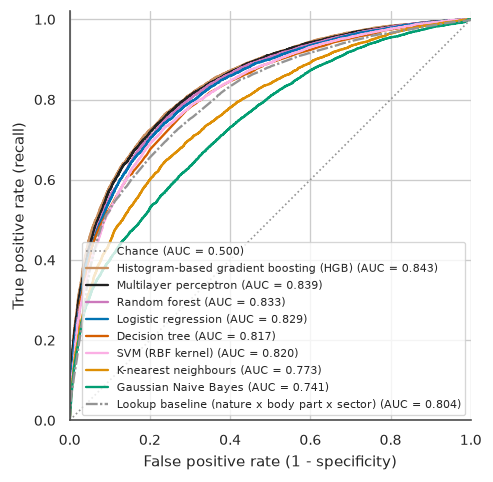

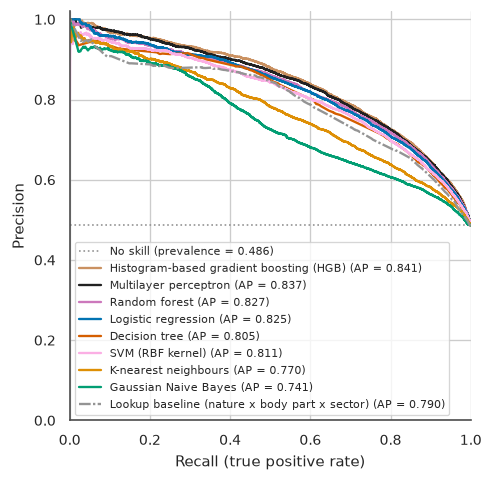

In [48]:
shown = [*ranking, LOOKUP_BASELINE]
model_curves = {name: curves(y_test, proba[name]) for name in ALL_NAMES}
show(plots.roc_curves({n: model_curves[n]["roc"] for n in shown}, {n: evaluations[n]["at_0.5"]["roc_auc"] for n in shown}),
     "ROC curves of the models and the lookup baseline on the test fold")
show(plots.pr_curves({n: model_curves[n]["pr"] for n in shown}, float(y_test.mean()), {n: evaluations[n]["at_0.5"]["pr_auc"] for n in shown}),
     "Precision-recall curves of the models and the lookup baseline on the test fold")

## E.5 Confusion matrices

A confusion matrix counts the four outcomes of a decision rule: true negatives and true positives
on the diagonal, false positives (unnecessary reviews) and false negatives (missed lost-time
cases) off it. The percentages are row percentages, so the bottom-right cell is the TPR and the
top-left cell the TNR. The four panels compare the best model and the lookup baseline at the
default threshold and at the capacity operating point. Moving to the operating point trades
specificity for recall in both; the question is how much recall each model buys for the same
review workload.

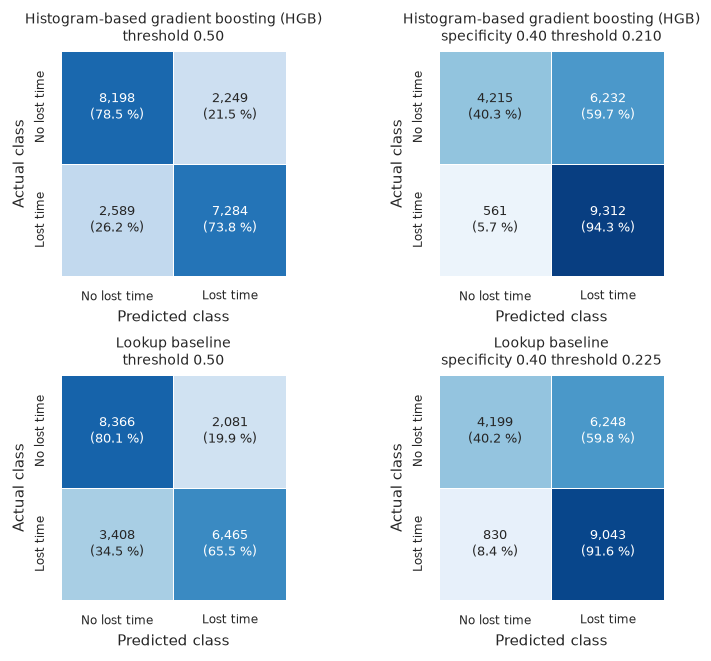

**Confusion counts of every model and rule on the test fold (TN, FP, FN, TP)**

threshold 0.5                    specificity 0.40                  
                                       TN     FP    FN    TP               TN    FP    FN    TP
logreg                               7923   2524  2526  7347             4229  6218   656  9217
knn                                  8435   2012  4054  5819             4305  6142  1123  8750
gaussian_nb                          8382   2065  4696  5177             4249  6198  1304  8569
decision_tree                        8348   2099  3196  6677             3927  6520   672  9201
random_forest                        8352   2095  2888  6985             4265  6182   640  9233
hist_gb                              8198   2249  2589  7284             4215  6232   561  9312
svc_rbf                              7967   2480  2660  7213             4291  6156   725  9148
mlp                                  8033   2414  2474  7399             3895  6552   514  9359
majority                            10447      0  9873     0             <NA>  <NA>  <NA>  <NA>
all_positive                            0  10447     0  9873             <NA>  <NA>  <NA>  <NA>
rule_not_cut_or_dust                 4416   6031  1005  8868             4416  6031  1005  8868
lookup_nature_bodypart_coal          8366   2081  3408  6465             4199  6248   830  9043

**Reading the matrices.** At the capacity operating point `hist_gb` flags 76.5% of the cases and misses 561 of 9,873 lost-time cases (5.7%); the lookup rule flags 75.3% and misses 830 (8.4%). The model therefore catches 269 more lost-time cases and causes 16 fewer unnecessary reviews.

In [49]:
def confusion(metrics):
    return np.array([[metrics["tn"], metrics["fp"]], [metrics["fn"], metrics["tp"]]])


lookup = LOOKUP_BASELINE
matrices = {
    f"{plots.display_name(best)}\nthreshold 0.50": confusion(evaluations[best]["at_0.5"]),
    f"{plots.display_name(best)}\nspecificity 0.40 threshold {thresholds[best][OPERATING_KEY]:.3f}": confusion(evaluations[best][f"at_{OPERATING_KEY}"]),
    "Lookup baseline\nthreshold 0.50": confusion(evaluations[lookup]["at_0.5"]),
    f"Lookup baseline\nspecificity 0.40 threshold {thresholds[lookup][OPERATING_KEY]:.3f}": confusion(evaluations[lookup][f"at_{OPERATING_KEY}"]),
}
show(plots.confusion_matrices(matrices), "Four confusion matrices: the best model and the lookup baseline at threshold 0.5 and at the specificity 0.40 threshold")
constant_rules = ("majority", "all_positive")          # constant scores have no threshold for a given specificity
count_rows = {}
for name in ALL_NAMES:
    row = {("threshold 0.5", k.upper()): evaluations[name]["at_0.5"][k] for k in ("tn", "fp", "fn", "tp")}
    row.update(
        {("specificity 0.40", k.upper()): (np.nan if name in constant_rules else evaluations[name][f"at_{OPERATING_KEY}"][k]) for k in ("tn", "fp", "fn", "tp")}
    )
    count_rows[name] = row
count_table = pd.DataFrame(count_rows).T
count_table.columns = pd.MultiIndex.from_tuples(count_table.columns)
show_table(count_table.astype("Int64"), "Confusion counts of every model and rule on the test fold (TN, FP, FN, TP)")

at_op_best, at_op_lookup = evaluations[best][f"at_{OPERATING_KEY}"], evaluations[lookup][f"at_{OPERATING_KEY}"]
note(
    f"**Reading the matrices.** At the capacity operating point `{best}` flags {at_op_best['flag_rate']:.1%} of the cases and misses {at_op_best['fn']:,} of "
    f"{at_op_best['tp'] + at_op_best['fn']:,} lost-time cases ({1 - at_op_best['recall']:.1%}); the lookup rule flags {at_op_lookup['flag_rate']:.1%} and misses "
    f"{at_op_lookup['fn']:,} ({1 - at_op_lookup['recall']:.1%}). The model therefore catches {at_op_lookup['fn'] - at_op_best['fn']:,} more lost-time cases and causes "
    f"{abs(at_op_best['fp'] - at_op_lookup['fp']):,} {'fewer' if at_op_best['fp'] < at_op_lookup['fp'] else 'more'} unnecessary reviews."
)

## E.6 Threshold, cost and the review-everyone floor

The expected cost per 1,000 cases of a decision rule is 1000 x (FN x C_FN + FP x C_FP) / N with
C_FP = USD 200 and C_FN = ratio x C_FP. The cost ratio is an assumption, so the analysis covers
2:1, 3:1, 5:1, 10:1, 20:1 and 30:1. A rule that **reviews every case** costs the same at every
ratio (it has no missed cases), and a classifier is worth using only where it costs less than that
floor. As the ratio grows, the cheapest policy moves towards reviewing every case, so the saving
over the floor shrinks and the cost curve of any model flattens onto it. The curve below shows the
cost against the threshold for each ratio, with the three operating points marked. The table gives, for each ratio, the cost at the out-of-fold optimal
threshold on the test fold, with the floor and the lookup rule for comparison.

**Expected cost per 1,000 cases on the test fold (USD)**

,threshold (out-of-fold optimum),"cost per 1,000 (hist_gb)","cost per 1,000 (lookup)","cost per 1,000 (review everyone)",saving against the floor,recall,specificity,flag rate
FN : FP cost ratio,,,,,,,,
2 : 1,0.335,65896,73553,102825,36929,0.867,0.610,0.622
3 : 1,0.235,77697,85472,102825,25128,0.928,0.447,0.735
5 : 1,0.165,87638,98061,102825,15187,0.965,0.315,0.821
10 : 1,0.108,98415,102825,102825,4409,0.987,0.165,0.909
20 : 1,0.058,102687,102825,102825,138,0.998,0.032,0.983
30 : 1,0.037,102520,102825,102825,305,1.000,0.003,0.998


**Reading the table.** At 2:1 the out-of-fold optimal threshold gives a cost of 65,896 against 102,825 for reviewing everyone, a saving of 36%; at 30:1 the saving is 0.3% and the optimal threshold (0.037) flags 99.8% of the cases. The lookup rule costs 73,553 at 2:1, so the model's saving over the lookup rule there is 10%.

**At the assumed ratio of 20:1** the out-of-fold optimum saves USD 138 per 1,000 cases against reviewing everyone (0.1% of the floor) and flags 98.3% of the cases, above the 76.5% flagged at the capacity operating point, so the cost optimum asks reviewers to take more cases than the capacity constraint allows. The saving over the floor is small at this ratio, which is why the headline operating point is the capacity point (specificity 0.40) and not the cost optimum.

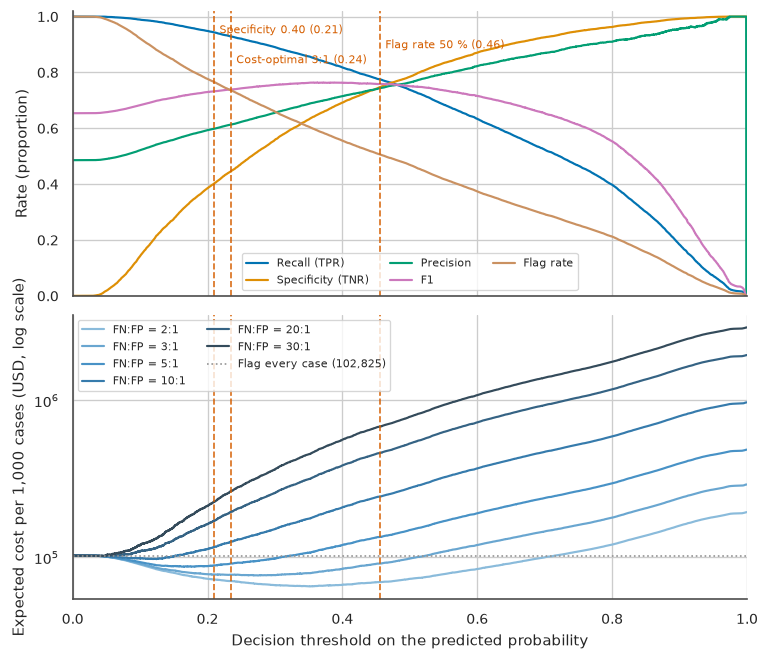

In [50]:
floor = all_positive_floor(y_test)                       # cost of reviewing every case, by ratio
lookup_cost = {key: value["cost_per_1000"] for key, value in evaluations[lookup]["cost_optimal"].items()}
cost_rows = []
for ratio in COST_RATIOS:
    key = str(int(ratio))
    entry = evaluations[best]["cost_optimal"][key]
    cost_rows.append(
        {
            "FN : FP cost ratio": f"{int(ratio)} : 1",
            "threshold (out-of-fold optimum)": entry["threshold"],
            f"cost per 1,000 ({best})": entry["cost_per_1000"],
            "cost per 1,000 (lookup)": lookup_cost[key],
            "cost per 1,000 (review everyone)": floor[key],
            "saving against the floor": floor[key] - entry["cost_per_1000"],
            "recall": entry["recall"],
            "specificity": entry["specificity"],
            "flag rate": entry["flag_rate"],
        }
    )
cost_table_frame = pd.DataFrame(cost_rows).set_index("FN : FP cost ratio")
dollar_columns = [c for c in cost_table_frame.columns if c.startswith("cost per 1,000") or c == "saving against the floor"]
show_table(cost_table_frame.astype({c: float for c in dollar_columns}).round({c: 0 for c in dollar_columns}).astype({c: int for c in dollar_columns}),
           "Expected cost per 1,000 cases on the test fold (USD)")
low, high = cost_table_frame.iloc[0], cost_table_frame.iloc[-1]
note(
    f"**Reading the table.** At 2:1 the out-of-fold optimal threshold gives a cost of {low[f'cost per 1,000 ({best})']:,.0f} against "
    f"{low['cost per 1,000 (review everyone)']:,.0f} for reviewing everyone, a saving of {low['saving against the floor'] / low['cost per 1,000 (review everyone)']:.0%}; "
    f"at 30:1 the saving is {high['saving against the floor'] / high['cost per 1,000 (review everyone)']:.1%} and the optimal threshold ({high['threshold (out-of-fold optimum)']:.3f}) flags "
    f"{high['flag rate']:.1%} of the cases. The lookup rule costs {low['cost per 1,000 (lookup)']:,.0f} at 2:1, so the model's saving over the lookup rule there is "
    f"{(low['cost per 1,000 (lookup)'] - low[f'cost per 1,000 ({best})']) / low['cost per 1,000 (lookup)']:.0%}."
)

at_twenty = cost_table_frame.loc["20 : 1"]
capacity_flag = evaluations[best][f"at_{OPERATING_KEY}"]["flag_rate"]
note(
    f"**At the assumed ratio of 20:1** the out-of-fold optimum saves USD {at_twenty['saving against the floor']:,.0f} per 1,000 cases against reviewing everyone "
    f"({at_twenty['saving against the floor'] / at_twenty['cost per 1,000 (review everyone)']:.1%} of the floor) and flags {at_twenty['flag rate']:.1%} of the cases, "
    + (f"above the {capacity_flag:.1%} flagged at the capacity operating point, so the cost optimum asks reviewers to take more cases than the capacity constraint allows"
       if at_twenty["flag rate"] > capacity_flag else f"within the {capacity_flag:.1%} flagged at the capacity operating point")
    + ". The saving over the floor is small at this ratio, which is why the headline operating point is the capacity point (specificity 0.40) and not the cost optimum."
)

sweep = threshold_sweep(y_test, proba[best])
chosen = {
    "Specificity 0.40": thresholds[best][OPERATING_KEY],
    "Flag rate 50 %": thresholds[best][FLAG_KEY],
    "Cost-optimal 3:1": thresholds[best]["cost_optimal"]["3"],
}
floor_at_two = cost_from_counts(0, int((y_test == 0).sum()), int(y_test.size), COST_RATIOS[0])
show(plots.threshold_cost_curve(sweep, chosen=chosen, cost_floor=floor_at_two),
     "Classification rates and expected cost per 1,000 cases against the decision threshold for six cost ratios")

## E.7 Calibration

A model is **calibrated** if, among the cases it scores at 0.7, about 70 % really are lost-time
cases. The reliability diagram bins the predicted probabilities and plots the observed lost-time
rate in each bin; points on the diagonal are calibrated. A point below the diagonal means that the
model over-estimates the risk in that bin and a point above it that the model under-estimates it.
A curve flatter than the diagonal (above it at low scores and below it at high scores) is
over-confident; a steeper curve is under-confident. The Brier score summarises the same property
in one number. Calibration matters here because the cost
thresholds assume that a probability means what it says: a threshold of 0.25 is only the right
one for a 3:1 cost ratio if the scores are calibrated.

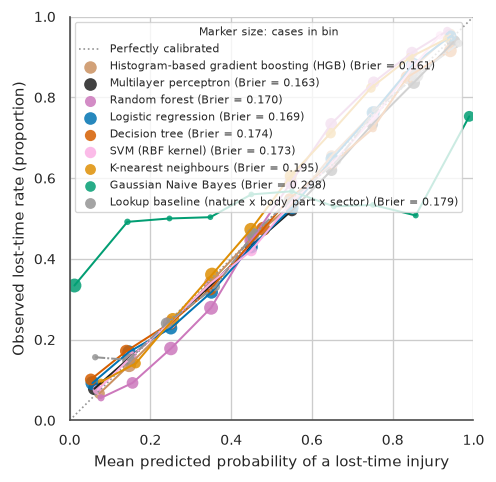

**Calibration slope of each model: the weighted slope of the observed rate on the predicted probability (1 = on the diagonal)**

,slope of observed on predicted,observed minus predicted below 0.25,reading
hist_gb,1.035,-0.009,close to the diagonal
mlp,0.969,0.006,close to the diagonal
random_forest,1.231,-0.042,under-confident (steeper than the diagonal)
logreg,1.001,0.029,close to the diagonal
decision_tree,0.952,0.024,close to the diagonal
svc_rbf,1.022,0.002,close to the diagonal
knn,1.120,-0.002,under-confident (steeper than the diagonal)
gaussian_nb,0.407,0.308,over-confident (flatter than the diagonal)
lookup_nature_bodypart_coal,0.980,0.032,close to the diagonal


**Brier score on the test fold (the constant predictor scores 0.25)**

,Brier score,constant predictor at the prevalence
hist_gb,0.161,0.250
mlp,0.163,0.250
random_forest,0.170,0.250
logreg,0.169,0.250
decision_tree,0.174,0.250
svc_rbf,0.173,0.250
knn,0.195,0.250
gaussian_nb,0.298,0.250
lookup_nature_bodypart_coal,0.179,0.250


**Reading the diagram.** The lowest Brier score is `hist_gb` (0.161) and the highest `gaussian_nb` (0.298). `gaussian_nb` scores worse than the constant predictor (0.25), so its probabilities are unusable as probabilities even if it ranks cases well. Over-confident (flatter than the diagonal): `gaussian_nb`. Under-confident (steeper than the diagonal): `random_forest`, `knn`. Points far from the diagonal in a thin bin carry little weight, which is why the slope is weighted by the bin size.

In [51]:
show(plots.calibration({n: model_curves[n]["calibration"] for n in shown}, {n: evaluations[n]["at_0.5"]["brier"] for n in shown}),
     "Reliability diagram: predicted probability against observed lost-time rate for each model")
calibration_rows = {}
for name in shown:
    bins = model_curves[name]["calibration"].dropna()
    if len(bins) < 3:                        # a constant score has one bin and no slope
        continue
    slope = float(np.polyfit(bins["mean_predicted"], bins["fraction_positive"], 1, w=np.sqrt(bins["count"]))[0])
    low = bins[bins["mean_predicted"] < 0.25]
    calibration_rows[name] = {
        "slope of observed on predicted": slope,
        "observed minus predicted below 0.25": float((low["fraction_positive"] - low["mean_predicted"]).mean()) if len(low) else np.nan,
        "reading": "over-confident (flatter than the diagonal)" if slope < 0.9 else "under-confident (steeper than the diagonal)" if slope > 1.1 else "close to the diagonal",
    }
slopes = pd.DataFrame(calibration_rows).T.astype({"slope of observed on predicted": float, "observed minus predicted below 0.25": float})
show_table(slopes, "Calibration slope of each model: the weighted slope of the observed rate on the predicted probability (1 = on the diagonal)")
over_confident = slopes.index[slopes["slope of observed on predicted"] < 0.9].tolist()
under_confident = slopes.index[slopes["slope of observed on predicted"] > 1.1].tolist()
calibration_sentence = (
    f"Over-confident (flatter than the diagonal): {', '.join(f'`{n}`' for n in over_confident) or 'none'}. "
    f"Under-confident (steeper than the diagonal): {', '.join(f'`{n}`' for n in under_confident) or 'none'}. "
    f"Points far from the diagonal in a thin bin carry little weight, which is why the slope is weighted by the bin size."
)
brier = pd.DataFrame({"Brier score": {n: evaluations[n]["at_0.5"]["brier"] for n in shown}})
brier["constant predictor at the prevalence"] = float(y_test.mean() * (1 - y_test.mean()))
show_table(brier, "Brier score on the test fold (the constant predictor scores 0.25)")
brier_models = brier["Brier score"].loc[MODEL_NAMES]
worse_than_constant = [n for n in MODEL_NAMES if brier_models[n] > 0.25]
note(
    f"**Reading the diagram.** The lowest Brier score is `{brier_models.idxmin()}` ({brier_models.min():.3f}) and the highest `{brier_models.idxmax()}` ({brier_models.max():.3f}). "
    + (f"{', '.join(f'`{n}`' for n in worse_than_constant)} {'scores' if len(worse_than_constant) == 1 else 'score'} worse than the constant predictor (0.25), so "
       f"{'its probabilities are' if len(worse_than_constant) == 1 else 'their probabilities are'} unusable as probabilities even if "
       f"{'it ranks' if len(worse_than_constant) == 1 else 'they rank'} cases well. "
       if worse_than_constant else "Every model beats the constant predictor (0.25). ")
    + calibration_sentence
)

## E.8 Results by commodity

Coal and metal/non-metal mines differ in the mix of injuries and in how often a case ends in lost
time (about 63 % against 39 % in the training rows). A model that is good on average could still
be poor in one sector, so the metrics are stratified by `COAL_METAL_IND`. The label also reflects
how often operators offer restricted duty, which differs between the two sectors (section B.12
gives the share of restricted-duty cases in each), so a gap between the sectors is partly a
property of the label and not only of the model.

In [52]:
columns = ["n", "prevalence", "roc_auc", "pr_auc", "recall", "specificity", "precision", "f1", "brier", "flag_rate"]
for threshold_label, threshold in (("threshold 0.5", 0.5), ("the specificity 0.40 operating threshold", thresholds[best][OPERATING_KEY])):
    table = by_sector(y_test, proba[best], sector_test, threshold)[columns]
    table.index = table.index.map({"C": "coal", "M": "metal / non-metal", "all": "all"})
    show_table(table, f"{best} by commodity at {threshold_label}")

lookup_table = by_sector(y_test, proba[lookup], sector_test, thresholds[lookup][OPERATING_KEY])[columns]
lookup_table.index = lookup_table.index.map({"C": "coal", "M": "metal / non-metal", "all": "all"})
show_table(lookup_table, "Lookup baseline by commodity at its specificity 0.40 operating threshold")
sector_best = by_sector(y_test, proba[best], sector_test, thresholds[best][OPERATING_KEY])
note(
    f"**Reading the tables.** For `{best}` the ROC-AUC is {sector_best.loc['C', 'roc_auc']:.3f} in coal and {sector_best.loc['M', 'roc_auc']:.3f} in metal and non-metal mines "
    f"(the lookup rule: {by_sector(y_test, proba[lookup], sector_test, 0.5).loc['C', 'roc_auc']:.3f} and {by_sector(y_test, proba[lookup], sector_test, 0.5).loc['M', 'roc_auc']:.3f}). "
    f"At the operating threshold the recall is {sector_best.loc['C', 'recall']:.3f} in coal and {sector_best.loc['M', 'recall']:.3f} in metal, but the precision is "
    f"{sector_best.loc['C', 'precision']:.3f} and {sector_best.loc['M', 'precision']:.3f}: in coal, where most cases are lost-time cases, flagging most of them wastes little review effort; in metal and "
    f"non-metal mines the same threshold sends many more cases to review that turn out to be harmless. The Brier score is {sector_best.loc['C', 'brier']:.3f} in coal and "
    f"{sector_best.loc['M', 'brier']:.3f} in metal. In the training rows restricted duty is {sector_summary.loc['coal', 'restricted_duty_share']:.1%} of the coal "
    f"cases and {sector_summary.loc['metal / non-metal', 'restricted_duty_share']:.1%} of the metal and non-metal cases (B.12), so part of the gap between the sectors belongs to the label."
)

**hist_gb by commodity at threshold 0.5**

,n,prevalence,roc_auc,pr_auc,recall,specificity,precision,f1,brier,flag_rate
sector,,,,,,,,,,
coal,8270,0.638,0.871,0.912,0.891,0.673,0.828,0.858,0.135,0.687
metal / non-metal,12050,0.381,0.786,0.708,0.562,0.829,0.670,0.611,0.179,0.320
all,20320,0.486,0.843,0.841,0.738,0.785,0.764,0.751,0.161,0.469


**hist_gb by commodity at the specificity 0.40 operating threshold**

,n,prevalence,roc_auc,pr_auc,recall,specificity,precision,f1,brier,flag_rate
sector,,,,,,,,,,
coal,8270,0.638,0.871,0.912,0.971,0.397,0.740,0.840,0.135,0.838
metal / non-metal,12050,0.381,0.786,0.708,0.911,0.406,0.486,0.634,0.179,0.715
all,20320,0.486,0.843,0.841,0.943,0.403,0.599,0.733,0.161,0.765


**Lookup baseline by commodity at its specificity 0.40 operating threshold**

,n,prevalence,roc_auc,pr_auc,recall,specificity,precision,f1,brier,flag_rate
sector,,,,,,,,,,
coal,8270,0.638,0.826,0.861,0.938,0.478,0.760,0.840,0.150,0.788
metal / non-metal,12050,0.381,0.727,0.623,0.890,0.371,0.466,0.612,0.199,0.728
all,20320,0.486,0.804,0.790,0.916,0.402,0.591,0.719,0.179,0.753


**Reading the tables.** For `hist_gb` the ROC-AUC is 0.871 in coal and 0.786 in metal and non-metal mines (the lookup rule: 0.826 and 0.727). At the operating threshold the recall is 0.971 in coal and 0.911 in metal, but the precision is 0.740 and 0.486: in coal, where most cases are lost-time cases, flagging most of them wastes little review effort; in metal and non-metal mines the same threshold sends many more cases to review that turn out to be harmless. The Brier score is 0.135 in coal and 0.179 in metal. In the training rows restricted duty is 6.9% of the coal cases and 29.7% of the metal and non-metal cases (B.12), so part of the gap between the sectors belongs to the label.

## E.9 Is the best model really better? Statistical tests

Two tests answer the question the metrics cannot. **McNemar's test** compares two classifiers on
the same test rows through the cases on which exactly one of them is right: if the two make the
same number of exclusive errors the difference is chance. The plain test treats rows as
independent, but rows of one mine-year share a mine, a year and often an event, so the p-value
is too small; the **clustered** version (Durkalski et al.) treats each mine-year as one unit and is
the one to quote. The **paired fold test** compares the per-fold validation scores of the two best
models; with five overlapping folds the variance-corrected t-test (Nadeau and Bengio) is the
appropriate one, and the Wilcoxon test cannot go below p = 0.0625 with five folds. The bootstrap
intervals resample whole mine-years, so they are wider and more honest than the row bootstrap.

In [53]:
from types import SimpleNamespace

from mlda.tuning import fold_scores

stored_tests = json.loads((METRICS_DIR / "statistical_tests.json").read_text(encoding="utf-8"))
mcnemar_rows = []
for label, key, t_best, t_lookup in (
    ("threshold 0.5", "at_0.5", 0.5, 0.5),
    ("specificity 0.40 operating threshold", f"at_{OPERATING_KEY}", thresholds[best][OPERATING_KEY], thresholds[lookup][OPERATING_KEY]),
):
    outcome = mcnemar_test(y_test, proba[best] >= t_best, proba[lookup] >= t_lookup, groups=g_test)
    stored = stored_tests["mcnemar_best_vs_lookup"][key]
    mcnemar_rows.append(
        {
            "comparison": f"{best} against the lookup rule, {label}",
            "only the model right": outcome["n_a_only"],
            "only the lookup right": outcome["n_b_only"],
            "accuracy (model)": outcome["accuracy_a"],
            "accuracy (lookup)": outcome["accuracy_b"],
            "p, rows independent": f"{outcome['p_value']:.2e}",
            "p, clustered by mine-year": f"{outcome['clustered_p_value']:.2e}",
            "stored clustered p": f"{stored['clustered_p_value']:.2e}" if stored["model_a"] == best else "n/a (other model)",
        }
    )
with pd.option_context("display.max_colwidth", None):
    show_table(pd.DataFrame(mcnemar_rows).set_index("comparison"), "McNemar's test, model against the lookup baseline")

first, second = ranking[0], ranking[1]
comparable = fit_rows[first] == fit_rows[second] == len(y_train)       # both searched on all training rows
scores_first = fold_scores(SimpleNamespace(cv_results_df=cv_tables[first]))
scores_second = fold_scores(SimpleNamespace(cv_results_df=cv_tables[second]))
fold_table = pd.DataFrame({first: scores_first, second: scores_second}, index=[f"fold {i + 1}" for i in range(len(scores_first))])
show_table(fold_table, "Validation average precision of the two best models, fold by fold")
if comparable:
    paired = paired_fold_test(scores_first, scores_second)
    keys = ["n_folds", "mean_difference", "std_difference", "t_p_value", "corrected_t_p_value", "wilcoxon_p_value"]
    paired_table = pd.Series({k: paired[k] for k in keys}, name="value").to_frame()
    show_table(paired_table, f"Paired fold test: {first} against {second}")
else:
    print(f"{first} and {second} were not fitted on the same rows (sample cap), so their folds are not comparable; no p-value is given")

# 1,000 resamples with the seed of mlda-train, so the intervals equal those of statistical_tests.json and of the report.
N_BOOT = 1000
stored_boot = stored_tests["bootstrap_best_model"]
bootstrap_rows = []
for metric, threshold in (("roc_auc", 0.5), ("pr_auc", 0.5), ("recall", thresholds[best][OPERATING_KEY])):
    for resampling, cluster, stored_key in (("rows", None, "rows"), ("mine-years", g_test, "mine_years")):
        interval = bootstrap_ci(y_test, proba[best], metric, threshold, n_boot=N_BOOT, groups=cluster)
        stored_metric = metric if metric != "recall" else f"recall_at_{OPERATING_KEY}"
        stored_interval = stored_boot["metrics"].get(stored_metric, {}).get(stored_key, {}) if stored_boot["model"] == best else {}
        bootstrap_rows.append(
            {"metric": metric if metric != "recall" else "recall at specificity 0.40", "resampled units": resampling,
             "estimate": interval["estimate"], "95 % lower": interval["lower"], "95 % upper": interval["upper"],
             "stored lower": stored_interval.get("lower", np.nan), "stored upper": stored_interval.get("upper", np.nan)}
        )
show_table(pd.DataFrame(bootstrap_rows).set_index(["metric", "resampled units"]),
           f"Bootstrap 95 % intervals of {best} ({N_BOOT:,} resamples), beside the intervals stored by mlda-train")

**McNemar's test, model against the lookup baseline**

,only the model right,only the lookup right,accuracy (model),accuracy (lookup),"p, rows independent","p, clustered by mine-year",stored clustered p
comparison,,,,,,,
"hist_gb against the lookup rule, threshold 0.5",1929,1278,0.762,0.730,1.70e-30,8.02e-19,8.02e-19
"hist_gb against the lookup rule, specificity 0.40 operating threshold",1289,1004,0.666,0.652,3.01e-09,7.65e-07,7.65e-07


**Validation average precision of the two best models, fold by fold**

,hist_gb,mlp
fold 1,0.834,0.828
fold 2,0.836,0.827
fold 3,0.840,0.837
fold 4,0.840,0.837
fold 5,0.841,0.834


**Paired fold test: hist_gb against mlp**

,value
n_folds,5.000
mean_difference,0.005
std_difference,0.003
t_p_value,0.012
corrected_t_p_value,0.044
wilcoxon_p_value,0.062


**Bootstrap 95 % intervals of hist_gb (1,000 resamples), beside the intervals stored by mlda-train**

estimate  95 % lower  95 % upper  stored lower  stored upper
metric                     resampled units                                                              
roc_auc                    rows                0.843       0.838       0.848         0.838         0.848
                           mine-years          0.843       0.835       0.851         0.835         0.851
pr_auc                     rows                0.841       0.835       0.848         0.835         0.848
                           mine-years          0.841       0.825       0.856         0.825         0.856
recall at specificity 0.40 rows                0.943       0.939       0.947         0.939         0.947
                           mine-years          0.943       0.938       0.949         0.938         0.949

## E.10 Success criteria

The criteria were fixed before any model was fitted (S1-S6; S7 is the statistical comparison of
E.9). They are tested on the test fold with the thresholds chosen on training folds. S4 is the
cost criterion: at the ratios 2:1, 3:1 and 5:1 the model must cost less than both the
review-everyone floor and the lookup rule; at 10:1 and above the possible saving over the floor
is small, so those ratios are reported in E.6 but not scored. S6 also requires the Brier score to stay below the limit in
each sector on the temporal split, where the model was evaluated there. The table shows the value
and the verdict; the last cell recomputes every verdict and compares it with
`reports/metrics/success_criteria.json`.

In [54]:
stored_criteria = json.loads((METRICS_DIR / "success_criteria.json").read_text(encoding="utf-8"))
temporal = json.loads((METRICS_DIR / "temporal_split.json").read_text(encoding="utf-8"))
with pd.option_context("display.max_colwidth", None):
    show_table(pd.DataFrame({"criterion": stored_criteria["criteria"]}), "Success criteria fixed before modelling")

criteria = {}
for name in [*MODEL_NAMES, lookup]:
    temporal_brier = temporal["models"].get(name, {}).get("with_status_103i", {}).get("brier_by_sector", {})
    criteria[name] = model_criteria(
        evaluations[name], thresholds[name], floor, lookup_cost, is_lookup=name == lookup, temporal_brier=temporal_brier
    )


def verdict(value, passed):
    return f"{value:.3f} ({'pass' if passed else 'fail'})"


criteria_rows = {}
for name, checks in criteria.items():
    s4 = checks["S4"]["by_ratio"]
    counted = [r for r in s4 if s4[r]["counts_for_pass"]]
    s4_passed = sum(s4[r]["below_floor"] and s4[r]["below_lookup"] for r in counted)
    criteria_rows[name] = {
        "S1 ROC-AUC": verdict(checks["S1"]["value"], checks["S1"]["pass"]),
        "S2 PR-AUC": verdict(checks["S2"]["value"], checks["S2"]["pass"]),
        "S3 recall at spec. 0.40": verdict(checks["S3"]["value"], checks["S3"]["pass"]),
        "S4 ratios beaten (of 3)": "n/a (the reference)" if checks["S4"]["pass"] is None else f"{s4_passed} of {len(counted)} ({'pass' if checks['S4']['pass'] else 'fail'})",
        "S5 recall at 50 % flag rate": verdict(checks["S5"]["value"], checks["S5"]["pass"]),
        "S6 Brier": verdict(checks["S6"]["value"], checks["S6"]["pass"]),
        "S1-S6 all passed": "yes" if checks["all_pass"] else "no",
    }
show_table(pd.DataFrame(criteria_rows).T, "Success criteria on the test fold")

differences = [
    (name, key)
    for name in criteria
    for key in ("S1", "S2", "S3", "S4", "S5", "S6")
    if criteria[name][key]["pass"] != stored_criteria["models"][name][key]["pass"]
]
print("verdicts recomputed here against success_criteria.json:", "identical" if not differences else f"differ for {differences}")

# S5 was planned as recall among the half of the cases with the highest scores and is scored above at the
# out-of-fold threshold for a 50 % flag rate. The cut-off below comes from the test scores alone (labels only
# count the hits), so it shows how much of each S5 result depends on flagging more or less than half.
s5_rows = {}
for name in [*MODEL_NAMES, lookup]:
    top_half = classification_metrics(y_test, proba[name], threshold_for_flag_rate(y_test, proba[name], 0.5))
    s5_rows[name] = {
        "S5 as scored: recall": criteria[name]["S5"]["value"],
        "flag rate": criteria[name]["S5"]["flag_rate_achieved"],
        "S5 as planned (top half of test scores): recall": top_half["recall"],
        "flag rate ": top_half["flag_rate"],
    }
show_table(pd.DataFrame(s5_rows).T.sort_values("S5 as planned (top half of test scores): recall", ascending=False),
           "S5 two ways: at the out-of-fold threshold for a 50 % flag rate, and among the top half of the test scores")

**Success criteria fixed before modelling**

,criterion
S1,test ROC-AUC >= 0.8
S2,test PR-AUC >= 0.75
S3,test recall >= 0.92 at the out-of-fold threshold for specificity 0.4
S4,"test cost per 1,000 at the out-of-fold cost-optimal threshold below the all-positive floor and below the lookup baseline at ratios [2, 3, 5]"
S5,test recall >= 0.78 at the out-of-fold threshold for a 50 % flag rate
S6,test Brier <= 0.2 (and per sector on the temporal split where evaluated)
S7,McNemar vs the lookup baseline and paired fold test between the top two (statistical_tests.json)


**Success criteria on the test fold**

,S1 ROC-AUC,S2 PR-AUC,S3 recall at spec. 0.40,S4 ratios beaten (of 3),S5 recall at 50 % flag rate,S6 Brier,S1-S6 all passed
logreg,0.829 (pass),0.825 (pass),0.934 (pass),3 of 3 (pass),0.755 (fail),0.169 (pass),no
knn,0.773 (fail),0.770 (pass),0.886 (fail),0 of 3 (fail),0.696 (fail),0.195 (pass),no
gaussian_nb,0.741 (fail),0.741 (fail),0.868 (fail),0 of 3 (fail),0.664 (fail),0.298 (fail),no
decision_tree,0.817 (pass),0.805 (pass),0.932 (pass),3 of 3 (pass),0.676 (fail),0.174 (pass),no
random_forest,0.833 (pass),0.827 (pass),0.935 (pass),3 of 3 (pass),0.759 (fail),0.170 (pass),no
hist_gb,0.843 (pass),0.841 (pass),0.943 (pass),3 of 3 (pass),0.775 (fail),0.161 (pass),no
svc_rbf,0.820 (pass),0.811 (pass),0.927 (pass),3 of 3 (pass),0.748 (fail),0.173 (pass),no
mlp,0.839 (pass),0.837 (pass),0.948 (pass),3 of 3 (pass),0.790 (pass),0.163 (pass),yes
lookup_nature_bodypart_coal,0.804 (pass),0.790 (pass),0.916 (fail),n/a (the reference),0.753 (fail),0.179 (pass),no


verdicts recomputed here against success_criteria.json: identical


**S5 two ways: at the out-of-fold threshold for a 50 % flag rate, and among the top half of the test scores**

,S5 as scored: recall,flag rate,S5 as planned (top half of test scores): recall,flag rate
hist_gb,0.775,0.506,0.769,0.500
mlp,0.790,0.525,0.768,0.500
random_forest,0.759,0.497,0.762,0.500
logreg,0.755,0.498,0.757,0.500
svc_rbf,0.748,0.498,0.750,0.500
lookup_nature_bodypart_coal,0.753,0.520,0.725,0.490
knn,0.696,0.489,0.705,0.500
decision_tree,0.676,0.432,0.676,0.432
gaussian_nb,0.664,0.492,0.672,0.500


## E.11 The final-model decision

The model is chosen by a rule fixed in advance, not by looking at which one scores highest on the
test fold. **1. Primary rule:** the highest cross-validated average precision on the training
folds (this is also how `mlda-train` names its best model, and the model the app loads by
default). **2. Evidence checks on the test fold:** the success criteria S1-S6 and the clustered
McNemar test against the lookup rule. They confirm or challenge the choice, and a criterion that
the selected model misses is reported as a shortfall, not hidden. **3. Near ties:** when the
runner-up lies within one fold standard deviation of the leader, the table is read for
calibration (Brier score), stability across folds and commodities, interpretability, and the
cost of running the model (file size and prediction time), because the model will be deployed in
a small web app. The table puts the evidence for every model side by side; the
interpretability column is a judgement, not a measurement.

In [55]:
INTERPRETABILITY = {
    "logreg": "high (coefficients, odds ratios)", "decision_tree": "high (readable rules)", "gaussian_nb": "high (per-feature likelihoods)",
    "random_forest": "medium (importances, SHAP)", "hist_gb": "medium (importances, SHAP)",
    "knn": "low (neighbours only)", "svc_rbf": "low (kernel)", "mlp": "low (weights)",
}
decision = pd.DataFrame(index=ranking)
decision["CV AP (mean)"] = cv_summary["average_precision_mean"]
decision["CV AP (std)"] = cv_summary["average_precision_std"]
decision["test PR-AUC"] = [evaluations[n]["at_0.5"]["pr_auc"] for n in decision.index]
decision["test ROC-AUC"] = [evaluations[n]["at_0.5"]["roc_auc"] for n in decision.index]
decision["test Brier"] = [evaluations[n]["at_0.5"]["brier"] for n in decision.index]
decision["recall at spec. 0.40"] = [evaluations[n][f"at_{OPERATING_KEY}"]["recall"] for n in decision.index]
decision["S1-S6 passed"] = [sum(bool(criteria[n][k]["pass"]) for k in ("S1", "S2", "S3", "S4", "S5", "S6")) for n in decision.index]
decision["fit seconds"] = [fit_seconds[n] for n in decision.index]
decision["ms to score 1,000 rows"] = [1000 * predict_seconds[n] / len(X_test) * 1000 for n in decision.index]
decision["model file (MB)"] = [manifest[n]["size_bytes"] / 1e6 for n in decision.index]
decision["interpretability"] = [INTERPRETABILITY[n] for n in decision.index]
show_table(decision, "Evidence for the model decision (rows ordered by cross-validated average precision)")

winner, runner_up = ranking[0], ranking[1]
gap = decision.loc[winner, "CV AP (mean)"] - decision.loc[runner_up, "CV AP (mean)"]
tie_width = max(decision.loc[winner, "CV AP (std)"], decision.loc[runner_up, "CV AP (std)"])
near_tie = gap < tie_width
criteria_names = ("S1", "S2", "S3", "S4", "S5", "S6")
failed = [k for k in criteria_names if not criteria[winner][k]["pass"]]
cluster_p = mcnemar_rows[0]["p, clustered by mine-year"]
winner_ci = next(r for r in bootstrap_rows if r["metric"] == "pr_auc" and r["resampled units"] == "mine-years")
runner_pr = decision.loc[runner_up, "test PR-AUC"]
runner_beats = [k for k in failed if criteria[runner_up][k]["pass"]]

parts = [
    f"**Decision.** By the primary rule the selected model is **`{winner}`**: its cross-validated average precision is "
    f"{decision.loc[winner, 'CV AP (mean)']:.4f} (std {decision.loc[winner, 'CV AP (std)']:.4f}), {gap:.4f} ahead of `{runner_up}` "
    f"({decision.loc[runner_up, 'CV AP (mean)']:.4f}, std {decision.loc[runner_up, 'CV AP (std)']:.4f}), which is "
    f"{'inside' if near_tie else 'outside'} one fold standard deviation, so the ranking is "
    f"{'a near tie that the tie-breakers must settle' if near_tie else 'clear enough to decide'}.",
    f"On the held-out fold it reaches ROC-AUC {decision.loc[winner, 'test ROC-AUC']:.3f}, PR-AUC {decision.loc[winner, 'test PR-AUC']:.3f} and Brier "
    f"{decision.loc[winner, 'test Brier']:.3f}, and at the capacity operating point it catches "
    f"{decision.loc[winner, 'recall at spec. 0.40']:.1%} of the lost-time cases. It passes "
    f"{int(decision.loc[winner, 'S1-S6 passed'])} of the 6 success criteria"
    + ("." if not failed else f" and misses {', '.join(failed)}.")
    + f" Against the lookup rule the clustered McNemar p-value at threshold 0.5 is {cluster_p}"
    + f" ({'significant' if float(cluster_p) < 0.05 else 'not significant'} at the 5 % level).",
    f"The test PR-AUC of `{runner_up}` ({runner_pr:.3f}) "
    + (f"lies inside the clustered 95 % interval of `{winner}` ({winner_ci['95 % lower']:.3f} to {winner_ci['95 % upper']:.3f}), so the two cannot be separated on the test fold."
       if winner_ci["95 % lower"] <= runner_pr <= winner_ci["95 % upper"] else
       f"lies outside the clustered 95 % interval of `{winner}` ({winner_ci['95 % lower']:.3f} to {winner_ci['95 % upper']:.3f})."),
    f"{'Tie-breakers' if near_tie else 'Further criteria'}: Brier {decision.loc[winner, 'test Brier']:.3f} against {decision.loc[runner_up, 'test Brier']:.3f} for `{runner_up}`; "
    f"interpretability {decision.loc[winner, 'interpretability']} against {decision.loc[runner_up, 'interpretability']}; "
    f"model file {decision.loc[winner, 'model file (MB)']:.2f} MB against {decision.loc[runner_up, 'model file (MB)']:.2f} MB and "
    f"{decision.loc[winner, 'ms to score 1,000 rows']:.0f} ms against {decision.loc[runner_up, 'ms to score 1,000 rows']:.0f} ms per 1,000 rows "
    + ("(both inside the 20 MB budget for one model file in the web app)." if max(decision.loc[[winner, runner_up], "model file (MB)"]) <= 20 else "(at least one is above the 20 MB budget for one model file in the web app)."),
]
oversize = decision.index[decision["model file (MB)"] > 20].tolist()
parts.append(
    "Model files above the 20 MB budget for one file: "
    + (", ".join(f"`{n}` ({decision.loc[n, 'model file (MB)']:.1f} MB)" for n in oversize) if oversize else "none")
    + f". The {len(decision)} files together take {decision['model file (MB)'].sum():.1f} MB (budget 60 MB)."
)
if runner_beats:
    parts.append(
        f"`{runner_up}` passes {', '.join(runner_beats)}, which `{winner}` misses. The shortfall is reported here; it does not change the choice, "
        f"because the primary rule was fixed before the test fold was looked at."
    )
note(" ".join(parts))

**Evidence for the model decision (rows ordered by cross-validated average precision)**

,CV AP (mean),CV AP (std),test PR-AUC,test ROC-AUC,test Brier,recall at spec. 0.40,S1-S6 passed,fit seconds,"ms to score 1,000 rows",model file (MB),interpretability
hist_gb,0.838,0.003,0.841,0.843,0.161,0.943,5,549.719,16.218,0.449,"medium (importances, SHAP)"
mlp,0.833,0.004,0.837,0.839,0.163,0.948,6,152.115,5.458,0.810,low (weights)
random_forest,0.821,0.003,0.827,0.833,0.170,0.935,5,138.906,31.742,20.369,"medium (importances, SHAP)"
logreg,0.820,0.003,0.825,0.829,0.169,0.934,5,67.256,5.216,0.014,"high (coefficients, odds ratios)"
decision_tree,0.803,0.004,0.805,0.817,0.174,0.932,5,148.904,5.215,0.032,high (readable rules)
svc_rbf,0.795,0.014,0.811,0.820,0.173,0.927,5,"1,266.439",412.063,1.247,low (kernel)
knn,0.764,0.009,0.770,0.773,0.195,0.886,2,294.050,148.959,5.227,low (neighbours only)
gaussian_nb,0.734,0.006,0.741,0.741,0.298,0.868,0,26.696,10.138,0.019,high (per-feature likelihoods)


**Decision.** By the primary rule the selected model is **`hist_gb`**: its cross-validated average precision is 0.8381 (std 0.0028), 0.0054 ahead of `mlp` (0.8327, std 0.0044), which is outside one fold standard deviation, so the ranking is clear enough to decide. On the held-out fold it reaches ROC-AUC 0.843, PR-AUC 0.841 and Brier 0.161, and at the capacity operating point it catches 94.3% of the lost-time cases. It passes 5 of the 6 success criteria and misses S5. Against the lookup rule the clustered McNemar p-value at threshold 0.5 is 8.02e-19 (significant at the 5 % level). The test PR-AUC of `mlp` (0.837) lies inside the clustered 95 % interval of `hist_gb` (0.825 to 0.856), so the two cannot be separated on the test fold. Further criteria: Brier 0.161 against 0.163 for `mlp`; interpretability medium (importances, SHAP) against low (weights); model file 0.45 MB against 0.81 MB and 16 ms against 5 ms per 1,000 rows (both inside the 20 MB budget for one model file in the web app). Model files above the 20 MB budget for one file: `random_forest` (20.4 MB). The 8 files together take 28.2 MB (budget 60 MB). `mlp` passes S5, which `hist_gb` misses. The shortfall is reported here; it does not change the choice, because the primary rule was fixed before the test fold was looked at.

## E.12 What drives the predictions

**Permutation importance** shuffles one input column of the test fold at a time and measures how
much the average precision of the fitted model drops; a large drop means the model relies on that
column. It is computed on held-out rows and on the *raw* inputs, so one-hot columns of the same
variable are not split apart. It is read from the table that `mlda-train` stored for the best model
(5,000 test rows, five repeats) and is recomputed here when that file is missing. The
**coefficients** of the logistic regression are read on standardised inputs, so their size is
comparable across numeric inputs; the odds ratio is the multiplicative change in the odds of lost
time for a one-standard-deviation increase (or for the presence of a one-hot level). The largest
coefficients often belong to rare one-hot levels (a nature-of-injury code that is always lost time,
a state with few rows), which are estimated from few cases; the table of numeric and binary
inputs is easier to read. Importance is association, not cause: a high importance for
`NATURE_INJURY_CD` means the type of injury is informative, not that it can be changed.

Permutation importance of `hist_gb` read from `permutation_importance_hist_gb.csv` (stored by mlda-train).

**Permutation importance: drop in average precision when the input is shuffled**

,feature,importance_mean,importance_std
0,NATURE_INJURY_CD,0.137,0.005
1,INJ_BODY_PART_CD,0.065,0.002
2,COAL_METAL_IND,0.029,0.003
3,prev_lost_time_share,0.029,0.001
4,longitude,0.005,0.001
5,immed_reportable,0.003,0.000
6,INJURY_SOURCE_CD,0.003,0.000
7,FIPS_STATE_CD,0.002,0.001
8,OCCUPATION,0.002,0.000
9,is_contractor,0.002,0.000


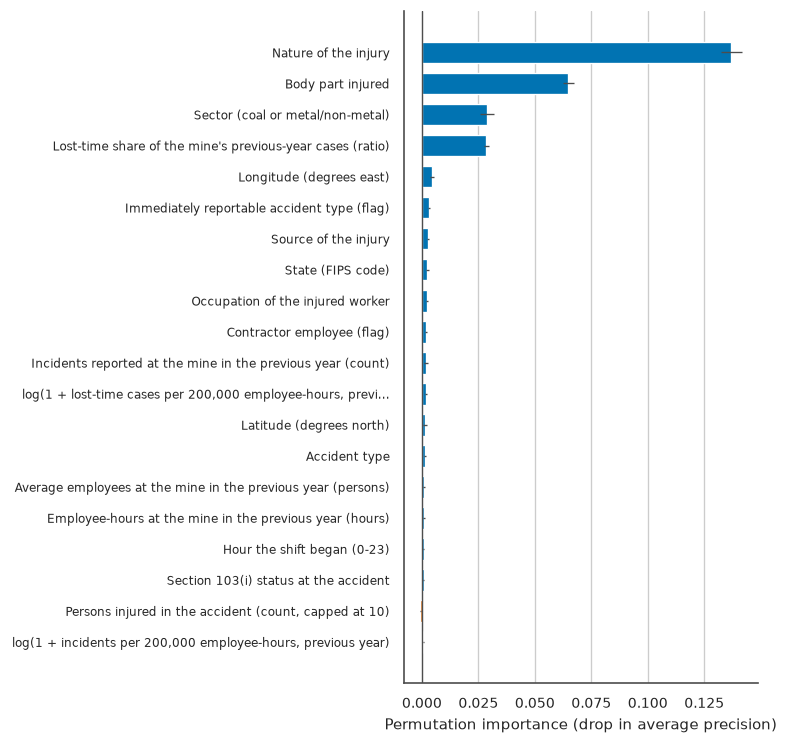

**logreg: largest coefficients**

,feature,coefficient,abs_coefficient,odds_ratio
0,NATURE_INJURY_CD_100,5.605,5.605,271.822
1,FIPS_STATE_CD_72,2.629,2.629,13.862
2,INJ_BODY_PART_CD_142,-2.421,2.421,0.089
3,FIPS_STATE_CD_15,1.781,1.781,5.936
4,NATURE_INJURY_CD_180,-1.555,1.555,0.211
5,INJURY_SOURCE_CD_049,-1.372,1.372,0.254
6,NATURE_INJURY_CD_320,-1.342,1.342,0.261
7,NATURE_INJURY_CD_260,1.248,1.248,3.485
8,ACCIDENT_TYPE_CD_36,-1.124,1.124,0.325
9,NATURE_INJURY_CD_310,-1.049,1.049,0.350


**logreg: largest coefficients of the numeric and binary inputs (read these first)**

,feature,coefficient,abs_coefficient,odds_ratio
12,immed_reportable,0.873,0.873,2.393
98,prev_lost_time_share,0.356,0.356,1.428
121,tot_exper_missing,0.329,0.329,1.390
226,prev_incidents,0.179,0.179,1.196
246,prev_employees,-0.166,0.166,0.847
323,prev_incident_rate_200k,-0.107,0.107,0.898
325,exper_inconsistent,0.104,0.104,1.109
328,longitude,0.103,0.103,1.108
348,is_contractor,-0.089,0.089,0.915
358,hours_into_shift_missing,0.083,0.083,1.087


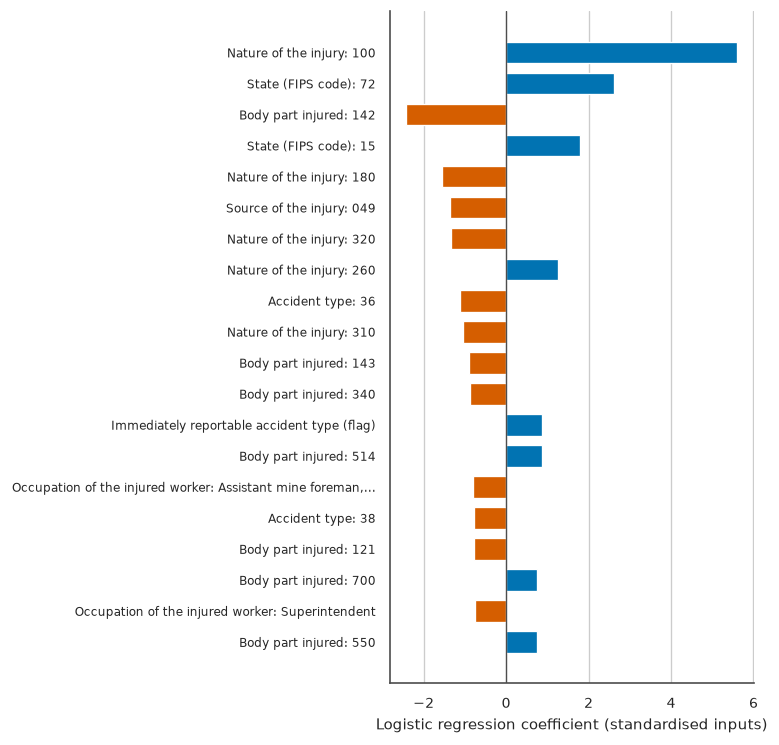

**Mean absolute SHAP value per transformed column (hist_gb; 500 test rows, stored by mlda-train)**

,feature,mean_abs_shap
0,NATURE_INJURY_CD_180,0.575
1,prev_lost_time_share,0.365
2,COAL_METAL_IND_C,0.350
3,INJ_BODY_PART_CD_340,0.206
4,longitude,0.082
5,NATURE_INJURY_CD_100,0.073
6,NATURE_INJURY_CD_220,0.068
7,INJ_BODY_PART_CD_130,0.067
8,INJ_BODY_PART_CD_142,0.059
9,prev_incidents,0.050


In [56]:
from mlda.explain import coefficient_table, permutation_importance_table

permutation_path = METRICS_DIR / f"permutation_importance_{best}.csv"
if permutation_path.exists():
    permutation = pd.read_csv(permutation_path)
    note(f"Permutation importance of `{best}` read from `{permutation_path.name}` (stored by mlda-train).")
else:
    with timer.stage("E.12 permutation importance"):
        permutation = permutation_importance_table(fitted[best], X_test, y_test, max_rows=3000, n_repeats=3, n_jobs=N_JOBS)
    note(f"Permutation importance of `{best}` computed here on 3,000 test rows (three repeats).")
show_table(permutation.head(15), "Permutation importance: drop in average precision when the input is shuffled")
show(plots.feature_importance(permutation.rename(columns={"importance_mean": "importance", "importance_std": "std"})),
     f"Bar chart of the permutation importance of the inputs of {best}")

for model_name in dict.fromkeys(["logreg", best]):
    if model_name not in fitted:
        continue
    table = coefficient_table(fitted[model_name])
    if table is None:
        continue
    kind = table.attrs.get("kind", "coefficient")
    show_table(table.head(15), f"{model_name}: largest {kind.replace('_', ' ')}s")
    if kind == "coefficient":
        numeric_only = table[table["feature"].isin(numeric_cols + binary_cols)]
        show_table(numeric_only.head(10), f"{model_name}: largest coefficients of the numeric and binary inputs (read these first)")
        show(plots.feature_importance(table.rename(columns={"coefficient": "importance"}), value_label="Logistic regression coefficient (standardised inputs)"),
             "Bar chart of the largest logistic regression coefficients")

shap_path = METRICS_DIR / f"shap_summary_{best}.csv"
if shap_path.exists():
    show_table(pd.read_csv(shap_path).head(10), f"Mean absolute SHAP value per transformed column ({best}; 500 test rows, stored by mlda-train)")

## E.13 Temporal split: train on 2010-2019, test on 2020-2025

The primary split is random over mine-years, so the test fold is drawn from the same years as
the training rows. A forecast, however, is always about the future. The temporal study repeats the
whole protocol on the accident years **before 2020** only (re-tuning, thresholds from out-of-fold
probabilities, model ranking) and scores 2020-2025 once, so nothing from the later period
influences any choice. It reports the two best models with the dated 103(i) status and the
immediate-notification flag included and removed, because those two inputs depend on how the form
was filled. A shift of the Brier score or of the specificity at the fixed operating threshold
points to **label drift** (the coal lost-time rate rises over the period while restricted-duty
coding falls; the yearly rates of the training rows are in section B.12), not only to a worse model.

In [57]:
variants_label = {
    "with_status_103i": "all inputs",
    "without_status_103i": "without the 103(i) status",
    "without_immed_reportable": "without immed_reportable",
}
temporal_rows = []
for model_name, entry in temporal["models"].items():
    for variant, label in variants_label.items():
        test = entry[variant]["test"]
        temporal_rows.append(
            {
                "model": model_name,
                "split and inputs": f"temporal 2020-2025, {label}",
                "ROC-AUC": test["at_0.5"]["roc_auc"],
                "PR-AUC": test["at_0.5"]["pr_auc"],
                "Brier": test["at_0.5"]["brier"],
                "recall at the operating threshold": test[f"at_{OPERATING_KEY}"]["recall"],
                "specificity at the operating threshold": test[f"at_{OPERATING_KEY}"]["specificity"],
                "Brier coal": entry[variant]["brier_by_sector"].get("C"),
                "Brier metal": entry[variant]["brier_by_sector"].get("M"),
            }
        )
    if model_name in evaluations:
        half = evaluations[model_name]["at_0.5"]
        sectors = evaluations[model_name]["by_sector"]["at_0.5"]
        temporal_rows.append(
            {
                "model": model_name,
                "split and inputs": "primary random split (section E.2)",
                "ROC-AUC": half["roc_auc"],
                "PR-AUC": half["pr_auc"],
                "Brier": half["brier"],
                "recall at the operating threshold": evaluations[model_name][f"at_{OPERATING_KEY}"]["recall"],
                "specificity at the operating threshold": evaluations[model_name][f"at_{OPERATING_KEY}"]["specificity"],
                "Brier coal": sectors["C"]["brier"],
                "Brier metal": sectors["M"]["brier"],
            }
        )
temporal_table = pd.DataFrame(temporal_rows).set_index(["model", "split and inputs"]).sort_index(level=0, sort_remaining=False)
show_table(temporal_table, "Temporal split against the primary split")
print(f"temporal split: {temporal['n_train']:,} training rows (prevalence {temporal['prevalence_train']:.3f}) and "
      f"{temporal['n_test']:,} test rows (prevalence {temporal['prevalence_test']:.3f})")
drift = temporal["level_drift"]
print(f"level drift: {drift['n_all_zero_in_test_period']} of {drift['n_onehot_columns']} one-hot columns are all zero in 2020-2025: {drift['columns']}")

lead = next(iter(temporal["models"]))
lead_entry = temporal["models"][lead]
temporal_roc = lead_entry["with_status_103i"]["test"]["at_0.5"]["roc_auc"]
spec_op = lead_entry["with_status_103i"]["test"][f"at_{OPERATING_KEY}"]["specificity"]
without_roc = lead_entry["without_status_103i"]["test"]["at_0.5"]["roc_auc"]
note(
    f"**Reading the table.** For `{lead}`, the temporal ROC-AUC is {temporal_roc:.3f}"
    + (f" against {evaluations[lead]['at_0.5']['roc_auc']:.3f} on the primary split" if lead in evaluations else "")
    + f"; with the operating threshold fixed on 2010-2019 data the specificity on 2020-2025 is {spec_op:.3f} (target 0.40). "
    f"Removing the 103(i) status changes the ROC-AUC to {without_roc:.3f} "
    + ("(a change under 0.01, so the result does not hinge on that dated input). " if abs(without_roc - temporal_roc) < 0.01 else "(a visible change, so that dated input matters). ")
    + f"The Brier score by sector ({lead_entry['with_status_103i']['brier_by_sector'].get('C', float('nan')):.3f} coal, "
    f"{lead_entry['with_status_103i']['brier_by_sector'].get('M', float('nan')):.3f} metal) shows where calibration is weaker. "
    f"The drift in the label is visible before any model is fitted: in the training rows the coal lost-time rate is {early.loc['C', 'lost_time']:.1%} in "
    f"{YEAR_MIN}-{YEAR_MIN + 2} and {late.loc['C', 'lost_time']:.1%} in {YEAR_MAX - 2}-{YEAR_MAX}, while the share of restricted-duty cases in coal falls from "
    f"{early.loc['C', 'restricted_duty']:.1%} to {late.loc['C', 'restricted_duty']:.1%}."
)

**Temporal split against the primary split**

ROC-AUC  PR-AUC  Brier  recall at the operating threshold  specificity at the operating threshold  Brier coal  Brier metal
model   split and inputs                                                                                                                                                         
hist_gb temporal 2020-2025, all inputs                   0.834   0.843  0.166                              0.944                                   0.377       0.125        0.187
        temporal 2020-2025, without the 103(i) status    0.833   0.842  0.166                              0.943                                   0.376       0.125        0.187
        temporal 2020-2025, without immed_reportable     0.832   0.841  0.167                              0.942                                   0.378       0.125        0.188
        primary random split (section E.2)               0.843   0.841  0.161                              0.943                                   0.403       0.135        0.179
mlp     temporal 2020-2025, all inputs                   0.825   0.834  0.173                              0.924                                   0.425       0.131        0.193
        temporal 2020-2025, without the 103(i) status    0.822   0.828  0.173                              0.955                                   0.321       0.127        0.196
        temporal 2020-2025, without immed_reportable     0.823   0.829  0.171                              0.958                                   0.313       0.132        0.191
        primary random split (section E.2)               0.839   0.837  0.163                              0.948                                   0.373       0.135        0.182

temporal split: 71,877 training rows (prevalence 0.482) and 29,732 test rows (prevalence 0.495)
level drift: 2 of 515 one-hot columns are all zero in 2020-2025: ['UG_LOCATION_CD_infrequent_sklearn', 'OCCUPATION_missing']


**Reading the table.** For `hist_gb`, the temporal ROC-AUC is 0.834 against 0.843 on the primary split; with the operating threshold fixed on 2010-2019 data the specificity on 2020-2025 is 0.377 (target 0.40). Removing the 103(i) status changes the ROC-AUC to 0.833 (a change under 0.01, so the result does not hinge on that dated input). The Brier score by sector (0.125 coal, 0.187 metal) shows where calibration is weaker. The drift in the label is visible before any model is fitted: in the training rows the coal lost-time rate is 58.5% in 2010-2012 and 68.0% in 2023-2025, while the share of restricted-duty cases in coal falls from 8.2% to 5.1%.

## E.14 Sensitivity analyses

Four questions about the **result's dependence on choices** are answered with the selected model.
(a) **Deterministic levels:** a level that is 100 % one class (here a nature-of-injury code) makes
rows trivially easy; removing those rows from the test fold shows how much of the score they
provide. `mlda-train` searched all in-scope rows for such levels; the cell repeats the search on
the training rows only and checks that it finds the same level, so no test label decides which
test rows the check removes. (b) **Altered inputs:** the model is refitted without the immediate-notification flag
(a near copy of the fatality code) and without the 103(i) status, with previous-year case counts
restricted to cases that were already resolved at the accident date, and with previous-year hours
blanked for forms filed before the fourth-quarter report was due. (c) **Grouping by mine:** the
primary split keeps mine-years together, but the same mine can appear on both sides. Splitting by
`MINE_ID` puts every mine on one side only and is the strictest test of generalisation to unseen
mines. A small change means the model has not learnt mine identities.

In [58]:
from mlda.sensitivity import pure_levels

sensitivity = json.loads((METRICS_DIR / "sensitivity.json").read_text(encoding="utf-8"))
show_table(pd.DataFrame(sensitivity["pure_levels"]["found"]), "Levels that are 100 % one class (at least 100 rows), searched on all rows")
training_levels = pure_levels(X_train, y_train)
show_table(training_levels, "The same search on the training rows only")
same_levels = sorted(zip(training_levels["column"], training_levels["level"], strict=True)) == sorted(
    (r["column"], r["level"]) for r in sensitivity["pure_levels"]["found"]
)
print(f"the training rows alone give the same deterministic levels as all rows: {same_levels}")

excluded = sensitivity["excluding_pure_levels"]
pure_rows = []
for model_name in [best, lookup]:
    if model_name not in excluded["models"]:
        continue
    entry = excluded["models"][model_name]
    for label, key in (("all test rows", "with_levels"), (f"without {', '.join(excluded['levels'])}", "without_levels"), ("difference", "delta")):
        pure_rows.append({"model": model_name, "test rows": label, **{k: entry[key][k] for k in ("roc_auc", "pr_auc", "brier", f"recall_at_{OPERATING_KEY}")}})
show_table(pd.DataFrame(pure_rows).set_index(["model", "test rows"]),
           f"Removing the deterministic level ({excluded['n_test_excluded']} of {excluded['n_test']:,} test rows)")

variants = sensitivity["primary_split_variants"]
variant_rows = [{"variant": "reference (selected model, primary split)", **variants["reference"]}]
for name, entry in variants["variants"].items():
    variant_rows.append({"variant": name.replace("_", " "), **entry["test"]})
variant_table = pd.DataFrame(variant_rows).set_index("variant")
show_table(variant_table[["roc_auc", "pr_auc", "brier", f"recall_at_{OPERATING_KEY}", f"specificity_at_{OPERATING_KEY}"]],
           "Altered inputs (the selected model refitted; hyper-parameters not re-tuned)")
with pd.option_context("display.max_colwidth", None):
    show_table(pd.DataFrame({"what changed": {k.replace("_", " "): v["description"] for k, v in variants["variants"].items()}}), "Description of each variant")

grouped = sensitivity["mine_grouped_split"]
grouped_table = pd.DataFrame(
    {
        "primary split (mine-years)": variants["reference"],
        "split grouped by mine": grouped["model"]["test"],
        "difference": grouped["model"]["delta_vs_primary"],
        "lookup rule, grouped by mine": grouped["lookup"]["test"],
    }
)
show_table(grouped_table, f"Split grouped by MINE_ID: {grouped['n_train']:,} training and {grouped['n_test']:,} test rows, {grouped['shared_mines']} mines on both sides")
passes = {}
for name, checks in {sensitivity["model"]: grouped["model"]["criteria"], lookup: grouped["lookup"]["criteria"]}.items():
    passes[name] = {key: checks[key]["pass"] for key in ("S1", "S2", "S3", "S4", "S5", "S6")}
    passes[name]["all passed"] = checks["all_pass"]
show_table(pd.DataFrame(passes).T, "Success criteria under the mine-grouped split (True = passed, None = not applicable)")

worst = max(variants["variants"].items(), key=lambda kv: abs(kv[1]["delta_vs_reference"]["roc_auc"]))
note(
    f"**Reading the tables.** Removing the deterministic level lowers the ROC-AUC of `{sensitivity['model']}` by "
    f"{abs(excluded['models'][sensitivity['model']]['delta']['roc_auc']):.3f}. The largest change among the altered inputs is "
    f"{worst[1]['delta_vs_reference']['roc_auc']:+.4f} ROC-AUC (`{worst[0].replace('_', ' ')}`). Grouping the split by mine moves the "
    f"ROC-AUC by {grouped['model']['delta_vs_primary']['roc_auc']:+.3f} and the recall at the operating point by "
    f"{grouped['model']['delta_vs_primary'][f'recall_at_{OPERATING_KEY}']:+.3f}"
    + (", a small change: most of the skill carries over to mines the model has not seen." if abs(grouped["model"]["delta_vs_primary"]["roc_auc"]) < 0.03
       else ", a large change: part of the skill comes from mines that appear in training.")
)

**Levels that are 100 % one class (at least 100 rows), searched on all rows**

,column,level,n,positives,positive_rate,documented
0,NATURE_INJURY_CD,100,925,925,1.000,True


**The same search on the training rows only**

,column,level,n,positives,positive_rate,documented
0,NATURE_INJURY_CD,100,750,750,1.000,True


the training rows alone give the same deterministic levels as all rows: True


**Removing the deterministic level (175 of 20,320 test rows)**

roc_auc  pr_auc  brier  recall_at_specificity_0.40
model                       test rows                                                                       
hist_gb                     all test rows                   0.843   0.841  0.161                       0.943
                            without NATURE_INJURY_CD=100    0.840   0.834  0.162                       0.942
                            difference                     -0.003  -0.007  0.001                      -0.001
lookup_nature_bodypart_coal all test rows                   0.804   0.790  0.179                       0.916
                            without NATURE_INJURY_CD=100    0.800   0.779  0.181                       0.914
                            difference                     -0.004  -0.011  0.002                      -0.002

**Altered inputs (the selected model refitted; hyper-parameters not re-tuned)**

,roc_auc,pr_auc,brier,recall_at_specificity_0.40,specificity_at_specificity_0.40
variant,,,,,
"reference (selected model, primary split)",0.843,0.841,0.161,0.943,0.403
without immed reportable,0.843,0.840,0.161,0.943,0.404
without status 103i,0.843,0.841,0.161,0.942,0.409
resolved lag counts,0.843,0.841,0.161,0.943,0.401
exposure blank if q4 incomplete,0.843,0.841,0.161,0.942,0.405


**Description of each variant**

,what changed
without immed reportable,immed_reportable set to 0 (the flag is a near copy of the death code)
without status 103i,status_103i_at_accident set to one constant level
resolved lag counts,previous-year case counts restricted to cases whose return-to-work date and closing document are earlier than the accident
exposure blank if q4 incomplete,previous-year hours and employees set to missing (and the mine type taken from the accident subunit) for forms filed on or before 15 January


**Split grouped by MINE_ID: 81,320 training and 20,289 test rows, 0 mines on both sides**

,primary split (mine-years),split grouped by mine,difference,"lookup rule, grouped by mine"
roc_auc,0.843,0.838,-0.005,0.798
pr_auc,0.841,0.836,-0.005,0.782
brier,0.161,0.164,0.003,0.182
recall_at_0.5,0.738,0.724,-0.014,0.647
specificity_at_0.5,0.785,0.797,0.013,0.795
recall_at_specificity_0.40,0.943,0.936,-0.007,0.911
specificity_at_specificity_0.40,0.403,0.410,0.007,0.409
recall_at_flag_rate_0.50,0.775,0.762,-0.013,0.710


**Success criteria under the mine-grouped split (True = passed, None = not applicable)**

,S1,S2,S3,S4,S5,S6,all passed
hist_gb,True,True,True,True,False,True,False
lookup_nature_bodypart_coal,False,True,False,None,False,True,False


**Reading the tables.** Removing the deterministic level lowers the ROC-AUC of `hist_gb` by 0.003. The largest change among the altered inputs is -0.0004 ROC-AUC (`resolved lag counts`). Grouping the split by mine moves the ROC-AUC by -0.005 and the recall at the operating point by -0.007, a small change: most of the skill carries over to mines the model has not seen.

# F. Deployment and reproducibility

The study is deployed as a multi-page **Streamlit** web app (`app/streamlit_app.py`, with the
pages in `app/pages/`). The app does no heavy work: `uv run mlda-train` precomputes the models,
the tables and the figures, and the committed artefacts feed the pages. Only the training page
fits models live, on a sample of at most 20,000 rows with three folds and a small grid. The
deployed address is given in the README ("see README"); the app also runs locally with
`uv run streamlit run app/streamlit_app.py` or in a container (`docker run -p 8501:8501 mlda-cw1`).

## F.1 How the artefacts feed the app

| Page | What the user does | Artefacts it reads |
|---|---|---|
| Data explorer | read how the sources are joined and the target is defined, filter a sample | `data/processed/base.parquet` |
| Exploratory analysis | descriptive statistics, correlations, missing values, distributions | `reports/metrics/eda_*.csv`, `data/processed/features.parquet` |
| Preprocessing | try imputer, scaler, encoder and outlier options on a sample | `mlda.preprocessing`, `data/processed/features.parquet`, `data/processed/split_indices.json` |
| Model training | tune one model live on a stratified sample (at most 20,000 rows, 3 folds, a reduced grid) | `mlda.tuning.tune`, `mlda.models.MODEL_ZOO`, `reports/metrics/cv_summary.csv` |
| Inference | predict one case, or a CSV of cases, and compare with the mine's history | `models/<name>.joblib`, `reports/metrics/thresholds.json`, `data/processed/mine_year_features.parquet`, `data/processed/mine_case_history.parquet` |
| Evaluation | comparison tables, curves, thresholds, success criteria, tests, importance | `reports/metrics/*.json`, `reports/metrics/*.csv`, `reports/predictions/test_predictions.parquet` |
| About | data card, licence, run manifest, limitations | `models/manifest.json`, `reports/metrics/run_manifest.json` |

The last column is the contract between training and deployment: the pages read these files and
do no heavy work of their own (the training page is the one exception), so the notebook, the
report and the app show the same numbers. The first cell lists the pages registered in
`app/streamlit_app.py`; the second lists the artefacts, with their size.

In [59]:
import re

entrypoint = (PROJECT_ROOT / "app" / "streamlit_app.py").read_text(encoding="utf-8")
registered = re.findall(r'st\.Page\(\s*"([^"]+)",\s*title="([^"]+)"', entrypoint)
page_table = pd.DataFrame(registered, columns=["page file", "title in the navigation"])
page_table["file exists"] = [(PROJECT_ROOT / "app" / path).exists() for path in page_table["page file"]]
show_table(page_table, "Pages registered in app/streamlit_app.py")
assert page_table["file exists"].all() and len(page_table) >= 5

**Pages registered in app/streamlit_app.py**

,page file,title in the navigation,file exists
0,pages/1_Data_Explorer.py,Data explorer,True
1,pages/2_EDA.py,Exploratory analysis,True
2,pages/3_Preprocessing.py,Preprocessing,True
3,pages/4_Model_Training.py,Model training,True
4,pages/5_Inference.py,Inference,True
5,pages/6_Evaluation.py,Evaluation,True
6,pages/7_About.py,About,True


In [60]:
from mlda.config import FIGURES_DIR, MODELS_DIR

artefacts = [
    PROCESSED_DIR / "base.parquet", PROCESSED_DIR / "features.parquet", PROCESSED_DIR / "split_indices.json",
    PROCESSED_DIR / "mine_year_features.parquet", PROCESSED_DIR / "mine_case_history.parquet",
    METRICS_DIR / "comparison.csv", METRICS_DIR / "comparison_operating_point.csv", METRICS_DIR / "cv_summary.csv",
    METRICS_DIR / "thresholds.json", METRICS_DIR / "success_criteria.json", METRICS_DIR / "statistical_tests.json",
    METRICS_DIR / "temporal_split.json", METRICS_DIR / "sensitivity.json", METRICS_DIR / "baselines.json",
    METRICS_DIR / "explanations.json", METRICS_DIR / "error_rules.csv", METRICS_DIR / "run_manifest.json",
    PREDICTIONS_DIR / "test_predictions.parquet", PREDICTIONS_DIR / "oof_predictions.parquet", MODELS_DIR / "manifest.json",
    *[MODELS_DIR / f"{name}.joblib" for name in MODEL_ZOO],
    *[CV_DIR / f"{name}_cv_results.csv" for name in MODEL_ZOO],
    *sorted(FIGURES_DIR.glob("F*.png")),
]
inventory = pd.DataFrame(
    {
        "artefact": [str(p.relative_to(PROJECT_ROOT)).replace("\\", "/") for p in artefacts],
        "exists": [p.exists() for p in artefacts],
        "size (kB)": [round(p.stat().st_size / 1e3, 1) if p.exists() else None for p in artefacts],
    }
).set_index("artefact")
print(f"{int(inventory['exists'].sum())} of {len(inventory)} artefacts present; "
      f"models total {sum(p.stat().st_size for p in MODELS_DIR.glob('*.joblib')) / 1e6:.1f} MB")
missing_artefacts = inventory[~inventory["exists"]]
if len(missing_artefacts):
    show_table(missing_artefacts, "Artefacts that are missing (run `uv run mlda-train`)")
with pd.option_context("display.max_rows", 80):
    show_table(inventory.head(25), "Artefacts read by the app (first 25)")

56 of 56 artefacts present; models total 28.2 MB


**Artefacts read by the app (first 25)**

,exists,size (kB)
artefact,,
data/processed/base.parquet,True,"7,282.900"
data/processed/features.parquet,True,"5,885.600"
data/processed/split_indices.json,True,701.900
data/processed/mine_year_features.parquet,True,"1,107.100"
data/processed/mine_case_history.parquet,True,969.000
reports/metrics/comparison.csv,True,1.900
reports/metrics/comparison_operating_point.csv,True,3.200
reports/metrics/cv_summary.csv,True,2.600
reports/metrics/thresholds.json,True,3.600


## F.2 The manifest: versions, commit and data checksum

Pickled scikit-learn models are only guaranteed to load under the library version that wrote them,
and a model is only reproducible if the code and the data are known. `models/manifest.json`
therefore records, for each saved model, the Python and library versions, the git commit, a digest
of the pinned raw-data snapshot, the time it was saved and the selected parameters. The app reads
the same file on its "About" page. The cell checks the recorded environment against the one running
this notebook and the recorded data digest against the files on disk.

In [61]:
from mlda.persistence import data_checksum

manifest = read_manifest()
manifest_table = pd.DataFrame(
    {
        name: {
            "estimator": entry["estimator"],
            "python": entry["python_version"],
            "scikit-learn": entry["sklearn_version"],
            "pandas": entry["pandas_version"],
            "git commit": (entry["git_sha"] or "n/a")[:10],
            "data digest": (entry["data_checksum"] or "n/a")[:12],
            "saved (UTC)": entry["saved_at_utc"],
            "file (MB)": entry["size_bytes"] / 1e6,
            "quick run": entry["extra"].get("quick"),
        }
        for name, entry in manifest.items()
    }
).T
show_table(manifest_table, "models/manifest.json")

live_digest = data_checksum()["sha256"]
print("digest of the raw files on disk:", live_digest[:12], "| manifest entries with the same digest:",
      sum(entry["data_checksum"] == live_digest for entry in manifest.values()), "of", len(manifest))
print("scikit-learn installed:", sklearn.__version__, "| manifest entries from the same version:",
      sum(entry["sklearn_version"] == sklearn.__version__ for entry in manifest.values()), "of", len(manifest))

commits = {}
for name, entry in manifest.items():
    commits.setdefault((entry["git_sha"] or "n/a")[:10], []).append(name)
if len(commits) > 1:
    detail = "; ".join(f"`{sha}`: {', '.join(names)}" for sha, names in commits.items())
    same_inputs = len({e["data_checksum"] for e in manifest.values()}) == 1 and len({e["sklearn_version"] for e in manifest.values()}) == 1
    note(
        f"**Why the commit column is not constant.** `models/manifest.json` stores the commit that was checked out when each model was saved ({detail}). "
        "A commit made between two saves of one `mlda-train` run therefore gives that run more than one commit. "
        + ("The data digest and the scikit-learn version are the same for every model, so all models were fitted on the same data with the same library."
           if same_inputs else "The data digest or the library version also differs between models, so check which models were fitted together.")
    )
else:
    note(f"Every model was saved at the same commit (`{next(iter(commits))}`).")

run_manifest = json.loads((METRICS_DIR / "run_manifest.json").read_text(encoding="utf-8"))
print(f"mlda-train: quick={run_manifest['quick']}, {run_manifest['cv_folds']} folds, {run_manifest['n_jobs']} workers, "
      f"{run_manifest['total_seconds'] / 60:.1f} minutes in total; best model by cross-validation: {run_manifest['best_model']}")
stage_seconds = pd.DataFrame({"seconds": run_manifest["stage_seconds"]})
show_table(stage_seconds, "Wall-clock time of each stage of mlda-train")

**models/manifest.json**

,estimator,python,scikit-learn,pandas,git commit,data digest,saved (UTC),file (MB),quick run
decision_tree,DecisionTreeClassifier,3.12.15,1.9.1,2.3.3,56c4c03251,797016b4aac2,2026-10-14T16:42:11+00:00,0.032,False
gaussian_nb,GaussianNB,3.12.15,1.9.1,2.3.3,56c4c03251,797016b4aac2,2026-10-14T16:39:29+00:00,0.019,False
hist_gb,HistGradientBoostingClassifier,3.12.15,1.9.1,2.3.3,56c4c03251,797016b4aac2,2026-10-14T16:54:13+00:00,0.449,False
knn,KNeighborsClassifier,3.12.15,1.9.1,2.3.3,56c4c03251,797016b4aac2,2026-10-14T16:38:59+00:00,5.227,False
logreg,LogisticRegression,3.12.15,1.9.1,2.3.3,ee0209d2a1,797016b4aac2,2026-10-14T16:34:14+00:00,0.014,False
mlp,MLPClassifier,3.12.15,1.9.1,2.3.3,56c4c03251,797016b4aac2,2026-10-14T17:18:01+00:00,0.810,False
random_forest,RandomForestClassifier,3.12.15,1.9.1,2.3.3,56c4c03251,797016b4aac2,2026-10-14T16:44:33+00:00,20.369,False
svc_rbf,CalibratedClassifierCV,3.12.15,1.9.1,2.3.3,56c4c03251,797016b4aac2,2026-10-14T17:14:52+00:00,1.247,False


digest of the raw files on disk: 797016b4aac2 | manifest entries with the same digest: 8 of 8
scikit-learn installed: 1.9.1 | manifest entries from the same version: 8 of 8


**Why the commit column is not constant.** `models/manifest.json` stores the commit that was checked out when each model was saved (`56c4c03251`: decision_tree, gaussian_nb, hist_gb, knn, mlp, random_forest, svc_rbf; `ee0209d2a1`: logreg). A commit made between two saves of one `mlda-train` run therefore gives that run more than one commit. The data digest and the scikit-learn version are the same for every model, so all models were fitted on the same data with the same library.

mlda-train: quick=False, 5 folds, 8 workers, 94.6 minutes in total; best model by cross-validation: hist_gb


**Wall-clock time of each stage of mlda-train**

,seconds
load_and_clean,0.600
features_and_split,8.940
eda,19.650
baselines,15.250
model_logreg,71.380
model_knn,285.170
model_gaussian_nb,29.550
model_decision_tree,161.620
model_random_forest,142.160
model_hist_gb,580.790


## F.3 Reproducibility checklist

| Requirement | How it is met |
|---|---|
| Same software | `uv.lock` pins every package; `uv sync --locked --all-groups` recreates the environment; `requirements.txt` is exported from the lock for `pip`; the `Dockerfile` builds the app with uv |
| Same data | `mlda.config.SOURCES` pins the SHA-256 of every raw file; `uv run mlda-download` refuses a file whose hash differs; the snapshot is recorded in `data/raw/SNAPSHOT.json` |
| Same random numbers | `RANDOM_STATE = 42` seeds the split, the cross-validation, every stochastic estimator, the bootstrap and the sampling |
| Same split | the row indices of the split are stored in `data/processed/split_indices.json` and rebuilt from the seed in section C.8 to confirm that they agree |
| Same results | `uv run mlda-train` rewrites the models, tables and figures; this notebook recomputes the tables and refits the models and prints where they differ from the stored ones |
| Traceable models | `models/manifest.json` records versions, git commit and data digest for every model (F.2) |
| Tested | `uv run pytest` runs the unit tests, the quick end-to-end run and this notebook (marked slow); CI repeats them on Ubuntu and Windows |

```
uv sync --locked --all-groups
uv run mlda-download
uv run mlda-train
uv run python notebooks/build_notebook.py
uv run jupyter nbconvert --to notebook --execute --inplace notebooks/01_end_to_end.ipynb
uv run jupyter nbconvert --to html notebooks/01_end_to_end.ipynb
uv run pytest
uv run streamlit run app/streamlit_app.py
```

## F.4 Limitations

- **The label depends on practice, not only on the injury.** The line between lost time and
  restricted duty depends on whether the operator offers light duty, which differs between coal and
  metal/non-metal mines and has changed over the period. The model is suited to reserving and
  return-to-work planning, where that line has a financial meaning, and not to ranking hazards.
- **History needs the mine's previous year.** For 1.2 % of cases there is no previous-year
  production, and the history features are imputed and flagged. A mine that is new has no history.
- **Several mine attributes are undated.** The safety-committee flag, the Part 48 training flag and
  the portable-operation flag describe the mine at the snapshot, not at the accident. They are
  model inputs; the cell after this list measures how much they contribute.
- **The cost ratio is an assumption** (USD 4,000 for a missed case against USD 200 for a review);
  that is why the cost analysis covers 2:1 to 30:1 and why the capacity operating point, not the cost
  optimum, is the headline.
- **Dependence between rows.** Rows from one mine-year are not independent; the split, the
  cross-validation, McNemar's test and the bootstrap all group by mine-year for that reason.

In [62]:
snapshot_flags = ["SAFETY_COMMITTEE_IND", "PART48_TRAINING", "PORTABLE_OPERATION"]
flag_importance = permutation.set_index("feature").loc[snapshot_flags, ["importance_mean", "importance_std"]]
show_table(flag_importance.map("{:.5f}".format), f"Permutation importance of the three undated snapshot flags ({best}; drop in average precision when the input is shuffled)")
largest = float(flag_importance["importance_mean"].abs().max())
note(
    f"The largest importance among the three flags is {largest:.5f} in average precision, against {permutation['importance_mean'].iloc[0]:.3f} for the most "
    f"important input (`{permutation['feature'].iloc[0]}`), so the undated flags "
    + ("do not drive the predictions." if largest < 0.001 else "carry weight in the predictions and are a limitation.")
)

**Permutation importance of the three undated snapshot flags (hist_gb; drop in average precision when the input is shuffled)**

,importance_mean,importance_std
feature,,
SAFETY_COMMITTEE_IND,0.00034,0.00013
PART48_TRAINING,0.00012,0.00008
PORTABLE_OPERATION,-0.00009,0.00003


The largest importance among the three flags is 0.00034 in average precision, against 0.137 for the most important input (`NATURE_INJURY_CD`), so the undated flags do not drive the predictions.

## F.5 Licence, data citation and deployed address

**Code.** MIT licence (`LICENSE` in the repository root).

**Data.** Mine Safety and Health Administration (MSHA), US Department of Labor, *Open Government
Data Sets: Accidents, Mines and MinesProdYearly*, https://arlweb.msha.gov/OpenGovernmentData/DataSets/,
files published 9 October 2026 and retrieved 14 October 2026 (hashes in `data/raw/SNAPSHOT.json`).
The files are works of the United States federal government and carry no copyright in the United
States (17 U.S.C. 105); the data card in `data/README.md` lists the sources, the join keys and the
target definition.

**Deployed app.** see README.

In [63]:
licence_text = (PROJECT_ROOT / "LICENSE").read_text(encoding="utf-8").splitlines()
print("LICENSE:", licence_text[0])
print("data card present:", (PROJECT_ROOT / "data" / "README.md").exists())

LICENSE: MIT License
data card present: True


## F.6 Run time of this notebook

The stages that took at least five seconds, and the wall-clock time of the whole run. In the
default mode the live searches of section D.1, the refits of section D.3 and the scoring of
section E.1 dominate; the SVM is the slowest model to refit and to score. `FULL_RUN=1` adds the hyper-parameter searches (about an hour).

In [64]:
stage_table = pd.DataFrame({"seconds": timer.seconds})
stage_table["minutes"] = stage_table["seconds"] / 60
slow = stage_table[stage_table["seconds"] >= 5].sort_values("seconds", ascending=False)
show_table(slow, "Stages of this notebook that took at least 5 seconds")
elapsed = time.perf_counter() - NOTEBOOK_STARTED
print(f"wall-clock time of the notebook up to this cell: {elapsed:.0f} s ({elapsed / 60:.1f} minutes); FULL_RUN = {FULL_RUN}")

**Stages of this notebook that took at least 5 seconds**

,seconds,minutes
D.1 tune svc_rbf,"1,266.440",21.107
D.1 tune hist_gb,549.730,9.162
D.1 tune knn,294.060,4.901
D.1 tune mlp,152.130,2.535
D.1 tune decision_tree,148.910,2.482
D.1 tune random_forest,138.910,2.315
D.1 tune logreg,67.260,1.121
D.1 tune gaussian_nb,26.700,0.445
E.1 score the test fold,13.930,0.232
A.2 load the three tables,8.870,0.148


wall-clock time of the notebook up to this cell: 2737 s (45.6 minutes); FULL_RUN = True
